## Open SOVGDP file

In [1]:
import pandas as pd

df_GDP = pd.read_excel("SOVGDP - EUR2020 - GDP per capita at constant prices - NUTS_2021.xlsx")

print(df_GDP.head())

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


        NUTS                                       Name     1980     1981  \
0  EU27_2020  European Union - 27 countries (from 2020)      NaN      NaN   
1         AT                                    Austria  24900.0  24800.0   
2        AT1                              Ostösterreich  26300.0  26000.0   
3       AT11                                 Burgenland  14900.0  15100.0   
4      AT111                           Mittelburgenland  13000.0  13300.0   

      1982     1983     1984     1985     1986     1987  ...     2018  \
0      NaN      NaN      NaN      NaN      NaN      NaN  ...  31700.0   
1  25300.0  26100.0  26100.0  26800.0  27400.0  27700.0  ...  45100.0   
2  27000.0  28200.0  28400.0  28800.0  30000.0  30800.0  ...  44500.0   
3  15400.0  15200.0  15300.0  15400.0  16100.0  16300.0  ...  31400.0   
4  13500.0  13300.0  13400.0  13500.0  14200.0  14500.0  ...  27100.0   

      2019     2020     2021     2022     2023     2024     2025     2026  \
0  32300.0  30400.0  

### Formating the dataframe

In [2]:
year_cols = [col for col in df_GDP.columns if str(col).isdigit()]
year_cols

[1980,
 1981,
 1982,
 1983,
 1984,
 1985,
 1986,
 1987,
 1988,
 1989,
 1990,
 1991,
 1992,
 1993,
 1994,
 1995,
 1996,
 1997,
 1998,
 1999,
 2000,
 2001,
 2002,
 2003,
 2004,
 2005,
 2006,
 2007,
 2008,
 2009,
 2010,
 2011,
 2012,
 2013,
 2014,
 2015,
 2016,
 2017,
 2018,
 2019,
 2020,
 2021,
 2022,
 2023,
 2024,
 2025,
 2026,
 2027]

In [3]:
df_long_GDP = pd.melt(
    df_GDP,
    id_vars=[col for col in df_GDP.columns if col not in year_cols],  # keep non-year columns
    value_vars=year_cols,
    var_name="Year",
    value_name="GDP_per_capita"
)

df_long_GDP

,NUTS,Name,Year,GDP_per_capita
0,EU27_2020,European Union - 27 countries (from 2020),1980,NaN
1,AT,Austria,1980,24900.0
2,AT1,Ostösterreich,1980,26300.0
3,AT11,Burgenland,1980,14900.0
4,AT111,Mittelburgenland,1980,13000.0
...,...,...,...,...
77227,SK041,Presovský kraj,2027,12000.0
77228,SK042,Kosický kraj,2027,16500.0
77229,SKZ,Extra-Regio,2027,NaN
77230,SKZZ,Extra-Regio,2027,NaN


In [4]:
df_sovgdp = df_long_GDP.copy()

df_sovgdp = df_sovgdp[
    (df_sovgdp["NUTS"].str.len() == 4) &
    (~df_sovgdp["NUTS"].str.endswith(("Z", "ZZ", "ZZZ")))
].copy()
df_sovgdp

,NUTS,Name,Year,GDP_per_capita
3,AT11,Burgenland,1980,14900.0
7,AT12,Niederösterreich,1980,18800.0
15,AT13,Wien,1980,35400.0
18,AT21,Kärnten,1980,21500.0
22,AT22,Steiermark,1980,20900.0
...,...,...,...,...
77207,SI04,Zahodna Slovenija,2027,32800.0
77217,SK01,Bratislavský kraj,2027,41000.0
77219,SK02,Západné Slovensko,2027,18700.0
77223,SK03,Stredné Slovensko,2027,16500.0


In [5]:
df_sovgdp["Year"] = pd.to_numeric(df_sovgdp["Year"], errors="coerce")
df_sovgdp = df_sovgdp[df_sovgdp["Year"].between(2000, 2019)]

In [6]:
df_sovgdp

,NUTS,Name,Year,GDP_per_capita
32183,AT11,Burgenland,2000,25400.0
32187,AT12,Niederösterreich,2000,31300.0
32195,AT13,Wien,2000,52000.0
32198,AT21,Kärnten,2000,31900.0
32202,AT22,Steiermark,2000,33100.0
...,...,...,...,...
64335,SI04,Zahodna Slovenija,2019,28000.0
64345,SK01,Bratislavský kraj,2019,39000.0
64347,SK02,Západné Slovensko,2019,16300.0
64351,SK03,Stredné Slovensko,2019,14500.0


In [7]:
df_sovgdp["country"] = df_sovgdp["NUTS"].str[:2]

In [8]:
df_sovgdp

,NUTS,Name,Year,GDP_per_capita,country
32183,AT11,Burgenland,2000,25400.0,AT
32187,AT12,Niederösterreich,2000,31300.0,AT
32195,AT13,Wien,2000,52000.0,AT
32198,AT21,Kärnten,2000,31900.0,AT
32202,AT22,Steiermark,2000,33100.0,AT
...,...,...,...,...,...
64335,SI04,Zahodna Slovenija,2019,28000.0,SI
64345,SK01,Bratislavský kraj,2019,39000.0,SK
64347,SK02,Západné Slovensko,2019,16300.0,SK
64351,SK03,Stredné Slovensko,2019,14500.0,SK


## Base Features

### rd_e_gerdreg

#### From Eurostat - it measures R&D expenditure at NUTS2 regional level (%GDP)

#### Measures total intramural R&D expenditure performed within each region

#### Captures regional innovation capacity and knowledge production

#### Core driver of regional innovation and economic performance

In [9]:
import pandas as pd

df_rd_e = pd.read_excel("rd_e_gerdreg__custom_21032807_spreadsheet.xlsx")

print(df_rd_e.head())

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


  Data extracted on 16/04/2026 17:58:56 from [ESTAT]  \
0                                          Dataset:    
1                                     Last updated:    
2                                                NaN   
3                                     Time frequency   
4                              Sector of performance   

                                          Unnamed: 1   Unnamed: 2 Unnamed: 3  \
0  GERD by sector of performance and NUTS 2 regio...          NaN        NaN   
1                                   18/03/2026 23:00          NaN        NaN   
2                                                NaN          NaN        NaN   
3                                                NaN       Annual        NaN   
4                                                NaN  All sectors        NaN   

  Unnamed: 4 Unnamed: 5 Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9  ...  \
0        NaN        NaN        NaN        NaN        NaN        NaN  ...   
1        NaN        NaN       

In [10]:
df_rd_e = pd.read_excel(
    "rd_e_gerdreg__custom_21032807_spreadsheet.xlsx",
    header=9
)
df_rd_e

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,GEO (Codes),GEO (Labels),Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41
0,BE,Belgium,1.94,NaN,2.03,NaN,1.9,NaN,1.84,NaN,...,2.43,NaN,2.53,NaN,2.68,NaN,2.86,NaN,3.15,NaN
1,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,:,NaN,:,NaN,1.21,NaN,1.15,NaN,...,1.7,NaN,1.9,NaN,2.04,NaN,2.25,NaN,2.33,NaN
2,BE21,Prov. Antwerpen,:,NaN,:,NaN,:,NaN,:,NaN,...,3.12,NaN,3.24,NaN,3.45,NaN,:,C,:,C
3,BE22,Prov. Limburg (BE),:,NaN,:,NaN,:,NaN,:,NaN,...,1.36,NaN,1.49,NaN,1.58,NaN,:,C,:,C
4,BE23,Prov. Oost-Vlaanderen,:,NaN,:,NaN,:,NaN,:,NaN,...,2.49,NaN,2.73,NaN,2.7,NaN,:,C,:,C
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,d,definition differs (see metadata),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
295,e,estimated,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
296,p,provisional,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
297,Confidentiality flags:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Cleaner Approach

In [11]:
import pandas as pd

file = "rd_e_gerdreg__custom_21032807_spreadsheet.xlsx"

# Read raw sheet
df_raw = pd.read_excel(file, header=None)

# Build column names from the row that contains the years
years_row = df_raw.iloc[8]

columns = ["NUTS", "Name"]  # first two columns
for i in range(2, len(years_row)):
    if pd.notna(years_row[i]):
        columns.append(str(int(years_row[i])))   # value column
    else:
        columns.append(f"flag_{columns[-1]}")    # flag column after each year

# Assign columns and keep data rows only
df_rd_e = df_raw.iloc[10:].copy()
df_rd_e.columns = columns

print(df_rd_e.head())

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


    NUTS                                               Name  2000 flag_2000  \
10    BE                                            Belgium  1.94       NaN   
11  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...     :       NaN   
12  BE21                                    Prov. Antwerpen     :       NaN   
13  BE22                                 Prov. Limburg (BE)     :       NaN   
14  BE23                              Prov. Oost-Vlaanderen     :       NaN   

    2001 flag_2001  2002 flag_2002  2003 flag_2003  ...  2015 flag_2015  2016  \
10  2.03       NaN   1.9       NaN  1.84       NaN  ...  2.43       NaN  2.53   
11     :       NaN  1.21       NaN  1.15       NaN  ...   1.7       NaN   1.9   
12     :       NaN     :       NaN     :       NaN  ...  3.12       NaN  3.24   
13     :       NaN     :       NaN     :       NaN  ...  1.36       NaN  1.49   
14     :       NaN     :       NaN     :       NaN  ...  2.49       NaN  2.73   

   flag_2016  2017 flag_2017  2018 fla

#### Keep only the actual year columns

In [12]:
year_cols = [str(year) for year in range(2000, 2020)]

df_rd_e = df_rd_e[["NUTS", "Name"] + year_cols]

print(df_rd_e.head())

    NUTS                                               Name  2000  2001  2002  \
10    BE                                            Belgium  1.94  2.03   1.9   
11  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...     :     :  1.21   
12  BE21                                    Prov. Antwerpen     :     :     :   
13  BE22                                 Prov. Limburg (BE)     :     :     :   
14  BE23                              Prov. Oost-Vlaanderen     :     :     :   

    2003  2004  2005  2006  2007  ...  2010  2011  2012  2013  2014  2015  \
10  1.84  1.82  1.79  1.82  1.85  ...  2.06  2.16  2.27  2.32  2.36  2.43   
11  1.15  1.14  1.11  1.37  1.33  ...  1.36  1.34   1.4  1.47  1.62   1.7   
12     :     :     :   2.2  2.13  ...  2.46  2.66  2.66  2.68  3.02  3.12   
13     :     :     :  0.92  1.06  ...  1.03  1.17  1.22   1.3  1.32  1.36   
14     :     :     :  1.81  1.86  ...   2.2  2.27  2.57  2.68   2.5  2.49   

    2016  2017  2018  2019  
10  2.53  2.68  2.86 

#### Remove the footer rows

In [13]:
df_rd_e = df_rd_e[df_rd_e["NUTS"].notna()]
df_rd_e = df_rd_e[~df_rd_e["NUTS"].isin(["d", "e", "p", "Confidentiality flags:"])]

In [14]:
df_rd_e

,NUTS,Name,2000,2001,2002,2003,2004,2005,2006,2007,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
10,BE,Belgium,1.94,2.03,1.9,1.84,1.82,1.79,1.82,1.85,...,2.06,2.16,2.27,2.32,2.36,2.43,2.53,2.68,2.86,3.15
11,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,:,:,1.21,1.15,1.14,1.11,1.37,1.33,...,1.36,1.34,1.4,1.47,1.62,1.7,1.9,2.04,2.25,2.33
12,BE21,Prov. Antwerpen,:,:,:,:,:,:,2.2,2.13,...,2.46,2.66,2.66,2.68,3.02,3.12,3.24,3.45,:,:
13,BE22,Prov. Limburg (BE),:,:,:,:,:,:,0.92,1.06,...,1.03,1.17,1.22,1.3,1.32,1.36,1.49,1.58,:,:
14,BE23,Prov. Oost-Vlaanderen,:,:,:,:,:,:,1.81,1.86,...,2.2,2.27,2.57,2.68,2.5,2.49,2.73,2.7,:,:
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
300,:,not available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
301,Observation flags:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
302,be,"break in time series, estimated",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
303,b,break in time series,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Getting the NUTS 2 regions on the dataframe

In [15]:
df_rd_e = df_rd_e[
    df_rd_e["NUTS"].str.len() == 4
]
df_rd_e

,NUTS,Name,2000,2001,2002,2003,2004,2005,2006,2007,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
11,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,:,:,1.21,1.15,1.14,1.11,1.37,1.33,...,1.36,1.34,1.4,1.47,1.62,1.7,1.9,2.04,2.25,2.33
12,BE21,Prov. Antwerpen,:,:,:,:,:,:,2.2,2.13,...,2.46,2.66,2.66,2.68,3.02,3.12,3.24,3.45,:,:
13,BE22,Prov. Limburg (BE),:,:,:,:,:,:,0.92,1.06,...,1.03,1.17,1.22,1.3,1.32,1.36,1.49,1.58,:,:
14,BE23,Prov. Oost-Vlaanderen,:,:,:,:,:,:,1.81,1.86,...,2.2,2.27,2.57,2.68,2.5,2.49,2.73,2.7,:,:
15,BE24,Prov. Vlaams-Brabant,:,:,:,:,:,:,3.04,3.14,...,3.72,3.69,3.94,3.98,4.16,4.22,4,4.21,:,:
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,SE22,Sydsverige,:,:,:,3.92,:,4.12,:,4.43,...,:,4.2,:,3.75,:,3.19,:,3.18,:,3.64
294,SE23,Västsverige,:,:,:,5.53,:,5.05,:,3.5,...,:,3.71,:,3.59,:,3.75,:,4.81,:,5.11
295,SE31,Norra Mellansverige,:,:,:,1.28,:,1.29,:,1.52,...,:,1.04,:,1.34,:,1.29,:,1.21,:,1.27
296,SE32,Mellersta Norrland,:,:,:,0.48,:,0.85,:,0.73,...,:,0.82,:,0.79,:,0.74,:,:,:,:


#### Convert years columns into a single Year column

In [16]:
# Step 1: identify year columns

year_cols = [col for col in df_rd_e.columns if str(col).isdigit()]

year_cols

['2000',
 '2001',
 '2002',
 '2003',
 '2004',
 '2005',
 '2006',
 '2007',
 '2008',
 '2009',
 '2010',
 '2011',
 '2012',
 '2013',
 '2014',
 '2015',
 '2016',
 '2017',
 '2018',
 '2019']

In [17]:
# Step 2: reshape with melt()

df_rd_e_long = pd.melt(
    df_rd_e,
    id_vars=["NUTS", "Name"],   # columns to keep
    value_vars=year_cols,       # years
    var_name="Year",
    value_name="GERD"
)

df_rd_e_long

,NUTS,Name,Year,GERD
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,:
1,BE21,Prov. Antwerpen,2000,:
2,BE22,Prov. Limburg (BE),2000,:
3,BE23,Prov. Oost-Vlaanderen,2000,:
4,BE24,Prov. Vlaams-Brabant,2000,:
...,...,...,...,...
5215,SE22,Sydsverige,2019,3.64
5216,SE23,Västsverige,2019,5.11
5217,SE31,Norra Mellansverige,2019,1.27
5218,SE32,Mellersta Norrland,2019,:


In [18]:
# Step 3: clean types

df_rd_e_long["Year"] = df_rd_e_long["Year"].astype(int)
df_rd_e_long["GERD"] = pd.to_numeric(df_rd_e_long["GERD"], errors="coerce")

df_rd_e_long

,NUTS,Name,Year,GERD
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,NaN
1,BE21,Prov. Antwerpen,2000,NaN
2,BE22,Prov. Limburg (BE),2000,NaN
3,BE23,Prov. Oost-Vlaanderen,2000,NaN
4,BE24,Prov. Vlaams-Brabant,2000,NaN
...,...,...,...,...
5215,SE22,Sydsverige,2019,3.64
5216,SE23,Västsverige,2019,5.11
5217,SE31,Norra Mellansverige,2019,1.27
5218,SE32,Mellersta Norrland,2019,NaN


In [19]:
df_rd_e_long.head()

,NUTS,Name,Year,GERD
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,NaN
1,BE21,Prov. Antwerpen,2000,NaN
2,BE22,Prov. Limburg (BE),2000,NaN
3,BE23,Prov. Oost-Vlaanderen,2000,NaN
4,BE24,Prov. Vlaams-Brabant,2000,NaN


In [20]:
df_rd_e_long.describe()

,Year,GERD
count,5220.000000,2848.000000
mean,2009.500000,1.267816
std,5.766834,1.154770
min,2000.000000,0.000000
25%,2004.750000,0.490000
50%,2009.500000,0.960000
75%,2014.250000,1.602500
max,2019.000000,12.210000


In [21]:
df_rd_e_long["GERD"].isna().sum()

np.int64(2372)

In [22]:
df_rd_expenditure = df_rd_e_long
df_rd_expenditure

,NUTS,Name,Year,GERD
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,NaN
1,BE21,Prov. Antwerpen,2000,NaN
2,BE22,Prov. Limburg (BE),2000,NaN
3,BE23,Prov. Oost-Vlaanderen,2000,NaN
4,BE24,Prov. Vlaams-Brabant,2000,NaN
...,...,...,...,...
5215,SE22,Sydsverige,2019,3.64
5216,SE23,Västsverige,2019,5.11
5217,SE31,Norra Mellansverige,2019,1.27
5218,SE32,Mellersta Norrland,2019,NaN


In [23]:
df_rd_expenditure = df_rd_expenditure.rename(columns={"GERD": "rd_expenditure"})
df_rd_expenditure

,NUTS,Name,Year,rd_expenditure
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,NaN
1,BE21,Prov. Antwerpen,2000,NaN
2,BE22,Prov. Limburg (BE),2000,NaN
3,BE23,Prov. Oost-Vlaanderen,2000,NaN
4,BE24,Prov. Vlaams-Brabant,2000,NaN
...,...,...,...,...
5215,SE22,Sydsverige,2019,3.64
5216,SE23,Västsverige,2019,5.11
5217,SE31,Norra Mellansverige,2019,1.27
5218,SE32,Mellersta Norrland,2019,NaN


In [24]:
df_rd_expenditure = df_rd_expenditure.rename(columns={"GERD": "rd_expenditure"})
df_rd_expenditure

,NUTS,Name,Year,rd_expenditure
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,NaN
1,BE21,Prov. Antwerpen,2000,NaN
2,BE22,Prov. Limburg (BE),2000,NaN
3,BE23,Prov. Oost-Vlaanderen,2000,NaN
4,BE24,Prov. Vlaams-Brabant,2000,NaN
...,...,...,...,...
5215,SE22,Sydsverige,2019,3.64
5216,SE23,Västsverige,2019,5.11
5217,SE31,Norra Mellansverige,2019,1.27
5218,SE32,Mellersta Norrland,2019,NaN


In [25]:
print(df_rd_expenditure[df_rd_expenditure["NUTS"].str.startswith("FR")]
      [["NUTS", "Year", "rd_expenditure"]].head(30))

     NUTS  Year  rd_expenditure
116  FR10  2000            3.10
117  FRB0  2000             NaN
118  FRC1  2000             NaN
119  FRC2  2000             NaN
120  FRD1  2000             NaN
121  FRD2  2000             NaN
122  FRE1  2000             NaN
123  FRE2  2000             NaN
124  FRF1  2000             NaN
125  FRF2  2000             NaN
126  FRF3  2000             NaN
127  FRG0  2000             NaN
128  FRH0  2000             NaN
129  FRI1  2000             NaN
130  FRI2  2000             NaN
131  FRI3  2000             NaN
132  FRJ1  2000             NaN
133  FRJ2  2000             NaN
134  FRK1  2000             NaN
135  FRK2  2000             NaN
136  FRL0  2000             NaN
137  FRM0  2000             NaN
138  FRY1  2000             NaN
139  FRY2  2000             NaN
140  FRY3  2000             NaN
141  FRY4  2000             NaN
142  FRY5  2000             NaN
377  FR10  2001            3.14
378  FRB0  2001             NaN
379  FRC1  2001             NaN


In [26]:
fr_rd_coverage = (
    df_rd_expenditure[df_rd_expenditure["NUTS"].str.startswith("FR")]
    .groupby("NUTS")["rd_expenditure"]
    .apply(lambda x: x.notna().sum())
    .sort_values(ascending=False)
)
print(fr_rd_coverage)

NUTS
FR10    13
FRB0     0
FRC1     0
FRC2     0
FRD1     0
FRD2     0
FRE1     0
FRE2     0
FRF1     0
FRF2     0
FRF3     0
FRG0     0
FRH0     0
FRI1     0
FRI2     0
FRI3     0
FRJ1     0
FRJ2     0
FRK1     0
FRK2     0
FRL0     0
FRM0     0
FRY1     0
FRY2     0
FRY3     0
FRY4     0
FRY5     0
Name: rd_expenditure, dtype: int64


### rd_p_persreg

#### From Eurostat - it measures R&D personnel at NUTS2 regional level (Full-time equivalent - FTE)

#### Research and development personnel engaged in R&D activities within each region

#### Total human resources devoted to R&D within a region

#### Measures the R&D workforce involved in innovation activities within each region

#### Captures regional human capital and knowledge creation capacity

#### Core driver of innovation, patent production, and economic growth

In [27]:
df_rd_p = pd.read_excel("rd_p_persreg__custom_21034395_spreadsheet.xlsx")

print(df_rd_p.head())

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


  Data extracted on 16/04/2026 17:59:38 from [ESTAT]  \
0                                          Dataset:    
1                                     Last updated:    
2                                                NaN   
3                                     Time frequency   
4                              Professional position   

                                          Unnamed: 1 Unnamed: 2 Unnamed: 3  \
0  R&D personnel and researchers by sector of per...        NaN        NaN   
1                                   18/03/2026 23:00        NaN        NaN   
2                                                NaN        NaN        NaN   
3                                                NaN     Annual        NaN   
4                                                NaN      Total        NaN   

  Unnamed: 4 Unnamed: 5 Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9  ...  \
0        NaN        NaN        NaN        NaN        NaN        NaN  ...   
1        NaN        NaN        NaN        

#### Cleaner Approach

In [28]:
import pandas as pd

file = "rd_p_persreg__custom_21034395_spreadsheet.xlsx"

# Read raw sheet
df_raw = pd.read_excel(file, header=None)

# Build column names from the row that contains the years
years_row = df_raw.iloc[10]

columns = ["NUTS", "Name"]  # first two columns
for i in range(2, len(years_row)):
    if pd.notna(years_row[i]):
        columns.append(str(int(years_row[i])))   # value column
    else:
        columns.append(f"flag_{columns[-1]}")    # flag column after each year

# Assign columns and keep data rows only
df_rd_p = df_raw.iloc[12:].copy()
df_rd_p.columns = columns

print(df_rd_p.head())

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


    NUTS                                               Name     2000  \
12    BE                                            Belgium  53391.4   
13  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...        :   
14  BE21                                    Prov. Antwerpen        :   
15  BE22                                 Prov. Limburg (BE)        :   
16  BE23                              Prov. Oost-Vlaanderen        :   

   flag_2000     2001 flag_2001     2002 flag_2002     2003 flag_2003  ...  \
12       NaN  55949.1       NaN  52054.4       NaN  52256.5       NaN  ...   
13       NaN        :       NaN   7317.3       NaN   7362.6       NaN  ...   
14       NaN        :       NaN        :       NaN        :       NaN  ...   
15       NaN        :       NaN        :       NaN        :       NaN  ...   
16       NaN        :       NaN        :       NaN        :       NaN  ...   

       2015 flag_2015     2016 flag_2016     2017 flag_2017     2018  \
12  77520.4       NaN  786

#### Keep only the actual year columns and drop the flag columns

In [29]:
year_cols = [str(year) for year in range(2000, 2020)]

df_rd_p = df_rd_p[["NUTS", "Name"] + year_cols]

print(df_rd_p.head())

    NUTS                                               Name     2000     2001  \
12    BE                                            Belgium  53391.4  55949.1   
13  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...        :        :   
14  BE21                                    Prov. Antwerpen        :        :   
15  BE22                                 Prov. Limburg (BE)        :        :   
16  BE23                              Prov. Oost-Vlaanderen        :        :   

       2002     2003     2004     2005     2006     2007  ...     2010  \
12  52054.4  52256.5  52252.7  53517.1  55713.7  57963.3  ...  60074.6   
13   7317.3   7362.6     7668   7748.4   8651.9   9078.7  ...     8517   
14        :        :        :        :  10570.1  10608.7  ...  10688.4   
15        :        :        :        :   2041.7   2153.2  ...   2235.8   
16        :        :        :        :   8176.7   8727.3  ...   9668.9   

       2011     2012     2013     2014     2015     2016     2017   

#### Remove the footer notes at the bottom

In [30]:
df_rd_p = df_rd_p[df_rd_p["NUTS"].notna()]
df_rd_p = df_rd_p[~df_rd_p["NUTS"].isin(["d", "e", "p", "b", "Confidentiality flags:"])]

#### Getting the NUTS 2 regions on the dataframe

In [31]:
df_rd_p = df_rd_p[
    df_rd_p["NUTS"].str.len() == 4
]
df_rd_p

,NUTS,Name,2000,2001,2002,2003,2004,2005,2006,2007,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
13,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,:,:,7317.3,7362.6,7668,7748.4,8651.9,9078.7,...,8517,8739.4,:,10385.2,11072.7,12117.3,12797.8,13245.2,15949.2,16557.2
14,BE21,Prov. Antwerpen,:,:,:,:,:,:,10570.1,10608.7,...,10688.4,11234.6,:,10955,12032.4,12611.7,:,:,:,:
15,BE22,Prov. Limburg (BE),:,:,:,:,:,:,2041.7,2153.2,...,2235.8,2361.4,:,2727,3115.2,3211.3,:,:,:,:
16,BE23,Prov. Oost-Vlaanderen,:,:,:,:,:,:,8176.7,8727.3,...,9668.9,10015.4,:,11004.5,11832.6,12039.8,:,:,:,:
17,BE24,Prov. Vlaams-Brabant,:,:,:,:,:,:,10130.2,10514,...,11861.4,12145.4,:,12811.4,13411.8,13838.9,:,:,:,:
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
280,SE22,Sydsverige,:,:,:,:,:,12492,:,12257,...,:,11763,:,12065,:,11395,:,10994,:,13814
281,SE23,Västsverige,:,:,:,:,:,17352,:,16162,...,:,17942,:,17164,:,19163,:,24933,:,24308
282,SE31,Norra Mellansverige,:,:,:,:,:,2801,:,3189,...,:,2454,:,2890,:,2584,:,2560,:,2245
283,SE32,Mellersta Norrland,:,:,:,:,:,805,:,722,...,:,979,:,915,:,854,:,:,:,:


#### Convert years columns into a single Year column

In [32]:
# Step 1: identify year columns

year_cols = [str(year) for year in range(2000, 2020)]

In [33]:
# Step 2: reshape

df_rd_p_long = df_rd_p.melt(
    id_vars=["NUTS", "Name"],   # keep these
    value_vars=year_cols,       # years
    var_name="Year",
    value_name="RD_personnel"
)

In [34]:
# Step 3: clean values

df_rd_p_long["RD_personnel"] = pd.to_numeric(
    df_rd_p_long["RD_personnel"],
    errors="coerce"
)

df_rd_p_long["Year"] = df_rd_p_long["Year"].astype(int)

df_rd_p_long

,NUTS,Name,Year,RD_personnel
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,NaN
1,BE21,Prov. Antwerpen,2000,NaN
2,BE22,Prov. Limburg (BE),2000,NaN
3,BE23,Prov. Oost-Vlaanderen,2000,NaN
4,BE24,Prov. Vlaams-Brabant,2000,NaN
...,...,...,...,...
4915,SE22,Sydsverige,2019,13814.0
4916,SE23,Västsverige,2019,24308.0
4917,SE31,Norra Mellansverige,2019,2245.0
4918,SE32,Mellersta Norrland,2019,NaN


In [35]:
df_rd_p_long["RD_personnel"].isna().sum()

np.int64(2177)

In [36]:
df_rd_p_long["RD_personnel"] = df_rd_p_long["RD_personnel"].fillna(0)

df_rd_p_long

,NUTS,Name,Year,RD_personnel
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,0.0
1,BE21,Prov. Antwerpen,2000,0.0
2,BE22,Prov. Limburg (BE),2000,0.0
3,BE23,Prov. Oost-Vlaanderen,2000,0.0
4,BE24,Prov. Vlaams-Brabant,2000,0.0
...,...,...,...,...
4915,SE22,Sydsverige,2019,13814.0
4916,SE23,Västsverige,2019,24308.0
4917,SE31,Norra Mellansverige,2019,2245.0
4918,SE32,Mellersta Norrland,2019,0.0


In [37]:
df_rd_personnel = df_rd_p_long
df_rd_personnel

,NUTS,Name,Year,RD_personnel
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,0.0
1,BE21,Prov. Antwerpen,2000,0.0
2,BE22,Prov. Limburg (BE),2000,0.0
3,BE23,Prov. Oost-Vlaanderen,2000,0.0
4,BE24,Prov. Vlaams-Brabant,2000,0.0
...,...,...,...,...
4915,SE22,Sydsverige,2019,13814.0
4916,SE23,Västsverige,2019,24308.0
4917,SE31,Norra Mellansverige,2019,2245.0
4918,SE32,Mellersta Norrland,2019,0.0


In [38]:
df_rd_personnel = df_rd_personnel.rename(columns={"RD_personnel": "rd_personnel"})
df_rd_personnel

,NUTS,Name,Year,rd_personnel
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,0.0
1,BE21,Prov. Antwerpen,2000,0.0
2,BE22,Prov. Limburg (BE),2000,0.0
3,BE23,Prov. Oost-Vlaanderen,2000,0.0
4,BE24,Prov. Vlaams-Brabant,2000,0.0
...,...,...,...,...
4915,SE22,Sydsverige,2019,13814.0
4916,SE23,Västsverige,2019,24308.0
4917,SE31,Norra Mellansverige,2019,2245.0
4918,SE32,Mellersta Norrland,2019,0.0


## hrst_st_rcat

#### From Eurostat - it measures human resources in science and technology (HRST) at NUTS2 regional level (thousand persons)

#### Population with science and technology education and/or employed in science and technology occupations

#### Definition: Total stock of people contributing to knowledge economy within a region

#### Measures the availability of skilled human caital within each region

#### Captures the knowledge base and workforce quality of the regional economy

#### Core driver of innovation diffusion, productivity, and economic growth

In [39]:
df_hrst = pd.read_excel("hrst_st_rcat__custom_21034736_spreadsheet.xlsx")

print(df_hrst.head())

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


  Data extracted on 16/04/2026 18:17:22 from [ESTAT]  \
0                                          Dataset:    
1                                     Last updated:    
2                                                NaN   
3                                     Time frequency   
4                                           Category   

                                          Unnamed: 1  \
0  Human resources in science and technology (HRS...   
1                                   12/03/2026 23:00   
2                                                NaN   
3                                                NaN   
4                                                NaN   

                                          Unnamed: 2 Unnamed: 3 Unnamed: 4  \
0                                                NaN        NaN        NaN   
1                                                NaN        NaN        NaN   
2                                                NaN        NaN        NaN   
3             

#### Cleaner Approach

In [40]:
import pandas as pd

file = "hrst_st_rcat__custom_21034736_spreadsheet.xlsx"

# Read raw sheet
df_raw = pd.read_excel(file, header=None)

# Build column names from the row that contains the years
years_row = df_raw.iloc[8]

columns = ["NUTS", "Name"]  # first two columns
for i in range(2, len(years_row)):
    if pd.notna(years_row[i]):
        columns.append(str(int(years_row[i])))   # value column
    else:
        columns.append(f"flag_{columns[-1]}")    # flag column after each year

# Assign columns and keep data rows only
df_hrst = df_raw.iloc[10:].copy()
df_hrst.columns = columns

print(df_hrst.head())

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


         NUTS                                               Name  2000  \
10  EU27_2020          European Union - 27 countries (from 2020)     :   
11       EA21               Euro area – 21 countries (from 2026)     :   
12         BE                                            Belgium  11.3   
13        BE1  Région de Bruxelles-Capitale/Brussels Hoofdste...  13.6   
14       BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...  13.6   

   flag_2000  2001 flag_2001  2002 flag_2002  2003 flag_2003  ...  2015  \
10       NaN     :       NaN   7.9       NaN   8.3       NaN  ...  12.4   
11       NaN     :       NaN   8.3       NaN   8.7       NaN  ...  12.4   
12       NaN  11.2         b    11       NaN  11.2       NaN  ...  15.9   
13       NaN  12.7         b  11.6       NaN    12       NaN  ...  17.8   
14       NaN  12.7         b  11.6       NaN    12       NaN  ...  17.8   

   flag_2015  2016 flag_2016  2017 flag_2017  2018 flag_2018  2019 flag_2019  
10       NaN  12.8       

#### Keeping only the actual year columns and drop the flag columns

In [41]:
year_cols = [str(year) for year in range(2000, 2020)]

df_hrst = df_hrst[["NUTS", "Name"] + year_cols]

print(df_hrst.head())

         NUTS                                               Name  2000  2001  \
10  EU27_2020          European Union - 27 countries (from 2020)     :     :   
11       EA21               Euro area – 21 countries (from 2026)     :     :   
12         BE                                            Belgium  11.3  11.2   
13        BE1  Région de Bruxelles-Capitale/Brussels Hoofdste...  13.6  12.7   
14       BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...  13.6  12.7   

    2002  2003  2004  2005  2006  2007  ...  2010  2011  2012  2013  2014  \
10   7.9   8.3   8.8   9.1   9.4   9.7  ...  10.6  11.3  11.5  11.8    12   
11   8.3   8.7   9.1   9.4   9.6    10  ...  10.8  11.5  11.7    12  12.1   
12    11  11.2  11.7  12.2  12.5    13  ...  13.8  14.7  14.9  15.1  15.8   
13  11.6    12  13.8  13.7  14.1  13.8  ...  13.4    17  15.8  15.5  17.6   
14  11.6    12  13.8  13.7  14.1  13.8  ...  13.4    17  15.8  15.5  17.6   

    2015  2016  2017  2018  2019  
10  12.4  12.8  13.2 

#### Remove the footer/notes rows at the bottom

In [42]:
df_hrst = df_hrst[df_hrst["NUTS"].notna()]
df_hrst = df_hrst[~df_hrst["NUTS"].isin(["b", "d", "e", "p", "Confidentiality flags:"])]

#### Only NUTS2

In [43]:
df_hrst = df_hrst[
    (df_hrst["NUTS"].str.len() == 4) &
    (~df_hrst["NUTS"].str.endswith(("Z", "ZZ", "ZZZ")))
]

In [44]:
df_hrst

,NUTS,Name,2000,2001,2002,2003,2004,2005,2006,2007,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
11,EA21,Euro area – 21 countries (from 2026),:,:,8.3,8.7,9.1,9.4,9.6,10,...,10.8,11.5,11.7,12,12.1,12.4,12.8,13.2,13.6,14.1
14,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,13.6,12.7,11.6,12,13.8,13.7,14.1,13.8,...,13.4,17,15.8,15.5,17.6,17.8,18.1,19.4,20.8,20.4
16,BE21,Prov. Antwerpen,11,12.3,10.4,11.4,11.4,11.6,12.2,11.9,...,13.3,14.6,15.1,16,17.5,16.3,15.6,17,18.2,17.5
17,BE22,Prov. Limburg (BE),10.1,10.1,10.3,9.7,12.1,10.3,10.9,11.7,...,12.5,13.2,13.9,13.9,14.7,15.5,15.2,16.8,16.6,18
18,BE23,Prov. Oost-Vlaanderen,12.9,10.1,12.2,12.3,11.8,12.9,12.7,13.1,...,14.4,16.1,15.9,16.7,16.7,17.3,18.3,19.4,20.2,19.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
374,SE22,Sydsverige,14,13.7,13.4,13.8,13.3,14,15,16.4,...,17.5,16.9,16.6,17.5,18.3,19.4,20.8,21.4,21.7,22.1
375,SE23,Västsverige,15.2,13.1,14.1,14.4,14.8,14.6,15.1,16,...,16.3,16.6,17.4,18.2,19.4,19.7,20.2,20,21,21.7
377,SE31,Norra Mellansverige,12.4,10.2,10.6,10.6,11,11.6,11.6,11.3,...,12.6,12.7,13.1,13.5,13.5,14.6,15.5,16,16.6,16.5
378,SE32,Mellersta Norrland,11.5,11.4,10.8,11.2,11,12.2,13.1,14,...,14.2,14.3,13.6,13.7,14.8,15.3,16.1,16.9,17.8,19.1


#### Convert the years into a single Year column

In [45]:
df_hrst_long = df_hrst.melt(
    id_vars=["NUTS", "Name"],
    value_vars=year_cols,
    var_name="Year",
    value_name="HRST"
)

df_hrst_long["Year"] = df_hrst_long["Year"].astype(int)
df_hrst_long["HRST"] = pd.to_numeric(df_hrst_long["HRST"], errors="coerce")

In [46]:
df_hrst_long

,NUTS,Name,Year,HRST
0,EA21,Euro area – 21 countries (from 2026),2000,NaN
1,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,13.6
2,BE21,Prov. Antwerpen,2000,11.0
3,BE22,Prov. Limburg (BE),2000,10.1
4,BE23,Prov. Oost-Vlaanderen,2000,12.9
...,...,...,...,...
4995,SE22,Sydsverige,2019,22.1
4996,SE23,Västsverige,2019,21.7
4997,SE31,Norra Mellansverige,2019,16.5
4998,SE32,Mellersta Norrland,2019,19.1


In [47]:
df_human_capital = df_hrst_long
df_human_capital

,NUTS,Name,Year,HRST
0,EA21,Euro area – 21 countries (from 2026),2000,NaN
1,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,13.6
2,BE21,Prov. Antwerpen,2000,11.0
3,BE22,Prov. Limburg (BE),2000,10.1
4,BE23,Prov. Oost-Vlaanderen,2000,12.9
...,...,...,...,...
4995,SE22,Sydsverige,2019,22.1
4996,SE23,Västsverige,2019,21.7
4997,SE31,Norra Mellansverige,2019,16.5
4998,SE32,Mellersta Norrland,2019,19.1


In [48]:
df_human_capital = df_human_capital.rename(columns={"HRST": "human_capital"})
df_human_capital

,NUTS,Name,Year,human_capital
0,EA21,Euro area – 21 countries (from 2026),2000,NaN
1,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,13.6
2,BE21,Prov. Antwerpen,2000,11.0
3,BE22,Prov. Limburg (BE),2000,10.1
4,BE23,Prov. Oost-Vlaanderen,2000,12.9
...,...,...,...,...
4995,SE22,Sydsverige,2019,22.1
4996,SE23,Västsverige,2019,21.7
4997,SE31,Norra Mellansverige,2019,16.5
4998,SE32,Mellersta Norrland,2019,19.1


## lfst_r_lfe2emprt

#### From Eurostat – it measures the employment rate at NUTS2 regional level (%)

#### Population employed as a share of the total working-age population (typically aged 20–64).

#### Definition: The employment rate represents the proportion of individuals in the working-age population who are in employment within a given region.

#### Measures the overall performance of the labour market and the ability of an economy to generate jobs.

### Read the raw Excel file

In [49]:
import pandas as pd

file = "lfst_r_lfe2emprt__custom_21034941_spreadsheet.xlsx"
df_raw = pd.read_excel(file, header=None)

print(df_raw.head(15))

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


                                                   0   \
0   Data extracted on 16/04/2026 18:30:19 from [ES...   
1                                           Dataset:    
2                                      Last updated:    
3                                                 NaN   
4                               Time frequency [FREQ]   
5                              Unit of measure [UNIT]   
6                                           Sex [SEX]   
7                                     Age class [AGE]   
8                                                 NaN   
9                                                TIME   
10                                        GEO (Codes)   
11                                                 BE   
12                                               BE10   
13                                               BE21   
14                                               BE22   

                                                   1   \
0                             

#### Build column names from the row that contains the years

In [50]:
years_row = df_raw.iloc[9]

columns = ["NUTS", "Name"]  # first two columns

for i in range(2, len(years_row)):
    if pd.notna(years_row[i]):
        columns.append(str(int(years_row[i])))   # year column
    else:
        columns.append(f"flag_{columns[-1]}")    # flag column after each year

print(columns[:12])

['NUTS', 'Name', '2000', 'flag_2000', '2001', 'flag_2001', '2002', 'flag_2002', '2003', 'flag_2003', '2004', 'flag_2004']


#### Assign columns and keep only data rows

In [51]:
df_emp = df_raw.iloc[11:].copy()
df_emp.columns = columns

print(df_emp.head())

    NUTS                                               Name  2000 flag_2000  \
11    BE                                            Belgium  66.3       NaN   
12  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...  59.5       NaN   
13  BE21                                    Prov. Antwerpen    67       NaN   
14  BE22                                 Prov. Limburg (BE)  64.9       NaN   
15  BE23                              Prov. Oost-Vlaanderen  70.9       NaN   

    2001 flag_2001  2002 flag_2002  2003 flag_2003  ...  2015 flag_2015  2016  \
11  64.9         b  64.7       NaN  64.5       NaN  ...  67.2       NaN  67.7   
12    58         b  56.2       NaN  57.5       NaN  ...  58.7       NaN  59.8   
13    65         b  66.8       NaN  65.8       NaN  ...  70.4       NaN  69.2   
14  65.5         b  66.4       NaN  63.6       NaN  ...  68.7       NaN  69.7   
15  69.8         b  68.6       NaN  69.4       NaN  ...  73.1       NaN    74   

   flag_2016  2017 flag_2017  2018 fla

#### Remove the footer / notes rows at the bottom

In [52]:
df_emp = df_emp[df_emp["NUTS"].notna()]
df_emp = df_emp[~df_emp["NUTS"].isin(["b", "d", "e", "p", "u", "z", "Confidentiality flags:"])]

print(df_emp.tail())

                   NUTS                                   Name 2000 flag_2000  \
286                SE33                          Övre Norrland   72       NaN   
288       Special value                                    NaN  NaN       NaN   
289                   :                          not available  NaN       NaN   
290  Observation flags:                                    NaN  NaN       NaN   
291                  bu  break in time series, low reliability  NaN       NaN   

     2001 flag_2001  2002 flag_2002  2003 flag_2003  ...  2015 flag_2015 2016  \
286  75.2         b  74.1       NaN  73.2       NaN  ...  79.4       NaN   81   
288   NaN       NaN   NaN       NaN   NaN       NaN  ...   NaN       NaN  NaN   
289   NaN       NaN   NaN       NaN   NaN       NaN  ...   NaN       NaN  NaN   
290   NaN       NaN   NaN       NaN   NaN       NaN  ...   NaN       NaN  NaN   
291   NaN       NaN   NaN       NaN   NaN       NaN  ...   NaN       NaN  NaN   

    flag_2016  2017 flag_2

#### Keep only the actual year columns and drop the flag columns

In [53]:
year_cols = [str(year) for year in range(2000, 2020)]  # adjust upper bound if needed

df_emp = df_emp[["NUTS", "Name"] + year_cols]

print(df_emp.head())

    NUTS                                               Name  2000  2001  2002  \
11    BE                                            Belgium  66.3  64.9  64.7   
12  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...  59.5    58  56.2   
13  BE21                                    Prov. Antwerpen    67    65  66.8   
14  BE22                                 Prov. Limburg (BE)  64.9  65.5  66.4   
15  BE23                              Prov. Oost-Vlaanderen  70.9  69.8  68.6   

    2003  2004  2005  2006  2007  ...  2010  2011  2012  2013  2014  2015  \
11  64.5  65.8  66.5  66.5  67.7  ...  67.6  67.3  67.2  67.2  67.3  67.2   
12  57.5    60  59.4  57.9  59.4  ...  59.2  58.2  58.2  56.8  58.7  58.7   
13  65.8  67.2  68.9    69  70.7  ...  70.4  69.3  69.4  69.5  69.8  70.4   
14  63.6  65.6  65.6  67.1  68.2  ...  69.8    70  69.1  69.2  69.1  68.7   
15  69.4  70.4  72.1  71.9  72.4  ...  73.3    73  73.2  74.3  73.7  73.1   

    2016  2017  2018  2019  
11  67.7  68.5  69.7 

#### Keep only NUTS2 regions

In [54]:
df_emp = df_emp[
    (df_emp["NUTS"].str.len() == 4) &
    (~df_emp["NUTS"].str.endswith(("Z", "ZZ", "ZZZ")))
]

print(df_emp.head())

    NUTS                                               Name  2000  2001  2002  \
12  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...  59.5    58  56.2   
13  BE21                                    Prov. Antwerpen    67    65  66.8   
14  BE22                                 Prov. Limburg (BE)  64.9  65.5  66.4   
15  BE23                              Prov. Oost-Vlaanderen  70.9  69.8  68.6   
16  BE24                               Prov. Vlaams-Brabant  72.9  71.6  70.9   

    2003  2004  2005  2006  2007  ...  2010  2011  2012  2013  2014  2015  \
12  57.5    60  59.4  57.9  59.4  ...  59.2  58.2  58.2  56.8  58.7  58.7   
13  65.8  67.2  68.9    69  70.7  ...  70.4  69.3  69.4  69.5  69.8  70.4   
14  63.6  65.6  65.6  67.1  68.2  ...  69.8    70  69.1  69.2  69.1  68.7   
15  69.4  70.4  72.1  71.9  72.4  ...  73.3    73  73.2  74.3  73.7  73.1   
16  71.8  72.1  73.2  72.8  74.3  ...  73.7  74.1  73.8  73.3  73.8  73.6   

    2016  2017  2018  2019  
12  59.8  60.8  61.4 

#### Convert the years into a single Year column

In [55]:
df_emp_long = df_emp.melt(
    id_vars=["NUTS", "Name"],
    value_vars=year_cols,
    var_name="Year",
    value_name="employment"
)

In [56]:
df_emp_long

,NUTS,Name,Year,employment
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,59.5
1,BE21,Prov. Antwerpen,2000,67
2,BE22,Prov. Limburg (BE),2000,64.9
3,BE23,Prov. Oost-Vlaanderen,2000,70.9
4,BE24,Prov. Vlaams-Brabant,2000,72.9
...,...,...,...,...
4975,SE22,Sydsverige,2019,78.2
4976,SE23,Västsverige,2019,83.5
4977,SE31,Norra Mellansverige,2019,80.1
4978,SE32,Mellersta Norrland,2019,81


### Clean the types

##### Here we avoid the NaN to integer error by converting safely.

In [57]:
df_emp_long["Year"] = pd.to_numeric(df_emp_long["Year"], errors="coerce")
df_emp_long = df_emp_long[df_emp_long["Year"].notna()]
df_emp_long["Year"] = df_emp_long["Year"].astype(int)

df_emp_long["employment"] = pd.to_numeric(df_emp_long["employment"], errors="coerce")

print(df_emp_long.head())
print(df_emp_long.tail())

   NUTS                                               Name  Year  employment
0  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...  2000        59.5
1  BE21                                    Prov. Antwerpen  2000        67.0
2  BE22                                 Prov. Limburg (BE)  2000        64.9
3  BE23                              Prov. Oost-Vlaanderen  2000        70.9
4  BE24                               Prov. Vlaams-Brabant  2000        72.9
      NUTS                 Name  Year  employment
4975  SE22           Sydsverige  2019        78.2
4976  SE23          Västsverige  2019        83.5
4977  SE31  Norra Mellansverige  2019        80.1
4978  SE32   Mellersta Norrland  2019        81.0
4979  SE33        Övre Norrland  2019        81.0


In [58]:
df_employment = df_emp_long
df_employment

,NUTS,Name,Year,employment
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,59.5
1,BE21,Prov. Antwerpen,2000,67.0
2,BE22,Prov. Limburg (BE),2000,64.9
3,BE23,Prov. Oost-Vlaanderen,2000,70.9
4,BE24,Prov. Vlaams-Brabant,2000,72.9
...,...,...,...,...
4975,SE22,Sydsverige,2019,78.2
4976,SE23,Västsverige,2019,83.5
4977,SE31,Norra Mellansverige,2019,80.1
4978,SE32,Mellersta Norrland,2019,81.0


## demo_r_pjanaggr3

#### From Eurostat – it measures the resident population at NUTS2 regional level.

#### Total number of inhabitants living in each region at the beginning of the year.

#### Definition: Population refers to the total resident population within a given region, providing a measure of regional size and demographic scale.

#### Captures the demographic base of the regional economy and is essential for constructing per capita indicators and normalizing absolute values.

### Read the raw Excel file

In [59]:
import pandas as pd

file = "demo_r_pjanaggr3__custom_21035314_spreadsheet.xlsx"
df_raw = pd.read_excel(file, header=None)

print(df_raw.head(15))

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


                                                   0   \
0   Data extracted on 16/04/2026 18:54:54 from [ES...   
1                                           Dataset:    
2                                      Last updated:    
3                                                 NaN   
4                               Time frequency [FREQ]   
5                              Unit of measure [UNIT]   
6                                           Sex [SEX]   
7                                     Age class [AGE]   
8                                                 NaN   
9                                                TIME   
10                                        GEO (Codes)   
11                                                 BE   
12                                               BE10   
13                                               BE21   
14                                               BE22   

                                                   1              2    3   \
0         

#### Find the row that contains the years

In [60]:
for i in range(0, 15):
    print(f"\nRow {i}")
    print(df_raw.iloc[i, :12].tolist())


Row 0
['Data extracted on 16/04/2026 18:54:54 from [ESTAT]', nan, nan, nan, nan, nan, nan, np.float64(nan), nan, np.float64(nan), nan, np.float64(nan)]

Row 1
['Dataset: ', 'Population on 1 January by broad age group, sex and NUTS 3 region [demo_r_pjanaggr3__custom_21035314]', nan, nan, nan, nan, nan, np.float64(nan), nan, np.float64(nan), nan, np.float64(nan)]

Row 2
['Last updated: ', '09/04/2026 23:00', nan, nan, nan, nan, nan, np.float64(nan), nan, np.float64(nan), nan, np.float64(nan)]

Row 3
[nan, nan, nan, nan, nan, nan, nan, np.float64(nan), nan, np.float64(nan), nan, np.float64(nan)]

Row 4
['Time frequency [FREQ]', nan, 'Annual [A]', nan, nan, nan, nan, np.float64(nan), nan, np.float64(nan), nan, np.float64(nan)]

Row 5
['Unit of measure [UNIT]', nan, 'Number [NR]', nan, nan, nan, nan, np.float64(nan), nan, np.float64(nan), nan, np.float64(nan)]

Row 6
['Sex [SEX]', nan, 'Total [T]', nan, nan, nan, nan, np.float64(nan), nan, np.float64(nan), nan, np.float64(nan)]

Row 7
['Ag

In [61]:
years_row = df_raw.iloc[9]   # or 9 or 10 after checking

In [62]:
years_row

0     TIME
1     TIME
2     2000
3      NaN
4     2001
5      NaN
6     2002
7      NaN
8     2003
9      NaN
10    2004
11     NaN
12    2005
13     NaN
14    2006
15     NaN
16    2007
17     NaN
18    2008
19     NaN
20    2009
21     NaN
22    2010
23     NaN
24    2011
25     NaN
26    2012
27     NaN
28    2013
29     NaN
30    2014
31     NaN
32    2015
33     NaN
34    2016
35     NaN
36    2017
37     NaN
38    2018
39     NaN
40    2019
Name: 9, dtype: object

#### Build column names from the row that contains the years

In [63]:
columns = ["NUTS", "Name"]

for i in range(2, len(years_row)):
    if pd.notna(years_row[i]):
        try:
            columns.append(str(int(years_row[i])))   # year column
        except:
            columns.append(str(years_row[i]))
    else:
        columns.append(f"flag_{columns[-1]}")        # flag column after each year

print(columns[:15])

['NUTS', 'Name', '2000', 'flag_2000', '2001', 'flag_2001', '2002', 'flag_2002', '2003', 'flag_2003', '2004', 'flag_2004', '2005', 'flag_2005', '2006']


#### Assign columns and keep only data rows

In [64]:
df_pop = df_raw.iloc[11:].copy()   # adjust if needed
df_pop.columns = columns

print(df_pop.head())

    NUTS                                               Name      2000  \
11    BE                                            Belgium  10239085   
12  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...    959318   
13  BE21                                    Prov. Antwerpen   1643972   
14  BE22                                 Prov. Limburg (BE)    791178   
15  BE23                              Prov. Oost-Vlaanderen   1361623   

   flag_2000      2001 flag_2001      2002  flag_2002      2003  flag_2003  \
11       NaN  10263414       NaN  10309725        NaN  10355844        NaN   
12       NaN    964405       NaN    978384        NaN    992041        NaN   
13       NaN   1645652       NaN   1652450        NaN   1661119        NaN   
14       NaN    794785       NaN    798583        NaN    802528        NaN   
15       NaN   1363672       NaN   1366652        NaN   1370136        NaN   

    ... flag_2014      2015 flag_2015      2016 flag_2016      2017 flag_2017  \
11  ...    

#### Remove the footer / notes rows at the bottom

In [65]:
df_pop = df_pop[df_pop["NUTS"].notna()]
df_pop = df_pop[~df_pop["NUTS"].isin(["b", "d", "e", "p", "u", "z", "Confidentiality flags:"])]

print(df_pop.tail())

                   NUTS                Name    2000 flag_2000    2001  \
286                SE32  Mellersta Norrland  380004       NaN  376469   
287                SE33       Övre Norrland  514804       NaN  511878   
289       Special value                 NaN     NaN       NaN     NaN   
290                   :       not available     NaN       NaN     NaN   
291  Observation flags:                 NaN     NaN       NaN     NaN   

    flag_2001    2002  flag_2002    2003  flag_2003  ... flag_2014    2015  \
286       NaN  373664        NaN  372266        NaN  ...       NaN  369826   
287       NaN  509551        NaN  508862        NaN  ...       NaN  512349   
289       NaN     NaN        NaN     NaN        NaN  ...       NaN     NaN   
290       NaN     NaN        NaN     NaN        NaN  ...       NaN     NaN   
291       NaN     NaN        NaN     NaN        NaN  ...       NaN     NaN   

    flag_2015    2016 flag_2016    2017 flag_2017    2018 flag_2018    2019  
286       NaN 

#### Keep only the actual year columns and drop the flag columns

In [66]:
year_cols = [col for col in df_pop.columns if str(col).isdigit()]

df_pop = df_pop[["NUTS", "Name"] + year_cols]

print(df_pop.head())

    NUTS                                               Name      2000  \
11    BE                                            Belgium  10239085   
12  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...    959318   
13  BE21                                    Prov. Antwerpen   1643972   
14  BE22                                 Prov. Limburg (BE)    791178   
15  BE23                              Prov. Oost-Vlaanderen   1361623   

        2001      2002      2003      2004      2005      2006      2007  ...  \
11  10263414  10309725  10355844  10396421  10445852  10511382  10584534  ...   
12    964405    978384    992041    999899   1006749   1018804   1031215  ...   
13   1645652   1652450   1661119   1668812   1676858   1688493   1700570  ...   
14    794785    798583    802528    805786    809942    814658    820272  ...   
15   1363672   1366652   1370136   1373720   1380072   1389450   1398253  ...   

        2010      2011      2012      2013      2014      2015      2016  

#### Keep only NUTS2 regions

In [67]:
df_pop = df_pop[
    (df_pop["NUTS"].str.len() == 4) &
    (~df_pop["NUTS"].str.endswith(("Z", "ZZ", "ZZZ")))
]

print(df_pop.head())

    NUTS                                               Name     2000     2001  \
12  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...   959318   964405   
13  BE21                                    Prov. Antwerpen  1643972  1645652   
14  BE22                                 Prov. Limburg (BE)   791178   794785   
15  BE23                              Prov. Oost-Vlaanderen  1361623  1363672   
16  BE24                               Prov. Vlaams-Brabant  1014704  1018403   

       2002     2003     2004     2005     2006     2007  ...     2010  \
12   978384   992041   999899  1006749  1018804  1031215  ...  1089538   
13  1652450  1661119  1668812  1676858  1688493  1700570  ...  1744862   
14   798583   802528   805786   809942   814658   820272  ...   838505   
15  1366652  1370136  1373720  1380072  1389450  1398253  ...  1432326   
16  1022821  1027839  1031904  1037786  1044133  1052467  ...  1076924   

       2011     2012     2013     2014     2015     2016     2017   

#### Convert the years into a single Year column

In [68]:
df_pop_long = df_pop.melt(
    id_vars=["NUTS", "Name"],
    value_vars=year_cols,
    var_name="Year",
    value_name="population"
)

In [69]:
df_pop_long

,NUTS,Name,Year,population
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,959318
1,BE21,Prov. Antwerpen,2000,1643972
2,BE22,Prov. Limburg (BE),2000,791178
3,BE23,Prov. Oost-Vlaanderen,2000,1361623
4,BE24,Prov. Vlaams-Brabant,2000,1014704
...,...,...,...,...
4975,SE22,Sydsverige,2019,1521848
4976,SE23,Västsverige,2019,2039166
4977,SE31,Norra Mellansverige,2019,855220
4978,SE32,Mellersta Norrland,2019,375733


#### Clean the types

In [70]:
df_pop_long["Year"] = pd.to_numeric(df_pop_long["Year"], errors="coerce")
df_pop_long = df_pop_long[df_pop_long["Year"].notna()]
df_pop_long["Year"] = df_pop_long["Year"].astype(int)

df_pop_long["population"] = pd.to_numeric(df_pop_long["population"], errors="coerce")

print(df_pop_long.head())
print(df_pop_long.tail())

   NUTS                                               Name  Year  population
0  BE10  Région de Bruxelles-Capitale/Brussels Hoofdste...  2000    959318.0
1  BE21                                    Prov. Antwerpen  2000   1643972.0
2  BE22                                 Prov. Limburg (BE)  2000    791178.0
3  BE23                              Prov. Oost-Vlaanderen  2000   1361623.0
4  BE24                               Prov. Vlaams-Brabant  2000   1014704.0
      NUTS                 Name  Year  population
4975  SE22           Sydsverige  2019   1521848.0
4976  SE23          Västsverige  2019   2039166.0
4977  SE31  Norra Mellansverige  2019    855220.0
4978  SE32   Mellersta Norrland  2019    375733.0
4979  SE33        Övre Norrland  2019    520651.0


In [71]:
df_population = df_pop_long
df_population

,NUTS,Name,Year,population
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,2000,959318.0
1,BE21,Prov. Antwerpen,2000,1643972.0
2,BE22,Prov. Limburg (BE),2000,791178.0
3,BE23,Prov. Oost-Vlaanderen,2000,1361623.0
4,BE24,Prov. Vlaams-Brabant,2000,1014704.0
...,...,...,...,...
4975,SE22,Sydsverige,2019,1521848.0
4976,SE23,Västsverige,2019,2039166.0
4977,SE31,Norra Mellansverige,2019,855220.0
4978,SE32,Mellersta Norrland,2019,375733.0


## nama_10_gdp

#### From Eurostat – it measures Gross Domestic Product at NUTS2 regional level.

#### GDP represents the total economic output produced within a region.

#### Definition: Gross Domestic Product (GDP) is the monetary value of all final goods and services produced within a region over a given period.

#### Captures the overall economic performance and size of regional economies.

#### Read the raw Excel file

In [72]:
import pandas as pd

file = "nama_10_gdp__custom_21047353_spreadsheet.xlsx"
df_raw = pd.read_excel(file, header=None)

print(df_raw.head(15))

                                                   0   \
0   Data extracted on 17/04/2026 13:23:46 from [ES...   
1                                           Dataset:    
2                                      Last updated:    
3                                                 NaN   
4                                      Time frequency   
5                                     Unit of measure   
6              National accounts indicator (ESA 2010)   
7                                                 NaN   
8                                                TIME   
9                                         GEO (Codes)   
10                                                 BE   
11                                                 BG   
12                                                 CZ   
13                                                 DK   
14                                                 DE   

                                                   1   \
0                             

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


#### Find the row that contains the years

In [73]:
for i in range(0, 15):
    print(f"\nRow {i}")
    print(df_raw.iloc[i, :12].tolist())


Row 0
['Data extracted on 17/04/2026 13:23:46 from [ESTAT]', nan, nan, np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan)]

Row 1
['Dataset: ', 'Gross domestic product (GDP) and main components (output, expenditure and income) - annual data [nama_10_gdp__custom_21047353]', nan, np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan)]

Row 2
['Last updated: ', '16/04/2026 23:00', nan, np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan)]

Row 3
[nan, nan, nan, np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan)]

Row 4
['Time frequency', nan, 'Annual', np.float64(nan), np.float64(nan), np.float64(

In [74]:
years_row = df_raw.iloc[8]   # adjust to 9 or 10 if needed

In [75]:
years_row

0       TIME
1       TIME
2       2000
3        NaN
4     2001.0
5        NaN
6     2002.0
7        NaN
8     2003.0
9        NaN
10    2004.0
11       NaN
12    2005.0
13       NaN
14    2006.0
15       NaN
16    2007.0
17       NaN
18    2008.0
19       NaN
20    2009.0
21       NaN
22    2010.0
23       NaN
24    2011.0
25       NaN
26    2012.0
27       NaN
28    2013.0
29       NaN
30    2014.0
31       NaN
32    2015.0
33       NaN
34    2016.0
35       NaN
36    2017.0
37       NaN
38    2018.0
39       NaN
40    2019.0
Name: 8, dtype: object

#### Build column names

In [76]:
columns = ["NUTS", "Name"]

for i in range(2, len(years_row)):
    if pd.notna(years_row[i]):
        try:
            columns.append(str(int(years_row[i])))
        except:
            columns.append(str(years_row[i]))
    else:
        columns.append(f"flag_{columns[-1]}")

print(columns[:15])

['NUTS', 'Name', '2000', 'flag_2000', '2001', 'flag_2001', '2002', 'flag_2002', '2003', 'flag_2003', '2004', 'flag_2004', '2005', 'flag_2005', '2006']


#### Assign columns and keep only data rows

In [77]:
df_gdp = df_raw.iloc[10:].copy()   # adjust if needed
df_gdp.columns = columns

print(df_gdp.head())

   NUTS      Name      2000  flag_2000       2001  flag_2001       2002  \
10   BE   Belgium  306610.1        NaN   309981.6        NaN   315272.6   
11   BG  Bulgaria   24463.2        NaN    25398.6        NaN    26890.0   
12   CZ   Czechia  117541.2        NaN   120970.2        NaN   122801.0   
13   DK   Denmark  225412.7        NaN   227554.1        NaN   228593.0   
14   DE   Germany   2395591        NaN  2434786.3        NaN  2429228.8   

    flag_2002       2003  flag_2003  ...  flag_2014       2015  flag_2015  \
10        NaN   318545.0        NaN  ...        NaN   384344.5        NaN   
11        NaN    28298.3        NaN  ...        NaN    40884.0        NaN   
12        NaN   126854.5        NaN  ...        NaN   172793.5        NaN   
13        NaN   229601.3        NaN  ...        NaN   258566.6        NaN   
14        NaN  2416358.7        NaN  ...        NaN  2843119.0        NaN   

         2016  flag_2016       2017  flag_2017       2018  flag_2018  \
10   388931.6 

#### Remove footer / notes rows

In [78]:
df_gdp = df_gdp[df_gdp["NUTS"].notna()]
df_gdp = df_gdp[~df_gdp["NUTS"].isin([
    "b", "d", "e", "p", "u", "z", "Confidentiality flags:"
])]

print(df_gdp.tail())

                  NUTS           Name      2000  flag_2000      2001  \
35                  FI        Finland  157886.4        NaN  162055.0   
36                  SE         Sweden  303735.8        NaN  307869.0   
38       Special value            NaN       NaN        NaN       NaN   
39                   :  not available       NaN        NaN       NaN   
40  Observation flags:            NaN       NaN        NaN       NaN   

    flag_2001      2002  flag_2002      2003  flag_2003  ...  flag_2014  \
35        NaN  164789.4        NaN  168104.6        NaN  ...        NaN   
36        NaN  314881.4        NaN  320804.5        NaN  ...        NaN   
38        NaN       NaN        NaN       NaN        NaN  ...        NaN   
39        NaN       NaN        NaN       NaN        NaN  ...        NaN   
40        NaN       NaN        NaN       NaN        NaN  ...        NaN   

        2015  flag_2015      2016  flag_2016      2017  flag_2017      2018  \
35  187826.2        NaN  192657.0    

#### Keep only year columns

In [79]:
year_cols = [col for col in df_gdp.columns if str(col).isdigit()]

df_gdp = df_gdp[["NUTS", "Name"] + year_cols]

print(df_gdp.head())

   NUTS      Name      2000       2001       2002       2003       2004  \
10   BE   Belgium  306610.1   309981.6   315272.6   318545.0   329920.9   
11   BG  Bulgaria   24463.2    25398.6    26890.0    28298.3    30140.6   
12   CZ   Czechia  117541.2   120970.2   122801.0   126854.5   132862.7   
13   DK   Denmark  225412.7   227554.1   228593.0   229601.3   235975.8   
14   DE   Germany   2395591  2434786.3  2429228.8  2416358.7  2444438.9   

         2005       2006       2007  ...       2010       2011       2012  \
10   337580.8   346197.0   358926.4  ...   363242.4   370257.2   371056.2   
11    32267.4    34462.5    36755.7  ...    38289.4    39089.7    39382.4   
12   141332.8   150693.5   158964.8  ...   159506.1   162333.1   161082.1   
13   241543.9   250762.4   253237.9  ...   243429.9   246620.8   246607.4   
14  2466084.0  2561439.6  2635442.6  ...  2615260.0  2713540.7  2726118.2   

         2013       2014       2015       2016       2017       2018  \
10   372189.8 

#### Convert to long format

In [80]:
df_gdp_long = df_gdp.melt(
    id_vars=["NUTS", "Name"],
    value_vars=year_cols,
    var_name="Year",
    value_name="gdp"
)

In [81]:
df_gdp_long

,NUTS,Name,Year,gdp
0,BE,Belgium,2000,306610.1
1,BG,Bulgaria,2000,24463.2
2,CZ,Czechia,2000,117541.2
3,DK,Denmark,2000,225412.7
4,DE,Germany,2000,2395591
...,...,...,...,...
595,FI,Finland,2019,204113.7
596,SE,Sweden,2019,448948.9
597,Special value,NaN,2019,NaN
598,:,not available,2019,NaN


#### Clean types

In [82]:
df_gdp_long["Year"] = pd.to_numeric(df_gdp_long["Year"], errors="coerce")
df_gdp_long = df_gdp_long[df_gdp_long["Year"].notna()]
df_gdp_long["Year"] = df_gdp_long["Year"].astype(int)

df_gdp_long["gdp"] = pd.to_numeric(df_gdp_long["gdp"], errors="coerce")

print(df_gdp_long.head())
print(df_gdp_long.tail())

  NUTS      Name  Year        gdp
0   BE   Belgium  2000   306610.1
1   BG  Bulgaria  2000    24463.2
2   CZ   Czechia  2000   117541.2
3   DK   Denmark  2000   225412.7
4   DE   Germany  2000  2395591.0
                   NUTS           Name  Year       gdp
595                  FI        Finland  2019  204113.7
596                  SE         Sweden  2019  448948.9
597       Special value            NaN  2019       NaN
598                   :  not available  2019       NaN
599  Observation flags:            NaN  2019       NaN


In [83]:
df_gdp_long

,NUTS,Name,Year,gdp
0,BE,Belgium,2000,306610.1
1,BG,Bulgaria,2000,24463.2
2,CZ,Czechia,2000,117541.2
3,DK,Denmark,2000,225412.7
4,DE,Germany,2000,2395591.0
...,...,...,...,...
595,FI,Finland,2019,204113.7
596,SE,Sweden,2019,448948.9
597,Special value,NaN,2019,NaN
598,:,not available,2019,NaN


#### Cleaning

In [84]:
# remove invalid rows
df_gdp_long = df_gdp_long[
    df_gdp_long["NUTS"].notna() &
    df_gdp_long["Name"].notna()
]

# making sure gdp is numerical
df_gdp_long["gdp"] = pd.to_numeric(df_gdp_long["gdp"], errors="coerce")

# remove NaNs
df_gdp_long = df_gdp_long.dropna(subset=["gdp"])

#### Temporal order

In [85]:
df_gdp_long = df_gdp_long.sort_values(["Name", "Year"])

#### Compute log level of national GDP


In [86]:
df_gdp_long

,NUTS,Name,Year,gdp
19,AT,Austria,2000,252459.9
49,AT,Austria,2001,255784.7
79,AT,Austria,2002,259581.5
109,AT,Austria,2003,262544.8
139,AT,Austria,2004,269279.8
...,...,...,...,...
476,SE,Sweden,2015,413175.5
506,SE,Sweden,2016,421981.0
536,SE,Sweden,2017,429926.2
566,SE,Sweden,2018,437536.9


In [87]:
import numpy as np

# Log of national GDP level — used as a level control (not growth)
df_gdp_long["log_gdp_national"] = np.log(df_gdp_long["gdp"])

#### Final Dataset

In [88]:
df_gdp_national = df_gdp_long[["NUTS", "Year", "log_gdp_national"]].copy()
df_gdp_national = df_gdp_national.rename(columns={"NUTS": "geo"})
df_gdp_national

,geo,Year,log_gdp_national
19,AT,2000,12.439008
49,AT,2001,12.452091
79,AT,2002,12.466826
109,AT,2003,12.478177
139,AT,2004,12.503506
...,...,...,...
476,SE,2015,12.931628
506,SE,2016,12.952716
536,SE,2017,12.971369
566,SE,2018,12.988916


In [89]:
df_gdp_national

,geo,Year,log_gdp_national
19,AT,2000,12.439008
49,AT,2001,12.452091
79,AT,2002,12.466826
109,AT,2003,12.478177
139,AT,2004,12.503506
...,...,...,...
476,SE,2015,12.931628
506,SE,2016,12.952716
536,SE,2017,12.971369
566,SE,2018,12.988916


## prc_hicp_midx

#### From Eurostat – it measures the Harmonised Index of Consumer Prices (HICP)

#### The HICP tracks changes in the general price level of consumer goods and services over time

#### Definition: It is a standardized price index used to measure inflation consistently across European countries.

#### Captures national inflation dynamics and serves as a macroeconomic control variable in the model.

#### Read the raw Excel file

In [90]:
import pandas as pd

file = "prc_hicp_midx__custom_21047834_spreadsheet.xlsx"
df_raw = pd.read_excel(file, sheet_name=0, header=None)

print(df_raw.head(15))

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


                                                  0    \
0   Data extracted on 17/04/2026 13:38:41 from [ES...   
1                                           Dataset:    
2                                      Last updated:    
3                                                 NaN   
4                                      Time frequency   
5                                     Unit of measure   
6   Classification of individual consumption by pu...   
7                                                 NaN   
8                                                TIME   
9                                         GEO (Codes)   
10                                                 BE   
11                                                 BG   
12                                                 CZ   
13                                                 DK   
14                                                 DE   

                                                  1                2    3    \
0       

#### Build column names from the row that contains the months

In [91]:
months_row = df_raw.iloc[8]

columns = ["geo", "name"]

for i in range(2, len(months_row)):
    if pd.notna(months_row[i]):
        columns.append(str(months_row[i]).strip())      # actual month column
    else:
        columns.append(f"flag_{columns[-1]}")           # flag column after each month

print(columns[:12])

['geo', 'name', '2000-01', 'flag_2000-01', '2000-02', 'flag_2000-02', '2000-03', 'flag_2000-03', '2000-04', 'flag_2000-04', '2000-05', 'flag_2000-05']


#### Assign columns and keep only data rows

In [92]:
df_inf = df_raw.iloc[10:].copy()
df_inf.columns = columns

print(df_inf.head())

   geo      name 2000-01 flag_2000-01 2000-02 flag_2000-02 2000-03  \
10  BE   Belgium   72.66          NaN   74.14          NaN   74.49   
11  BG  Bulgaria   52.49          NaN   53.07          NaN    52.9   
12  CZ   Czechia      73          NaN    73.1          NaN    73.1   
13  DK   Denmark    76.2          NaN    76.6          NaN    77.1   
14  DE   Germany    78.5          NaN    78.6          NaN    78.6   

   flag_2000-03 2000-04 flag_2000-04  ... flag_2019-07 2019-08 flag_2019-08  \
10          NaN   74.63          NaN  ...          NaN  108.34          NaN   
11          NaN   52.36          NaN  ...          NaN  106.33          NaN   
12          NaN      73          NaN  ...          NaN   108.5          NaN   
13          NaN    77.3          NaN  ...          NaN   102.7          NaN   
14          NaN    78.6          NaN  ...          NaN   106.3          NaN   

   2019-09 flag_2019-09 2019-10 flag_2019-10 2019-11 flag_2019-11 2019-12  
10   107.7          NaN  108

#### Remove footer / notes rows and keep only valid country codes

In [93]:
df_inf = df_inf[df_inf["geo"].notna()]

# Keep only valid 2-letter country codes
df_inf = df_inf[
    df_inf["geo"].astype(str).str.match(r"^[A-Z]{2}$", na=False)
]

print(df_inf.head())
print(df_inf.tail())

   geo      name 2000-01 flag_2000-01 2000-02 flag_2000-02 2000-03  \
10  BE   Belgium   72.66          NaN   74.14          NaN   74.49   
11  BG  Bulgaria   52.49          NaN   53.07          NaN    52.9   
12  CZ   Czechia      73          NaN    73.1          NaN    73.1   
13  DK   Denmark    76.2          NaN    76.6          NaN    77.1   
14  DE   Germany    78.5          NaN    78.6          NaN    78.6   

   flag_2000-03 2000-04 flag_2000-04  ... flag_2019-07 2019-08 flag_2019-08  \
10          NaN   74.63          NaN  ...          NaN  108.34          NaN   
11          NaN   52.36          NaN  ...          NaN  106.33          NaN   
12          NaN      73          NaN  ...          NaN   108.5          NaN   
13          NaN    77.3          NaN  ...          NaN   102.7          NaN   
14          NaN    78.6          NaN  ...          NaN   106.3          NaN   

   2019-09 flag_2019-09 2019-10 flag_2019-10 2019-11 flag_2019-11 2019-12  
10   107.7          NaN  108

#### Keep only the actual month columns and drop the flag columns

In [94]:
month_cols = [
    col for col in df_inf.columns
    if isinstance(col, str)
    and col.count("-") == 1
    and col[:4].isdigit()
    and not col.startswith("flag")
]

df_inf = df_inf[["geo", "name"] + month_cols]

print(df_inf.head())

   geo      name 2000-01 2000-02 2000-03 2000-04 2000-05 2000-06 2000-07  \
10  BE   Belgium   72.66   74.14   74.49   74.63   74.84   75.12   74.35   
11  BG  Bulgaria   52.49   53.07    52.9   52.36   52.43   52.56   52.88   
12  CZ   Czechia      73    73.1    73.1      73    73.2    73.7    74.3   
13  DK   Denmark    76.2    76.6    77.1    77.3    77.6    77.8    77.5   
14  DE   Germany    78.5    78.6    78.6    78.6    78.4    78.9    79.2   

   2000-08  ... 2019-03 2019-04 2019-05 2019-06 2019-07 2019-08 2019-09  \
10   75.47  ...  107.86  108.11  108.16  108.09  107.21  108.34   107.7   
11   54.45  ...  103.95   104.6  104.76  104.73  106.13  106.33  105.07   
12    74.4  ...     107   107.1   107.8     108   108.4   108.5     108   
13    77.3  ...   102.4   102.7   102.7   102.4   103.1   102.7   102.4   
14      79  ...   104.4   105.4   105.7     106   106.4   106.3   106.2   

   2019-10 2019-11 2019-12  
10  108.01  108.02  108.38  
11  105.23  105.56  106.41  
12   

#### Convert the months into a single Month column

In [95]:
df_inf_long = df_inf.melt(
    id_vars=["geo", "name"],
    value_vars=month_cols,
    var_name="Month",
    value_name="inflation_index"
)

print(df_inf_long.head())

  geo      name    Month inflation_index
0  BE   Belgium  2000-01           72.66
1  BG  Bulgaria  2000-01           52.49
2  CZ   Czechia  2000-01              73
3  DK   Denmark  2000-01            76.2
4  DE   Germany  2000-01            78.5


#### Clean the types

In [96]:
df_inf_long["Month"] = pd.to_datetime(df_inf_long["Month"], errors="coerce")
df_inf_long = df_inf_long[df_inf_long["Month"].notna()]

df_inf_long["inflation_index"] = pd.to_numeric(
    df_inf_long["inflation_index"],
    errors="coerce"
)

print(df_inf_long.head())
print(df_inf_long.tail())

  geo      name      Month  inflation_index
0  BE   Belgium 2000-01-01            72.66
1  BG  Bulgaria 2000-01-01            52.49
2  CZ   Czechia 2000-01-01            73.00
3  DK   Denmark 2000-01-01            76.20
4  DE   Germany 2000-01-01            78.50
     geo      name      Month  inflation_index
6475  RO   Romania 2019-12-01           109.31
6476  SI  Slovenia 2019-12-01           105.71
6477  SK  Slovakia 2019-12-01           106.89
6478  FI   Finland 2019-12-01           104.10
6479  SE    Sweden 2019-12-01           108.14


#### Create a Year column

In [97]:
df_inf_long["Year"] = df_inf_long["Month"].dt.year

print(df_inf_long.head())

  geo      name      Month  inflation_index  Year
0  BE   Belgium 2000-01-01            72.66  2000
1  BG  Bulgaria 2000-01-01            52.49  2000
2  CZ   Czechia 2000-01-01            73.00  2000
3  DK   Denmark 2000-01-01            76.20  2000
4  DE   Germany 2000-01-01            78.50  2000


#### Aggregate monthly values to yearly values

In [98]:
df_inflation_yearly = (
    df_inf_long
    .groupby(["geo", "name", "Year"], as_index=False)["inflation_index"]
    .mean()
    .rename(columns={"inflation_index": "inflation"})
)

print(df_inflation_yearly.head())
print(df_inflation_yearly.tail())

  geo     name  Year  inflation
0  AT  Austria  2000  75.019167
1  AT  Austria  2001  76.744167
2  AT  Austria  2002  78.035000
3  AT  Austria  2003  79.050833
4  AT  Austria  2004  80.604167
    geo      name  Year   inflation
535  SK  Slovakia  2015  100.000000
536  SK  Slovakia  2016   99.518333
537  SK  Slovakia  2017  100.902500
538  SK  Slovakia  2018  103.458333
539  SK  Slovakia  2019  106.325833


In [99]:
df_inflation_yearly

,geo,name,Year,inflation
0,AT,Austria,2000,75.019167
1,AT,Austria,2001,76.744167
2,AT,Austria,2002,78.035000
3,AT,Austria,2003,79.050833
4,AT,Austria,2004,80.604167
...,...,...,...,...
535,SK,Slovakia,2015,100.000000
536,SK,Slovakia,2016,99.518333
537,SK,Slovakia,2017,100.902500
538,SK,Slovakia,2018,103.458333


## irt_st_m

#### From Eurostat – it measures short-term interest rates

#### The dataset captures the cost of borrowing and the general stance of monetary conditions over time.

#### Definition: Short-term interest rates reflect the price of short-maturity funds in financial markets and are commonly used as an indicator of monetary policy conditions

#### Captures national financial conditions and serves as a macroeconomic control variable in the model

#### Read the raw Excel file

In [100]:
import pandas as pd

file = "irt_st_m__custom_21048177_spreadsheet.xlsx"
df_raw = pd.read_excel(file, sheet_name=0, header=None)

print(df_raw.head(12))

C:\Users\Utilizador\anaconda3\envs\sm_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


                                                  0    \
0   Data extracted on 17/04/2026 13:51:25 from [ES...   
1                                           Dataset:    
2                                      Last updated:    
3                                                 NaN   
4                                      Time frequency   
5                                       Interest rate   
6                                                 NaN   
7                                                TIME   
8                                         GEO (Codes)   
9                                                  BG   
10                                                 CZ   
11                                                 DK   

                                                  1             2    3    \
0                                                 NaN           NaN  NaN   
1   Money market interest rates - monthly data [ir...           NaN  NaN   
2                             

#### Build column names from the row that contains the months

In [101]:
months_row = df_raw.iloc[7]

columns = ["geo", "name"]

for i in range(2, len(months_row)):
    if pd.notna(months_row[i]):
        columns.append(str(months_row[i]).strip())      # actual month column
    else:
        columns.append(f"flag_{columns[-1]}")           # flag column after each month

print(columns[:12])

['geo', 'name', '2000-01', 'flag_2000-01', '2000-02', 'flag_2000-02', '2000-03', 'flag_2000-03', '2000-04', 'flag_2000-04', '2000-05', 'flag_2000-05']


#### Assign columns and keep only data rows

In [102]:
df_rate = df_raw.iloc[9:].copy()
df_rate.columns = columns

print(df_rate.head())

   geo      name  2000-01  flag_2000-01  2000-02  flag_2000-02  2000-03  \
9   BG  Bulgaria     4.23           NaN     3.74           NaN     4.28   
10  CZ   Czechia     5.42           NaN     5.39           NaN     5.35   
11  DK   Denmark  3.71643           NaN  3.93321           NaN  4.18478   
12  HR   Croatia        :           NaN    12.25           NaN        :   
13  LV    Latvia        :           NaN        :           NaN        :   

   flag_2000-03 2000-04 flag_2000-04  ... flag_2019-07  2019-08 flag_2019-08  \
9           NaN       :            m  ...          NaN        :          NaN   
10          NaN    5.33          NaN  ...          NaN     2.14          NaN   
11          NaN  4.3245          NaN  ...          NaN -0.43091          NaN   
12            m   12.25          NaN  ...          NaN     0.44          NaN   
13          NaN       :          NaN  ...          NaN        :          NaN   

    2019-09 flag_2019-09  2019-10 flag_2019-10  2019-11 flag_2019-11

#### Remove footer / notes rows and keep only valid country codes

In [103]:
df_rate = df_rate[df_rate["geo"].notna()]

df_rate = df_rate[
    df_rate["geo"].astype(str).str.match(r"^[A-Z]{2}$", na=False)
]

print(df_rate.head())
print(df_rate.tail())

   geo      name  2000-01  flag_2000-01  2000-02  flag_2000-02  2000-03  \
9   BG  Bulgaria     4.23           NaN     3.74           NaN     4.28   
10  CZ   Czechia     5.42           NaN     5.39           NaN     5.35   
11  DK   Denmark  3.71643           NaN  3.93321           NaN  4.18478   
12  HR   Croatia        :           NaN    12.25           NaN        :   
13  LV    Latvia        :           NaN        :           NaN        :   

   flag_2000-03 2000-04 flag_2000-04  ... flag_2019-07  2019-08 flag_2019-08  \
9           NaN       :            m  ...          NaN        :          NaN   
10          NaN    5.33          NaN  ...          NaN     2.14          NaN   
11          NaN  4.3245          NaN  ...          NaN -0.43091          NaN   
12            m   12.25          NaN  ...          NaN     0.44          NaN   
13          NaN       :          NaN  ...          NaN        :          NaN   

    2019-09 flag_2019-09  2019-10 flag_2019-10  2019-11 flag_2019-11

#### Keep only the actual month columns and drop the flag columns

In [104]:
month_cols = [
    col for col in df_rate.columns
    if isinstance(col, str)
    and col.count("-") == 1
    and col[:4].isdigit()
    and not col.startswith("flag")
]

df_rate = df_rate[["geo", "name"] + month_cols]

print(df_rate.head())

   geo      name  2000-01  2000-02  2000-03 2000-04 2000-05  2000-06  2000-07  \
9   BG  Bulgaria     4.23     3.74     4.28       :     4.7      5.1      4.4   
10  CZ   Czechia     5.42     5.39     5.35    5.33    5.32     5.33     5.35   
11  DK   Denmark  3.71643  3.93321  4.18478  4.3245  4.7013  5.14114  5.77548   
12  HR   Croatia        :    12.25        :   12.25   12.03       11    10.27   
13  LV    Latvia        :        :        :       :       :        :        :   

   2000-08  ...  2019-03  2019-04 2019-05  2019-06  2019-07  2019-08  2019-09  \
9        :  ...        :        :       :        :        :        :        :   
10    5.34  ...     2.03     2.02    2.19     2.17     2.16     2.14     2.14   
11  5.6575  ... -0.31786 -0.32947  -0.339 -0.35611 -0.38978 -0.43091 -0.44774   
12   10.08  ...     0.49     0.47    0.48     0.49     0.47     0.44     0.47   
13       :  ...        :        :       :        :        :        :        :   

    2019-10  2019-11  2019

#### Convert the months into a single Month column

In [105]:
df_rate_long = df_rate.melt(
    id_vars=["geo", "name"],
    value_vars=month_cols,
    var_name="Month",
    value_name="interest_rate"
)

print(df_rate_long.head())

  geo      name    Month interest_rate
0  BG  Bulgaria  2000-01          4.23
1  CZ   Czechia  2000-01          5.42
2  DK   Denmark  2000-01       3.71643
3  HR   Croatia  2000-01             :
4  LV    Latvia  2000-01             :


#### Clean the types

In [106]:
df_rate_long["Month"] = pd.to_datetime(df_rate_long["Month"], errors="coerce")
df_rate_long = df_rate_long[df_rate_long["Month"].notna()]

df_rate_long["interest_rate"] = pd.to_numeric(
    df_rate_long["interest_rate"],
    errors="coerce"
)

print(df_rate_long.head())
print(df_rate_long.tail())

  geo      name      Month  interest_rate
0  BG  Bulgaria 2000-01-01        4.23000
1  CZ   Czechia 2000-01-01        5.42000
2  DK   Denmark 2000-01-01        3.71643
3  HR   Croatia 2000-01-01            NaN
4  LV    Latvia 2000-01-01            NaN
     geo       name      Month  interest_rate
2395  LT  Lithuania 2019-12-01            NaN
2396  HU    Hungary 2019-12-01        0.15000
2397  PL     Poland 2019-12-01        1.70000
2398  RO    Romania 2019-12-01        2.96000
2399  SE     Sweden 2019-12-01        0.06017


#### Create a Year column

In [107]:
df_rate_long["Year"] = df_rate_long["Month"].dt.year

print(df_rate_long.head())

  geo      name      Month  interest_rate  Year
0  BG  Bulgaria 2000-01-01        4.23000  2000
1  CZ   Czechia 2000-01-01        5.42000  2000
2  DK   Denmark 2000-01-01        3.71643  2000
3  HR   Croatia 2000-01-01            NaN  2000
4  LV    Latvia 2000-01-01            NaN  2000


#### Aggregate monthly values to yearly values

In [108]:
df_interest_yearly = (
    df_rate_long
    .groupby(["geo", "name", "Year"], as_index=False)["interest_rate"]
    .mean()
)

print(df_interest_yearly.head())
print(df_interest_yearly.tail())

  geo      name  Year  interest_rate
0  BG  Bulgaria  2000       4.633333
1  BG  Bulgaria  2001       5.054167
2  BG  Bulgaria  2002       4.913333
3  BG  Bulgaria  2003       3.681667
4  BG  Bulgaria  2004       3.739167
    geo    name  Year  interest_rate
195  SE  Sweden  2015      -0.188799
196  SE  Sweden  2016      -0.489960
197  SE  Sweden  2017      -0.502537
198  SE  Sweden  2018      -0.392169
199  SE  Sweden  2019      -0.027575


#### Drop any remaining missing yearly values

In [109]:
df_interest_yearly = df_interest_yearly.dropna(subset=["interest_rate"])
df_interest_rate = df_interest_yearly
df_interest_rate

,geo,name,Year,interest_rate
0,BG,Bulgaria,2000,4.633333
1,BG,Bulgaria,2001,5.054167
2,BG,Bulgaria,2002,4.913333
3,BG,Bulgaria,2003,3.681667
4,BG,Bulgaria,2004,3.739167
...,...,...,...,...
195,SE,Sweden,2015,-0.188799
196,SE,Sweden,2016,-0.489960
197,SE,Sweden,2017,-0.502537
198,SE,Sweden,2018,-0.392169


In [110]:
df_interest_rate["name"].unique()

<StringArray>
['Bulgaria',  'Czechia',  'Denmark',  'Croatia',  'Hungary',   'Poland',
  'Romania',   'Sweden']
Length: 8, dtype: str

## Merge

In [111]:
print(df_sovgdp.columns)
print(df_gdp_national.columns)
print(df_inflation_yearly.columns)

Index(['NUTS', 'Name', 'Year', 'GDP_per_capita', 'country'], dtype='str')
Index(['geo', 'Year', 'log_gdp_national'], dtype='str')
Index(['geo', 'name', 'Year', 'inflation'], dtype='str')


In [112]:
print(df_gdp_national.head())

    geo  Year  log_gdp_national
19   AT  2000         12.439008
49   AT  2001         12.452091
79   AT  2002         12.466826
109  AT  2003         12.478177
139  AT  2004         12.503506


In [113]:
df = df_sovgdp.copy()

df = df.merge(
    df_employment[["NUTS", "Year", "employment"]],
    on=["NUTS", "Year"],
    how="left",
    validate="m:1"
)

df = df.merge(
    df_human_capital[["NUTS", "Year", "human_capital"]],
    on=["NUTS", "Year"],
    how="left",
    validate="m:1"
)

df = df.merge(
    df_rd_expenditure[["NUTS", "Year", "rd_expenditure"]],
    on=["NUTS", "Year"],
    how="left",
    validate="m:1"
)

df = df.merge(
    df_rd_personnel[["NUTS", "Year", "rd_personnel"]],
    on=["NUTS", "Year"],
    how="left",
    validate="m:1"
)

df = df.merge(
    df_population[["NUTS", "Year", "population"]],
    on=["NUTS", "Year"],
    how="left",
    validate="m:1"
)

# National log-GDP level (country-level control) — replaces gdp_growth_national_lag
df = df.merge(
    df_gdp_national[["geo", "Year", "log_gdp_national"]],
    left_on=["country", "Year"],
    right_on=["geo", "Year"],
    how="left",
    validate="m:1"
).drop(columns=["geo"])

df = df.merge(
    df_inflation_yearly[["geo", "Year", "inflation"]],
    left_on=["country", "Year"],
    right_on=["geo", "Year"],
    how="left",
    validate="m:1"
).drop(columns=["geo"])

df

,NUTS,Name,Year,GDP_per_capita,country,employment,human_capital,rd_expenditure,rd_personnel,population,log_gdp_national,inflation
0,AT11,Burgenland,2000,25400.0,AT,70.8,4.5,NaN,0.0,276226.0,12.439008,75.019167
1,AT12,Niederösterreich,2000,31300.0,AT,71.8,4.8,NaN,0.0,1535083.0,12.439008,75.019167
2,AT13,Wien,2000,52000.0,AT,70.2,8.2,NaN,0.0,1548537.0,12.439008,75.019167
3,AT21,Kärnten,2000,31900.0,AT,66.9,4.6,NaN,0.0,560696.0,12.439008,75.019167
4,AT22,Steiermark,2000,33100.0,AT,67.4,4.7,NaN,0.0,1182930.0,12.439008,75.019167
...,...,...,...,...,...,...,...,...,...,...,...,...
4835,SI04,Zahodna Slovenija,2019,28000.0,SI,78.3,18.1,2.38,11979.5,986473.0,10.669915,105.110000
4836,SK01,Bratislavský kraj,2019,39000.0,SK,81.3,22.5,1.41,9990.1,659598.0,11.372921,106.325833
4837,SK02,Západné Slovensko,2019,16300.0,SK,74.6,8.6,0.62,4448.7,1826145.0,11.372921,106.325833
4838,SK03,Stredné Slovensko,2019,14500.0,SK,73.2,9.7,0.65,3255.3,1339242.0,11.372921,106.325833


In [114]:
import numpy as np

df = df.sort_values(["NUTS", "Year"])

# Log of regional GDP per capita (level control — convergence)
df["log_gdp_pc"] = np.log(df["GDP_per_capita"].replace(0, np.nan))

# NOTE: We do NOT create gdp_pc_growth_lag or gdp_growth_national_lag.
# The panel will be constructed with no-overlap windows (Delta=2),
# and all regressors will be the values at the anchor year T.

In [115]:
print(df.shape)
print(df.head())
print(df.isna().mean().sort_values(ascending=False))

(4840, 13)
     NUTS        Name  Year  GDP_per_capita country  employment  \
0    AT11  Burgenland  2000         25400.0      AT        70.8   
242  AT11  Burgenland  2001         25500.0      AT        69.7   
484  AT11  Burgenland  2002         26100.0      AT        70.6   
726  AT11  Burgenland  2003         26000.0      AT        71.6   
968  AT11  Burgenland  2004         26800.0      AT        68.3   

     human_capital  rd_expenditure  rd_personnel  population  \
0              4.5             NaN           0.0    276226.0   
242            4.2             NaN           0.0    275956.0   
484            4.9            0.63         297.8    276673.0   
726            5.1             NaN           0.0    276542.0   
968            5.1            0.52         327.7    276792.0   

     log_gdp_national  inflation  log_gdp_pc  
0           12.439008  75.019167   10.142504  
242         12.452091  76.744167   10.146434  
484         12.466826  78.035000   10.169691  
726         1

In [116]:
# Check missing rates for key variables
print(df[["log_gdp_national", "inflation"]].isna().mean())

log_gdp_national    0.0
inflation           0.0
dtype: float64


In [117]:
df[df["log_gdp_national"].isna()][["country", "Year"]] \
    .drop_duplicates() \
    .sort_values(["country", "Year"])

,country,Year


In [118]:
df["Year"].min(), df["Year"].max()

(np.int64(2000), np.int64(2019))

In [119]:
df_gdp_national.sort_values(["geo", "Year"]).head(10)

,geo,Year,log_gdp_national
19,AT,2000,12.439008
49,AT,2001,12.452091
79,AT,2002,12.466826
109,AT,2003,12.478177
139,AT,2004,12.503506
169,AT,2005,12.526445
199,AT,2006,12.558615
229,AT,2007,12.595672
259,AT,2008,12.610100
289,AT,2009,12.573579


#### rd_expenditure cleaning

In [120]:
df[df["rd_expenditure"].isna()][["NUTS", "Year"]].head(20)

,NUTS,Year
0,AT11,2000
242,AT11,2001
726,AT11,2003
1210,AT11,2005
1936,AT11,2008
2420,AT11,2010
2904,AT11,2012
3388,AT11,2014
3872,AT11,2016
4356,AT11,2018


In [121]:
df.groupby("country")["rd_expenditure"].agg(
    missing_share=lambda x: x.isna().mean(),
    missing_count=lambda x: x.isna().sum(),
    total_obs="count"
).sort_values("missing_share", ascending=False)

,missing_share,missing_count,total_obs
country,,,
FR,0.975926,527,13
IE,0.950000,57,3
HR,0.812500,65,15
LT,0.750000,30,10
SI,0.650000,26,14
EL,0.600000,156,104
SE,0.575000,92,68
DE,0.575000,437,323
NL,0.562500,135,105


In [122]:
df.groupby("country")["rd_expenditure"].agg(
    missing_share=lambda x: x.isna().mean(),
    missing_count=lambda x: x.isna().sum(),
    total_rows="size"   # <-- correct denominator
).sort_values("missing_share", ascending=False)

,missing_share,missing_count,total_rows
country,,,
FR,0.975926,527,540
IE,0.950000,57,60
HR,0.812500,65,80
LT,0.750000,30,40
SI,0.650000,26,40
EL,0.600000,156,260
SE,0.575000,92,160
DE,0.575000,437,760
NL,0.562500,135,240


In [123]:
df_rd_expenditure["rd_expenditure"].isna().mean()

np.float64(0.45440613026819926)

In [124]:
df_rd_expenditure.groupby("Year")["rd_expenditure"].agg(
    missing_share=lambda x: x.isna().mean(),
    total_rows="size"
)

,missing_share,total_rows
Year,,
2000,0.681992,261
2001,0.689655,261
2002,0.624521,261
2003,0.360153,261
2004,0.578544,261
2005,0.360153,261
2006,0.620690,261
2007,0.314176,261
2008,0.567050,261


In [125]:
df_rd_expenditure.assign(
    parity=df_rd_expenditure["Year"] % 2
).groupby("parity")["rd_expenditure"].agg(
    missing_share=lambda x: x.isna().mean()
)

,missing_share
parity,
0,0.572797
1,0.336015


In [126]:
df = df.sort_values(["NUTS", "Year"])

df["rd_expenditure"] = (
    df.groupby("NUTS")["rd_expenditure"]
    .transform(lambda x: x.interpolate())
)

In [127]:
df["rd_expenditure"].isna().mean()

np.float64(0.2516528925619835)

In [128]:
df = df[df["Year"] >= 2003]   # adjust based on the data

In [129]:
df.groupby("Year")["rd_expenditure"].apply(lambda x: x.isna().mean())

Year
2003    0.276860
2004    0.276860
2005    0.276860
2006    0.235537
2007    0.214876
2008    0.206612
2009    0.190083
2010    0.190083
2011    0.190083
2012    0.190083
2013    0.181818
2014    0.181818
2015    0.165289
2016    0.136364
2017    0.128099
2018    0.128099
2019    0.115702
Name: rd_expenditure, dtype: float64

In [130]:
df = df.sort_values(["NUTS", "Year"])

df["rd_expenditure"] = (
    df.groupby("NUTS")["rd_expenditure"]
    .transform(lambda x: x.interpolate())
)

df = df[df["Year"] >= 2003]

In [131]:
df.head(10)

,NUTS,Name,Year,GDP_per_capita,country,employment,human_capital,rd_expenditure,rd_personnel,population,log_gdp_national,inflation,log_gdp_pc
726,AT11,Burgenland,2003,26000.0,AT,71.6,5.1,0.575,0.0,276542.0,12.478177,79.050833,10.165852
968,AT11,Burgenland,2004,26800.0,AT,68.3,5.1,0.520,327.7,276792.0,12.503506,80.604167,10.196157
1210,AT11,Burgenland,2005,26300.0,AT,72.1,4.8,0.550,0.0,278032.0,12.526445,82.299167,10.177324
1452,AT11,Burgenland,2006,26800.0,AT,72.8,5.7,0.580,335.7,279127.0,12.558615,83.687500,10.196157
1694,AT11,Burgenland,2007,27900.0,AT,74.6,5.2,0.600,385.3,280062.0,12.595672,85.529167,10.236382
1936,AT11,Burgenland,2008,27300.0,AT,74.4,5.8,0.685,0.0,280977.0,12.610100,88.287500,10.214642
2178,AT11,Burgenland,2009,27200.0,AT,74.1,5.8,0.770,464.2,282777.0,12.573579,88.642500,10.210972
2420,AT11,Burgenland,2010,28200.0,AT,74.8,5.6,0.790,0.0,283697.0,12.591507,90.144167,10.247077
2662,AT11,Burgenland,2011,28900.0,AT,73.7,6.0,0.810,573.6,284581.0,12.620361,93.345000,10.271597
2904,AT11,Burgenland,2012,29300.0,AT,73.8,5.5,0.850,0.0,285782.0,12.626624,95.745833,10.285343


In [132]:
df['Year'].unique()

array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013,
       2014, 2015, 2016, 2017, 2018, 2019])

In [133]:
df['rd_expenditure'].isna().sum()

np.int64(795)

In [134]:
df['rd_personnel'].isna().sum()

np.int64(68)

In [135]:
df

,NUTS,Name,Year,GDP_per_capita,country,employment,human_capital,rd_expenditure,rd_personnel,population,log_gdp_national,inflation,log_gdp_pc
726,AT11,Burgenland,2003,26000.0,AT,71.6,5.1,0.575,0.0,276542.0,12.478177,79.050833,10.165852
968,AT11,Burgenland,2004,26800.0,AT,68.3,5.1,0.520,327.7,276792.0,12.503506,80.604167,10.196157
1210,AT11,Burgenland,2005,26300.0,AT,72.1,4.8,0.550,0.0,278032.0,12.526445,82.299167,10.177324
1452,AT11,Burgenland,2006,26800.0,AT,72.8,5.7,0.580,335.7,279127.0,12.558615,83.687500,10.196157
1694,AT11,Burgenland,2007,27900.0,AT,74.6,5.2,0.600,385.3,280062.0,12.595672,85.529167,10.236382
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3871,SK04,Východné Slovensko,2015,11300.0,SK,63.1,7.8,0.730,2945.7,1615542.0,11.262966,100.000000,9.332558
4113,SK04,Východné Slovensko,2016,11400.0,SK,64.5,8.0,0.520,3164.9,1617347.0,11.282257,99.518333,9.341369
4355,SK04,Východné Slovensko,2017,12100.0,SK,66.1,8.1,0.530,3160.7,1620413.0,11.310599,100.902500,9.400961
4597,SK04,Východné Slovensko,2018,12700.0,SK,68.1,9.4,0.480,3403.9,1623043.0,11.350417,103.458333,9.449357


In [136]:
len(df), len(df.dropna(subset=["rd_expenditure"]))

(4114, 3319)

#### No-Overlap Panel Construction (Delta = 2)

The dependent variable is the **cumulative log-growth of GDP per capita between T and T+Delta**. Observations are spaced by Delta to avoid overlap and data leakage.

Model: `GDPpc_growth_(T, T+Delta, r) ~ F(log_GDPpc_(T,r), Employment_(T,r), HumanCapital_(T,r), RDExp_(T,r), RDPersonnel_(T,r), Population_(T,r), log_GDP_national_(T,c), Inflation_(T,c))`

With **Delta = 2** as baseline: anchor years are 2003, 2005, 2007, ..., 2017 (growth measured to 2005, 2007, ..., 2019).

In [137]:
def build_no_overlap_panel(df_base, delta=2):
    """
    Build a non-overlapping panel for horizon Delta.

    For each NUTS region and anchor year T (spaced by delta):
      - Dependent variable: total log-growth from T to T+delta (%)
      - Regressors: all feature values at T (no further lag needed)

    Returns DataFrame with one row per (NUTS, T).
    """
    df = df_base.sort_values(["NUTS", "Year"]).copy()

    # Create future GDP column by shifting within region
    df["GDP_pc_future"] = df.groupby("NUTS")["GDP_per_capita"].shift(-delta)
    df["Year_future"]   = df["Year"] + delta

    # Compute dependent variable: cumulative log-growth T → T+Delta
    df["gdp_pc_growth"] = 100 * (
        np.log(df["GDP_pc_future"]) - np.log(df["GDP_per_capita"])
    )

    # Keep only anchor years (no overlap): Year % delta == min_year % delta
    min_year = df["Year"].min()
    df = df[df["Year"] % delta == min_year % delta].copy()

    # Drop rows where future GDP is missing (last window)
    df = df.dropna(subset=["GDP_pc_future"])
    df = df.drop(columns=["GDP_pc_future", "Year_future"])

    return df

# Build the baseline panel with Delta=2
df_panel = build_no_overlap_panel(df, delta=2)

print("Panel shape:", df_panel.shape)
print("Anchor years:", sorted(df_panel["Year"].unique()))
print("Regions:", df_panel["NUTS"].nunique())
df_panel[["NUTS", "Year", "GDP_per_capita", "gdp_pc_growth",
          "log_gdp_pc", "employment", "human_capital",
          "rd_expenditure", "rd_personnel", "population",
          "log_gdp_national", "inflation"]].head(10)

Panel shape: (1936, 14)
Anchor years: [np.int64(2003), np.int64(2005), np.int64(2007), np.int64(2009), np.int64(2011), np.int64(2013), np.int64(2015), np.int64(2017)]
Regions: 242


,NUTS,Year,GDP_per_capita,gdp_pc_growth,log_gdp_pc,employment,human_capital,rd_expenditure,rd_personnel,population,log_gdp_national,inflation
726,AT11,2003,26000.0,1.147240,10.165852,71.6,5.1,0.575,0.0,276542.0,12.478177,79.050833
1210,AT11,2005,26300.0,5.905775,10.177324,72.1,4.8,0.550,0.0,278032.0,12.526445,82.299167
1694,AT11,2007,27900.0,-2.540972,10.236382,74.6,5.2,0.600,385.3,280062.0,12.595672,85.529167
2178,AT11,2009,27200.0,6.062462,10.210972,74.1,5.8,0.770,464.2,282777.0,12.573579,88.642500
2662,AT11,2011,28900.0,1.374592,10.271597,73.7,6.0,0.810,573.6,284581.0,12.620361,93.345000
3146,AT11,2013,29300.0,3.685509,10.285343,73.5,6.9,0.890,666.0,286691.0,12.624114,97.773333
3630,AT11,2015,30400.0,2.597549,10.322198,73.1,11.6,0.990,722.6,288356.0,12.644595,100.000000
4114,AT11,2017,31200.0,1.273903,10.348173,74.7,11.6,0.850,754.4,291942.0,12.688014,103.223333
727,AT12,2003,31100.0,5.016726,10.344963,73.2,5.3,0.840,0.0,1549269.0,12.478177,79.050833
1211,AT12,2005,32700.0,6.511175,10.395130,72.1,6.7,0.985,0.0,1568949.0,12.526445,82.299167


In [138]:
# Define model dataset: drop NAs on all required features
features_base_vars = [
    "log_gdp_pc",         # log regional GDP per capita at T
    "employment",         # employment rate at T
    "human_capital",      # HRST at T
    "rd_expenditure",     # R&D expenditure at T
    "rd_personnel",       # R&D personnel at T
    "population",         # population at T
    "log_gdp_national",   # log national GDP at T
    "inflation",          # HICP at T
]

df_model2 = df_panel.dropna(subset=["gdp_pc_growth"] + features_base_vars).copy()

print("df_model2 shape:", df_model2.shape)
print("Anchor years:", sorted(df_model2["Year"].unique()))
df_model2

df_model2 shape: (1525, 14)
Anchor years: [np.int64(2003), np.int64(2005), np.int64(2007), np.int64(2009), np.int64(2011), np.int64(2013), np.int64(2015), np.int64(2017)]


,NUTS,Name,Year,GDP_per_capita,country,employment,human_capital,rd_expenditure,rd_personnel,population,log_gdp_national,inflation,log_gdp_pc,gdp_pc_growth
726,AT11,Burgenland,2003,26000.0,AT,71.6,5.1,0.575,0.0,276542.0,12.478177,79.050833,10.165852,1.147240
1210,AT11,Burgenland,2005,26300.0,AT,72.1,4.8,0.550,0.0,278032.0,12.526445,82.299167,10.177324,5.905775
1694,AT11,Burgenland,2007,27900.0,AT,74.6,5.2,0.600,385.3,280062.0,12.595672,85.529167,10.236382,-2.540972
2178,AT11,Burgenland,2009,27200.0,AT,74.1,5.8,0.770,464.2,282777.0,12.573579,88.642500,10.210972,6.062462
2662,AT11,Burgenland,2011,28900.0,AT,73.7,6.0,0.810,573.6,284581.0,12.620361,93.345000,10.271597,1.374592
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2419,SK04,Východné Slovensko,2009,8900.0,SK,62.5,6.1,0.320,2722.3,1591969.0,11.072193,91.053333,9.093807,9.633111
2903,SK04,Východné Slovensko,2011,9800.0,SK,59.6,7.0,0.520,2815.4,1604443.0,11.163195,95.427500,9.190138,3.015304
3387,SK04,Východné Slovensko,2013,10100.0,SK,60.5,7.0,0.580,3060.5,1611407.0,11.185773,100.447500,9.220291,11.226730
3871,SK04,Východné Slovensko,2015,11300.0,SK,63.1,7.8,0.730,2945.7,1615542.0,11.262966,100.000000,9.332558,6.840273


In [139]:
fr = df_panel[df_panel["NUTS"].str.startswith("FR")]
print("FR in df_panel:", fr["NUTS"].nunique(), "regions /", len(fr), "rows")

for col in ["gdp_pc_growth"] + features_base_vars:
    n_na = fr[col].isna().sum()
    print(f"{col}: {n_na} NaNs out of {len(fr)} FR rows")

FR in df_panel: 27 regions / 216 rows
gdp_pc_growth: 0 NaNs out of 216 FR rows
log_gdp_pc: 0 NaNs out of 216 FR rows
employment: 5 NaNs out of 216 FR rows
human_capital: 23 NaNs out of 216 FR rows
rd_expenditure: 208 NaNs out of 216 FR rows
rd_personnel: 0 NaNs out of 216 FR rows
population: 11 NaNs out of 216 FR rows
log_gdp_national: 0 NaNs out of 216 FR rows
inflation: 0 NaNs out of 216 FR rows


#### Add fixed effect codes for ML models

In [140]:
df_model2 = df_model2.copy()

### Within-Transformation Function

In [141]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import matplotlib.pyplot as plt

def within_transform(df, cols, unit="NUTS", time="Year"):
    """Two-way within-transformation for panel data."""
    df = df.copy()
    for col in cols:
        grand_mean = df[col].mean()
        unit_means = df.groupby(unit)[col].transform("mean")
        time_means = df.groupby(time)[col].transform("mean")
        df[col]    = df[col] - unit_means - time_means + grand_mean
    return df

## Analysis


#### Train/test split

#### Delta=2

In [142]:
# Train/test split on anchor year T
# With Delta=2, anchor years: 2003,2005,2007,2009,2011,2013,2015,2017
# Train: T <= 2013 | Test: T >= 2015
train = df_model2[df_model2["Year"] <= 2013].copy()
test  = df_model2[df_model2["Year"] >  2013].copy()

print("Train shape:", train.shape)
print("Test shape: ", test.shape)
print("Train years:", sorted(train["Year"].unique()))
print("Test years: ", sorted(test["Year"].unique()))

Train shape: (1116, 14)
Test shape:  (409, 14)
Train years: [np.int64(2003), np.int64(2005), np.int64(2007), np.int64(2009), np.int64(2011), np.int64(2013)]
Test years:  [np.int64(2015), np.int64(2017)]


### Feature lists

In [143]:
# Feature lists — all measured at anchor year T (no _lag suffix)
# Added:   log_gdp_pc (regional level), log_gdp_national (national level)
features_base = [
    "log_gdp_pc",         # log regional GDP per capita at T
    "employment",         # employment rate at T
    "human_capital",      # HRST at T
    "rd_expenditure",     # R&D expenditure (% GDP) at T
    "rd_personnel",       # R&D personnel at T
    "population",         # population at T
    "log_gdp_national",   # log national GDP at T
    "inflation",          # HICP at T
]

### Baseline OLS

In [144]:
# Baseline OLS (shift 1 within no-overlap panel = T-Delta growth)
df_ar = df_model2.copy().sort_values(["NUTS", "Year"])
df_ar["gdp_pc_growth_prev"] = df_ar.groupby("NUTS")["gdp_pc_growth"].shift(1)

df_ar_train = df_ar[df_ar["Year"] <= 2013].dropna(subset=["gdp_pc_growth_prev"]).copy()
df_ar_test  = df_ar[df_ar["Year"] >  2013].dropna(subset=["gdp_pc_growth_prev"]).copy()

y_train_ar = df_ar_train["gdp_pc_growth"]
X_train_ar = sm.add_constant(df_ar_train[["gdp_pc_growth_prev"]])

model_ar = sm.OLS(y_train_ar, X_train_ar).fit()
print(model_ar.summary())

X_test_ar = sm.add_constant(df_ar_test[["gdp_pc_growth_prev"]])
X_test_ar = X_test_ar.reindex(columns=model_ar.params.index, fill_value=0)
df_ar_test["pred_ar"] = model_ar.predict(X_test_ar)

rmse_ar = np.sqrt(mean_squared_error(df_ar_test["gdp_pc_growth"], df_ar_test["pred_ar"]))
mae_ar  = mean_absolute_error(df_ar_test["gdp_pc_growth"],  df_ar_test["pred_ar"])
print("Baseline RMSE (test):", rmse_ar)
print("Baseline MAE  (test):", mae_ar)

                            OLS Regression Results                            
Dep. Variable:          gdp_pc_growth   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     7.927
Date:                Wed, 26 Aug 2026   Prob (F-statistic):            0.00497
Time:                        15:41:23   Log-Likelihood:                -2985.6
No. Observations:                 920   AIC:                             5975.
Df Residuals:                     918   BIC:                             5985.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  1.4162      0

### Linear Regression with Fixed Effects (Within-Transformation)

In [145]:
all_vars = ["gdp_pc_growth"] + features_base

# Within-transform no conjunto COMPLETO antes de dividir
df_full_w = within_transform(
    df_model2[all_vars + ["NUTS","Year"]].dropna(), all_vars
)

train_w_ols = df_full_w[df_full_w["Year"] <= 2013]
test_w_ols  = df_full_w[df_full_w["Year"] >  2013]

X_train_lr = sm.add_constant(train_w_ols[features_base].astype(float))
y_train_lr = train_w_ols["gdp_pc_growth"].astype(float)

X_test_lr_raw = sm.add_constant(test_w_ols[features_base].astype(float))
X_test_lr_raw = X_test_lr_raw.reindex(columns=X_train_lr.columns, fill_value=0)
y_test_lr_raw = test_w_ols["gdp_pc_growth"].astype(float).reset_index(drop=True)
X_test_lr_raw = X_test_lr_raw.reset_index(drop=True)

# Remove NaNs
mask_lr = X_test_lr_raw.notna().all(axis=1) & y_test_lr_raw.notna()
X_test_lr = X_test_lr_raw[mask_lr]
y_test_lr = y_test_lr_raw[mask_lr]

print("X_train_lr shape:", X_train_lr.shape)
print("X_test_lr shape: ", X_test_lr.shape)
print("NaNs train:", X_train_lr.isna().sum().sum())

X_train_lr shape: (1116, 9)
X_test_lr shape:  (409, 9)
NaNs train: 0


In [146]:
model_lr = sm.OLS(y_train_lr, X_train_lr).fit(cov_type="HC1")
print(model_lr.summary())

pred_lr = model_lr.predict(X_test_lr)
df_lr_test = test_w_ols.reset_index(drop=True)[mask_lr.values].copy()
df_lr_test["pred_lr"] = pred_lr.values

rmse_lr = np.sqrt(mean_squared_error(y_test_lr, pred_lr))
mae_lr  = mean_absolute_error(y_test_lr, pred_lr)
print("Linear RMSE (test):", rmse_lr)
print("Linear MAE  (test):", mae_lr)

                            OLS Regression Results                            
Dep. Variable:          gdp_pc_growth   R-squared:                       0.137
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     15.59
Date:                Wed, 26 Aug 2026   Prob (F-statistic):           6.69e-22
Time:                        15:41:23   Log-Likelihood:                -3029.9
No. Observations:                1116   AIC:                             6078.
Df Residuals:                    1107   BIC:                             6123.
Df Model:                           8                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.0043      0.126  

### Random Forest

In [147]:
all_vars = ["gdp_pc_growth"] + features_base

df_full_w2 = within_transform(
    df_model2[all_vars + ["NUTS","Year"]].dropna(), all_vars
)

train_w = df_full_w2[df_full_w2["Year"] <= 2013]
test_w  = df_full_w2[df_full_w2["Year"] >  2013]

X_train_rf = train_w[features_base]
y_train_rf = train_w["gdp_pc_growth"]
X_test_rf  = test_w[features_base]
y_test_rf  = test_w["gdp_pc_growth"]

print("RF train shape:", X_train_rf.shape)
print("RF test shape: ", X_test_rf.shape)

RF train shape: (1116, 8)
RF test shape:  (409, 8)


#### Cross-validation and Predictions and metrics for Random Forest

In [148]:
tscv = TimeSeriesSplit(n_splits=5)
param_grid_rf = {
    "n_estimators":      [100, 200],
    "max_depth":         [5, 10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf":  [1, 2]
}
grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=tscv, scoring="neg_mean_squared_error", n_jobs=-1
)
grid_rf.fit(X_train_rf, y_train_rf)
best_rf = grid_rf.best_estimator_
print("Best RF params:", grid_rf.best_params_)

pred_rf = best_rf.predict(X_test_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_rf, pred_rf))
mae_rf  = mean_absolute_error(y_test_rf, pred_rf)
print("RF RMSE (test):", rmse_rf)
print("RF MAE  (test):", mae_rf)

Best RF params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
RF RMSE (test): 3.2714423590047086
RF MAE  (test): 2.2651913396372376


### Gradient Boosting

#### Cross-validation and Predictions and metrics for Gradient Boosting

In [149]:
# Reuses train_w / test_w from RF
X_train_gb = train_w[features_base]
y_train_gb = train_w["gdp_pc_growth"]
X_test_gb  = test_w[features_base]
y_test_gb  = test_w["gdp_pc_growth"]

tscv_gb = TimeSeriesSplit(n_splits=3)
param_grid_gb = {
    "n_estimators":      [100, 200],
    "learning_rate":     [0.03, 0.05, 0.1],
    "max_depth":         [2, 3],
    "min_samples_split": [2, 5],
    "min_samples_leaf":  [1, 2],
    "subsample":         [0.8, 1.0]
}
grid_gb = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid_gb,
    cv=tscv_gb, scoring="neg_mean_squared_error", n_jobs=-1
)
grid_gb.fit(X_train_gb, y_train_gb)
best_gb = grid_gb.best_estimator_
print("Best GB params:", grid_gb.best_params_)

pred_gb    = best_gb.predict(X_test_gb)
rmse_gb_cv = np.sqrt(mean_squared_error(y_test_gb, pred_gb))
mae_gb_cv  = mean_absolute_error(y_test_gb, pred_gb)
print("GB RMSE (test):", rmse_gb_cv)
print("GB MAE  (test):", mae_gb_cv)

Best GB params: {'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200, 'subsample': 0.8}
GB RMSE (test): 3.245610399259364
GB MAE  (test): 2.2714677458103267


#### Summary - Replication Models

In [150]:
print("===== REPLICATION SUMMARY - Delta=2 =====")
print("\n--- RMSE ---")
print(f"Baseline RMSE: {rmse_ar:.4f}")
print(f"Linear RMSE: {rmse_lr:.4f}")
print(f"RF     RMSE: {rmse_rf:.4f}")
print(f"GB     RMSE: {rmse_gb_cv:.4f}")
print("\n--- MAE ---")
print(f"Baseline     MAE:  {mae_ar:.4f}")
print(f"Linear MAE:  {mae_lr:.4f}")
print(f"RF     MAE:  {mae_rf:.4f}")
print(f"GB     MAE:  {mae_gb_cv:.4f}")

===== REPLICATION SUMMARY - Delta=2 =====

--- RMSE ---
Baseline RMSE: 4.1354
Linear RMSE: 2.6705
RF     RMSE: 3.2714
GB     RMSE: 3.2456

--- MAE ---
Baseline     MAE:  3.0461
Linear MAE:  1.9822
RF     MAE:  2.2652
GB     MAE:  2.2715



## Test Patent Counts
### Load and merge patent data

In [151]:
df_main = df_model2.copy()

print(sorted(df_main["NUTS"].str[:2].unique()))

df_patents = pd.read_csv("EPO_NUTS2_2021_features_corrected.csv")
df_patents = df_patents.rename(columns={"region": "NUTS", "year": "Year"})

df_main["NUTS"]    = df_main["NUTS"].astype(str).str.strip()
df_main["Year"]    = df_main["Year"].astype(int)
df_patents["NUTS"] = df_patents["NUTS"].astype(str).str.strip()
df_patents["Year"] = df_patents["Year"].astype(int)

print("Duplicates in df_main:   ", df_main.duplicated(["NUTS","Year"]).sum())
print("Duplicates in df_patents:", df_patents.duplicated(["NUTS","Year"]).sum())

['AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'EL', 'ES', 'FI', 'FR', 'HU', 'IT', 'LT', 'LU', 'LV', 'MT', 'NL', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK']
Duplicates in df_main:    0
Duplicates in df_patents: 0


#### Descriptive Statistics

In [152]:
common_regions = set(df_main["NUTS"]) & set(df_patents["NUTS"])
df_pat = df_main[df_main["NUTS"].isin(common_regions)].copy()

df_pat = df_pat.merge(df_patents, on=["NUTS","Year"], how="left", validate="m:1")

df_pat["patent_count"] = df_pat["patent_count"].fillna(0)
df_pat["patent_lag1"]  = df_pat["patent_lag1"].fillna(0)
df_pat["log_patent_lag1"] = np.log1p(df_pat["patent_lag1"])

print("Patent sample shape:", df_pat.shape)
print(df_pat[["patent_count","patent_lag1","log_patent_lag1"]].describe())

Patent sample shape: (1509, 20)
       patent_count  patent_lag1  log_patent_lag1
count   1509.000000  1509.000000      1509.000000
mean     250.018883   247.062551         3.633089
std      650.118888   649.823659         2.134303
min        0.000000     0.000000         0.000000
25%        6.200000     6.000000         1.945910
50%       38.583333    34.809524         3.578214
75%      222.666667   211.000000         5.356586
max     6453.000216  6833.843254         8.829789


In [153]:
print("Unique regions:", df_pat["NUTS"].nunique())

Unique regions: 207


# Patent feature lists — base features + patent variable at T
features_pat     = features_base + ["patent_count"]
features_pat_log = features_base + ["log_patent_lag1"]  # log of patent count at T

In [154]:
features_pat     = features_base + ["patent_count"]
features_pat_log = features_base + ["log_patent_lag1"]

### Train/test split (patent sample)

In [155]:
train_pat = df_pat[df_pat["Year"] <= 2013].copy()
test_pat  = df_pat[df_pat["Year"] >  2013].copy()
print("Train shape:", train_pat.shape)
print("Test shape: ", test_pat.shape)
print("Train years:", sorted(train_pat["Year"].unique()))
print("Test years: ", sorted(test_pat["Year"].unique()))

Train shape: (1104, 20)
Test shape:  (405, 20)
Train years: [np.int64(2003), np.int64(2005), np.int64(2007), np.int64(2009), np.int64(2011), np.int64(2013)]
Test years:  [np.int64(2015), np.int64(2017)]


---
## Analysis — patent_count
### Linear Regression - patent count with Within-transform

In [156]:
from sklearn.linear_model import LinearRegression

# Within-transform no conjunto COMPLETO antes de dividir
all_vars_pat = ["gdp_pc_growth"] + features_pat

df_pat_w = within_transform(
    df_pat[all_vars_pat + ["NUTS","Year"]].dropna(), all_vars_pat
)

train_pat_w = df_pat_w[df_pat_w["Year"] <= 2013].reset_index(drop=True)
test_pat_w  = df_pat_w[df_pat_w["Year"] >  2013].reset_index(drop=True)

X_train_base_p = train_pat_w[features_base]
y_train_base_p = train_pat_w["gdp_pc_growth"]
X_test_base_p  = test_pat_w[features_base]
y_test_base_p  = test_pat_w["gdp_pc_growth"]

X_train_pat_p  = train_pat_w[features_pat]
y_train_pat_p  = train_pat_w["gdp_pc_growth"]
X_test_pat_p   = test_pat_w[features_pat]
y_test_pat_p   = test_pat_w["gdp_pc_growth"]

lr_base_p = LinearRegression().fit(X_train_base_p, y_train_base_p)
lr_pat_p  = LinearRegression().fit(X_train_pat_p,  y_train_pat_p)

rmse_lr_base = np.sqrt(mean_squared_error(y_test_base_p, lr_base_p.predict(X_test_base_p)))
mae_lr_base  = mean_absolute_error(y_test_base_p,        lr_base_p.predict(X_test_base_p))
rmse_lr_pat  = np.sqrt(mean_squared_error(y_test_pat_p,  lr_pat_p.predict(X_test_pat_p)))
mae_lr_pat   = mean_absolute_error(y_test_pat_p,         lr_pat_p.predict(X_test_pat_p))

print("===== LINEAR (patent_count) =====")
print(f"Base   RMSE: {rmse_lr_base:.4f} | MAE: {mae_lr_base:.4f}")
print(f"Patent RMSE: {rmse_lr_pat:.4f}  | MAE: {mae_lr_pat:.4f}")
print(f"Improvement RMSE: {rmse_lr_base - rmse_lr_pat:.4f}")

===== LINEAR (patent_count) =====
Base   RMSE: 2.6450 | MAE: 1.9586
Patent RMSE: 2.6412  | MAE: 1.9553
Improvement RMSE: 0.0038


### Random Forest — patent_count

In [157]:
tscv = TimeSeriesSplit(n_splits=5)
param_grid = {
    "n_estimators":      [100, 200],
    "max_depth":         [5, 10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf":  [1, 2]
}

grid_rf_base = GridSearchCV(RandomForestRegressor(random_state=42),
    param_grid, cv=tscv, scoring="neg_mean_squared_error", n_jobs=-1)
grid_rf_base.fit(X_train_base_p, y_train_base_p)
best_rf_base = grid_rf_base.best_estimator_
print("Best RF BASE params:", grid_rf_base.best_params_)

grid_rf_pat = GridSearchCV(RandomForestRegressor(random_state=42),
    param_grid, cv=tscv, scoring="neg_mean_squared_error", n_jobs=-1)
grid_rf_pat.fit(X_train_pat_p, y_train_pat_p)
best_rf_pat = grid_rf_pat.best_estimator_
print("Best RF PATENT params:", grid_rf_pat.best_params_)

rmse_rf_base = np.sqrt(mean_squared_error(y_test_base_p, best_rf_base.predict(X_test_base_p)))
mae_rf_base  = mean_absolute_error(y_test_base_p,        best_rf_base.predict(X_test_base_p))
rmse_rf_pat  = np.sqrt(mean_squared_error(y_test_pat_p,  best_rf_pat.predict(X_test_pat_p)))
mae_rf_pat   = mean_absolute_error(y_test_pat_p,         best_rf_pat.predict(X_test_pat_p))

print("===== RANDOM FOREST (patent_count) =====")
print(f"Base   RMSE: {rmse_rf_base:.4f} | MAE: {mae_rf_base:.4f}")
print(f"Patent RMSE: {rmse_rf_pat:.4f}  | MAE: {mae_rf_pat:.4f}")
print(f"Improvement RMSE: {rmse_rf_base - rmse_rf_pat:.4f}")

Best RF BASE params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best RF PATENT params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
===== RANDOM FOREST (patent_count) =====
Base   RMSE: 2.9734 | MAE: 2.1440
Patent RMSE: 2.9489  | MAE: 2.1164
Improvement RMSE: 0.0245


### Gradient Boosting — patent_count

In [158]:
tscv_gb = TimeSeriesSplit(n_splits=5)
param_grid_gb = {
    "n_estimators":      [100, 200],
    "learning_rate":     [0.05, 0.1],
    "max_depth":         [2, 3],
    "min_samples_split": [5, 10],
    "min_samples_leaf":  [2, 5]
}

grid_gb_base = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb, cv=tscv_gb, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_base.fit(X_train_base_p, y_train_base_p)
best_gb_base = grid_gb_base.best_estimator_
print("Best GB BASE params:", grid_gb_base.best_params_)

grid_gb_pat = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb, cv=tscv_gb, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_pat.fit(X_train_pat_p, y_train_pat_p)
best_gb_pat = grid_gb_pat.best_estimator_
print("Best GB PATENT params:", grid_gb_pat.best_params_)

rmse_gb_base = np.sqrt(mean_squared_error(y_test_base_p, best_gb_base.predict(X_test_base_p)))
mae_gb_base  = mean_absolute_error(y_test_base_p,        best_gb_base.predict(X_test_base_p))
rmse_gb_pat  = np.sqrt(mean_squared_error(y_test_pat_p,  best_gb_pat.predict(X_test_pat_p)))
mae_gb_pat   = mean_absolute_error(y_test_pat_p,         best_gb_pat.predict(X_test_pat_p))

print("===== GRADIENT BOOSTING (patent_count) =====")
print(f"Base   RMSE: {rmse_gb_base:.4f} | MAE: {mae_gb_base:.4f}")
print(f"Patent RMSE: {rmse_gb_pat:.4f}  | MAE: {mae_gb_pat:.4f}")
print(f"Improvement RMSE: {rmse_gb_base - rmse_gb_pat:.4f}")

Best GB BASE params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best GB PATENT params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
===== GRADIENT BOOSTING (patent_count) =====
Base   RMSE: 2.8374 | MAE: 2.0338
Patent RMSE: 2.7788  | MAE: 1.9965
Improvement RMSE: 0.0586


### Gradient Boosting — patent_count

In [159]:
tscv_gb = TimeSeriesSplit(n_splits=5)
param_grid_gb = {
    "n_estimators":      [100, 200],
    "learning_rate":     [0.05, 0.1],
    "max_depth":         [2, 3],
    "min_samples_split": [5, 10],
    "min_samples_leaf":  [2, 5]
}

grid_gb_base = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb, cv=tscv_gb, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_base.fit(X_train_base_p, y_train_base_p)
best_gb_base = grid_gb_base.best_estimator_
print("Best GB BASE params:", grid_gb_base.best_params_)

grid_gb_pat = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb, cv=tscv_gb, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_pat.fit(X_train_pat_p, y_train_pat_p)
best_gb_pat = grid_gb_pat.best_estimator_
print("Best GB PATENT params:", grid_gb_pat.best_params_)

rmse_gb_base = np.sqrt(mean_squared_error(y_test_base_p, best_gb_base.predict(X_test_base_p)))
mae_gb_base  = mean_absolute_error(y_test_base_p,        best_gb_base.predict(X_test_base_p))
rmse_gb_pat  = np.sqrt(mean_squared_error(y_test_pat_p,  best_gb_pat.predict(X_test_pat_p)))
mae_gb_pat   = mean_absolute_error(y_test_pat_p,         best_gb_pat.predict(X_test_pat_p))

print("===== GRADIENT BOOSTING (patent_count) =====")
print(f"Base   RMSE: {rmse_gb_base:.4f} | MAE: {mae_gb_base:.4f}")
print(f"Patent RMSE: {rmse_gb_pat:.4f}  | MAE: {mae_gb_pat:.4f}")
print(f"Improvement RMSE: {rmse_gb_base - rmse_gb_pat:.4f}")

Best GB BASE params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best GB PATENT params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
===== GRADIENT BOOSTING (patent_count) =====
Base   RMSE: 2.8374 | MAE: 2.0338
Patent RMSE: 2.7788  | MAE: 1.9965
Improvement RMSE: 0.0586


In [160]:
print("===== FINAL COMPARISON — PATENT COUNT — Delta=2 =====")

print("\n===== LINEAR (patent_count) =====")
print(f"Base   RMSE: {rmse_lr_base:.4f} | MAE: {mae_lr_base:.4f}")
print(f"Patent RMSE: {rmse_lr_pat:.4f}  | MAE: {mae_lr_pat:.4f}")
print(f"Improvement RMSE: {rmse_lr_base - rmse_lr_pat:.4f}")

print("\n===== RANDOM FOREST (patent_count) =====")
print(f"Base   RMSE: {rmse_rf_base:.4f} | MAE: {mae_rf_base:.4f}")
print(f"Patent RMSE: {rmse_rf_pat:.4f}  | MAE: {mae_rf_pat:.4f}")
print(f"Improvement RMSE: {rmse_rf_base - rmse_rf_pat:.4f}")

print("\n===== GRADIENT BOOSTING (patent_count) =====")
print(f"Base   RMSE: {rmse_gb_base:.4f} | MAE: {mae_gb_base:.4f}")
print(f"Patent RMSE: {rmse_gb_pat:.4f}  | MAE: {mae_gb_pat:.4f}")
print(f"Improvement RMSE: {rmse_gb_base - rmse_gb_pat:.4f}")

===== FINAL COMPARISON — PATENT COUNT — Delta=2 =====

===== LINEAR (patent_count) =====
Base   RMSE: 2.6450 | MAE: 1.9586
Patent RMSE: 2.6412  | MAE: 1.9553
Improvement RMSE: 0.0038

===== RANDOM FOREST (patent_count) =====
Base   RMSE: 2.9734 | MAE: 2.1440
Patent RMSE: 2.9489  | MAE: 2.1164
Improvement RMSE: 0.0245

===== GRADIENT BOOSTING (patent_count) =====
Base   RMSE: 2.8374 | MAE: 2.0338
Patent RMSE: 2.7788  | MAE: 1.9965
Improvement RMSE: 0.0586


---
## Analysis — log_patent_lag1
### Within-transform

In [161]:
all_vars_log = ["gdp_pc_growth"] + features_pat_log

df_log_w = within_transform(
    df_pat[all_vars_log + ["NUTS","Year"]].dropna(), all_vars_log
)

train_log_w = df_log_w[df_log_w["Year"] <= 2013].reset_index(drop=True)
test_log_w  = df_log_w[df_log_w["Year"] >  2013].reset_index(drop=True)

X_train_base_l = train_log_w[features_base]
y_train_base_l = train_log_w["gdp_pc_growth"]
X_test_base_l  = test_log_w[features_base]
y_test_base_l  = test_log_w["gdp_pc_growth"]

X_train_pat_l  = train_log_w[features_pat_log]
y_train_pat_l  = train_log_w["gdp_pc_growth"]
X_test_pat_l   = test_log_w[features_pat_log]
y_test_pat_l   = test_log_w["gdp_pc_growth"]

print(f"Train: {X_train_base_l.shape} | Test: {X_test_base_l.shape}")

Train: (1104, 8) | Test: (405, 8)


### Linear Regression — log_patent_lag1

In [162]:
lr_base_l = LinearRegression().fit(X_train_base_l, y_train_base_l)
lr_pat_l  = LinearRegression().fit(X_train_pat_l,  y_train_pat_l)

y_pred_lr_base_l = lr_base_l.predict(X_test_base_l)
y_pred_lr_pat_l  = lr_pat_l.predict(X_test_pat_l)

rmse_lr_base_l = np.sqrt(mean_squared_error(y_test_base_l, y_pred_lr_base_l))
mae_lr_base_l  = mean_absolute_error(y_test_base_l, y_pred_lr_base_l)
rmse_lr_pat_l  = np.sqrt(mean_squared_error(y_test_pat_l,  y_pred_lr_pat_l))
mae_lr_pat_l   = mean_absolute_error(y_test_pat_l,  y_pred_lr_pat_l)

print("===== LINEAR (log_patent_lag1) =====")
print(f"Base   RMSE: {rmse_lr_base_l:.4f} | MAE: {mae_lr_base_l:.4f}")
print(f"Patent RMSE: {rmse_lr_pat_l:.4f}  | MAE: {mae_lr_pat_l:.4f}")
print(f"Improvement RMSE: {rmse_lr_base_l - rmse_lr_pat_l:.4f}")

===== LINEAR (log_patent_lag1) =====
Base   RMSE: 2.6450 | MAE: 1.9586
Patent RMSE: 2.6510  | MAE: 1.9512
Improvement RMSE: -0.0060


### Random Forest — log_patent_lag1

In [163]:
grid_rf_base_l = GridSearchCV(RandomForestRegressor(random_state=42),
    param_grid, cv=tscv, scoring="neg_mean_squared_error", n_jobs=-1)
grid_rf_base_l.fit(X_train_base_l, y_train_base_l)
best_rf_base_l = grid_rf_base_l.best_estimator_
print("Best RF BASE (log_patent_lag1) params:", grid_rf_base_l.best_params_)

grid_rf_pat_l = GridSearchCV(RandomForestRegressor(random_state=42),
    param_grid, cv=tscv, scoring="neg_mean_squared_error", n_jobs=-1)
grid_rf_pat_l.fit(X_train_pat_l, y_train_pat_l)
best_rf_pat_l = grid_rf_pat_l.best_estimator_
print("Best RF PATENT (log_patent_lag1) params:", grid_rf_pat_l.best_params_)

y_pred_rf_base_l = best_rf_base_l.predict(X_test_base_l)
y_pred_rf_pat_l  = best_rf_pat_l.predict(X_test_pat_l)

rmse_rf_base_l = np.sqrt(mean_squared_error(y_test_base_l, y_pred_rf_base_l))
mae_rf_base_l  = mean_absolute_error(y_test_base_l, y_pred_rf_base_l)
rmse_rf_pat_l  = np.sqrt(mean_squared_error(y_test_pat_l,  y_pred_rf_pat_l))
mae_rf_pat_l   = mean_absolute_error(y_test_pat_l,  y_pred_rf_pat_l)

print("===== RANDOM FOREST (log_patent_lag1) =====")
print(f"Base   RMSE: {rmse_rf_base_l:.4f} | MAE: {mae_rf_base_l:.4f}")
print(f"Patent RMSE: {rmse_rf_pat_l:.4f}  | MAE: {mae_rf_pat_l:.4f}")
print(f"Improvement RMSE: {rmse_rf_base_l - rmse_rf_pat_l:.4f}")

Best RF BASE (log_patent_lag1) params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best RF PATENT (log_patent_lag1) params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
===== RANDOM FOREST (log_patent_lag1) =====
Base   RMSE: 2.9734 | MAE: 2.1440
Patent RMSE: 2.9104  | MAE: 2.0978
Improvement RMSE: 0.0629


### Gradient Boosting — log_patent_lag1

In [164]:
grid_gb_base_l = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb, cv=tscv_gb, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_base_l.fit(X_train_base_l, y_train_base_l)
best_gb_base_l = grid_gb_base_l.best_estimator_
print("Best GB BASE (log_patent_lag1) params:", grid_gb_base_l.best_params_)

grid_gb_pat_l = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb, cv=tscv_gb, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_pat_l.fit(X_train_pat_l, y_train_pat_l)
best_gb_pat_l = grid_gb_pat_l.best_estimator_
print("Best GB PATENT (log_patent_lag1) params:", grid_gb_pat_l.best_params_)

y_pred_gb_base_l = best_gb_base_l.predict(X_test_base_l)
y_pred_gb_pat_l  = best_gb_pat_l.predict(X_test_pat_l)

rmse_gb_base_l = np.sqrt(mean_squared_error(y_test_base_l, y_pred_gb_base_l))
mae_gb_base_l  = mean_absolute_error(y_test_base_l, y_pred_gb_base_l)
rmse_gb_pat_l  = np.sqrt(mean_squared_error(y_test_pat_l,  y_pred_gb_pat_l))
mae_gb_pat_l   = mean_absolute_error(y_test_pat_l,  y_pred_gb_pat_l)

print("===== GRADIENT BOOSTING (log_patent_lag1) =====")
print(f"Base   RMSE: {rmse_gb_base_l:.4f} | MAE: {mae_gb_base_l:.4f}")
print(f"Patent RMSE: {rmse_gb_pat_l:.4f}  | MAE: {mae_gb_pat_l:.4f}")
print(f"Improvement RMSE: {rmse_gb_base_l - rmse_gb_pat_l:.4f}")

Best GB BASE (log_patent_lag1) params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best GB PATENT (log_patent_lag1) params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
===== GRADIENT BOOSTING (log_patent_lag1) =====
Base   RMSE: 2.8374 | MAE: 2.0338
Patent RMSE: 2.7796  | MAE: 2.0030
Improvement RMSE: 0.0578


---
## Final Comparison — All Models

In [165]:
print("=========== FINAL MODEL COMPARISON - Delta=2 ===========")

print("\n--- REPLICATION (full sample) ---")
print(f"Baseline    RMSE: {rmse_ar:.4f}     | MAE: {mae_ar:.4f}")
print(f"Linear FE   RMSE: {rmse_lr:.4f}     | MAE: {mae_lr:.4f}")
print(f"RF          RMSE: {rmse_rf:.4f}     | MAE: {mae_rf:.4f}")
print(f"GB          RMSE: {rmse_gb_cv:.4f}  | MAE: {mae_gb_cv:.4f}")

print("\n--- PATENT COUNT (restricted sample) ---")
print(f"LR Base     RMSE: {rmse_lr_base:.4f} | MAE: {mae_lr_base:.4f}")
print(f"LR Patent   RMSE: {rmse_lr_pat:.4f}  | MAE: {mae_lr_pat:.4f}  | Gain: {rmse_lr_base - rmse_lr_pat:.4f}")
print(f"RF Base     RMSE: {rmse_rf_base:.4f} | MAE: {mae_rf_base:.4f}")
print(f"RF Patent   RMSE: {rmse_rf_pat:.4f}  | MAE: {mae_rf_pat:.4f}  | Gain: {rmse_rf_base - rmse_rf_pat:.4f}")
print(f"GB Base     RMSE: {rmse_gb_base:.4f} | MAE: {mae_gb_base:.4f}")
print(f"GB Patent   RMSE: {rmse_gb_pat:.4f}  | MAE: {mae_gb_pat:.4f}  | Gain: {rmse_gb_base - rmse_gb_pat:.4f}")

print("\n--- LOG PATENT LAG1 (restricted sample) ---")
print(f"LR Base     RMSE: {rmse_lr_base_l:.4f} | MAE: {mae_lr_base_l:.4f}")
print(f"LR Patent   RMSE: {rmse_lr_pat_l:.4f}  | MAE: {mae_lr_pat_l:.4f}  | Gain: {rmse_lr_base_l - rmse_lr_pat_l:.4f}")
print(f"RF Base     RMSE: {rmse_rf_base_l:.4f} | MAE: {mae_rf_base_l:.4f}")
print(f"RF Patent   RMSE: {rmse_rf_pat_l:.4f}  | MAE: {mae_rf_pat_l:.4f}  | Gain: {rmse_rf_base_l - rmse_rf_pat_l:.4f}")
print(f"GB Base     RMSE: {rmse_gb_base_l:.4f} | MAE: {mae_gb_base_l:.4f}")
print(f"GB Patent   RMSE: {rmse_gb_pat_l:.4f}  | MAE: {mae_gb_pat_l:.4f}  | Gain: {rmse_gb_base_l - rmse_gb_pat_l:.4f}")

=========== FINAL MODEL COMPARISON - Delta=2 ===========

--- REPLICATION (full sample) ---
Baseline    RMSE: 4.1354     | MAE: 3.0461
Linear FE   RMSE: 2.6705     | MAE: 1.9822
RF          RMSE: 3.2714     | MAE: 2.2652
GB          RMSE: 3.2456  | MAE: 2.2715

--- PATENT COUNT (restricted sample) ---
LR Base     RMSE: 2.6450 | MAE: 1.9586
LR Patent   RMSE: 2.6412  | MAE: 1.9553  | Gain: 0.0038
RF Base     RMSE: 2.9734 | MAE: 2.1440
RF Patent   RMSE: 2.9489  | MAE: 2.1164  | Gain: 0.0245
GB Base     RMSE: 2.8374 | MAE: 2.0338
GB Patent   RMSE: 2.7788  | MAE: 1.9965  | Gain: 0.0586

--- LOG PATENT LAG1 (restricted sample) ---
LR Base     RMSE: 2.6450 | MAE: 1.9586
LR Patent   RMSE: 2.6510  | MAE: 1.9512  | Gain: -0.0060
RF Base     RMSE: 2.9734 | MAE: 2.1440
RF Patent   RMSE: 2.9104  | MAE: 2.0978  | Gain: 0.0629
GB Base     RMSE: 2.8374 | MAE: 2.0338
GB Patent   RMSE: 2.7796  | MAE: 2.0030  | Gain: 0.0578


### RMSE Comparison Chart

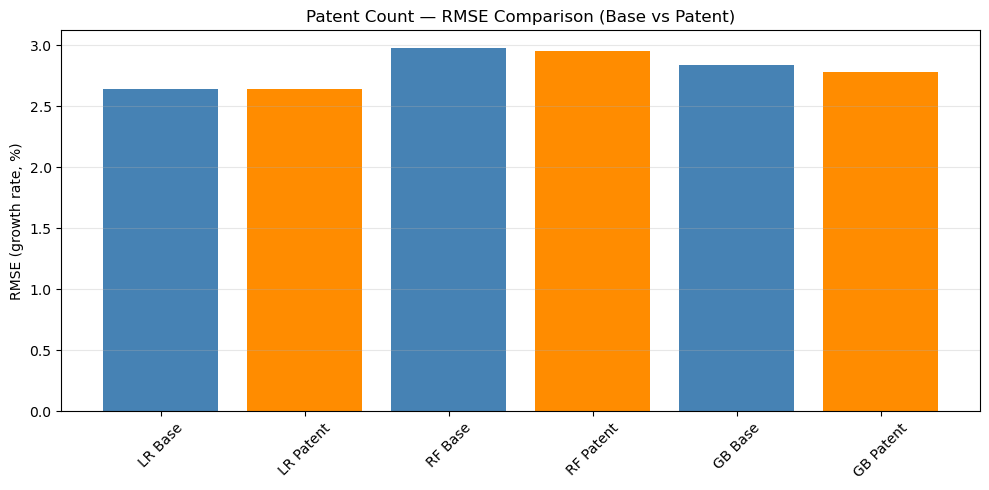

In [166]:
models_list = ["LR Base", "LR Patent", "RF Base", "RF Patent", "GB Base", "GB Patent"]
rmse_vals   = [rmse_lr_base, rmse_lr_pat, rmse_rf_base, rmse_rf_pat, rmse_gb_base, rmse_gb_pat]

plt.figure(figsize=(10, 5))
colors = ["steelblue", "darkorange", "steelblue", "darkorange", "steelblue", "darkorange"]
plt.bar(models_list, rmse_vals, color=colors)
plt.title("Patent Count — RMSE Comparison (Base vs Patent)")
plt.ylabel("RMSE (growth rate, %)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

---
## SHAP Analysis

All SHAP values are calculated based on the **log_patent_lag1** specification (last trained),

which is the most robust. Base vs. Patent for LR, RF, and GB.

### Linear Regression — SHAP (log_patent_lag1)

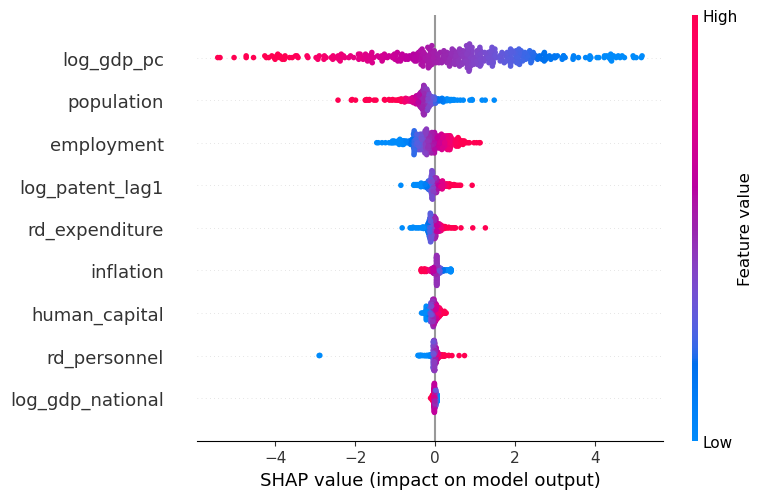

In [167]:
import shap

# Patent model
explainer_lr_pat = shap.Explainer(lr_pat_l, X_train_pat_l)
shap_values_lr_pat = explainer_lr_pat(X_test_pat_l)

shap.summary_plot(shap_values_lr_pat, X_test_pat_l)

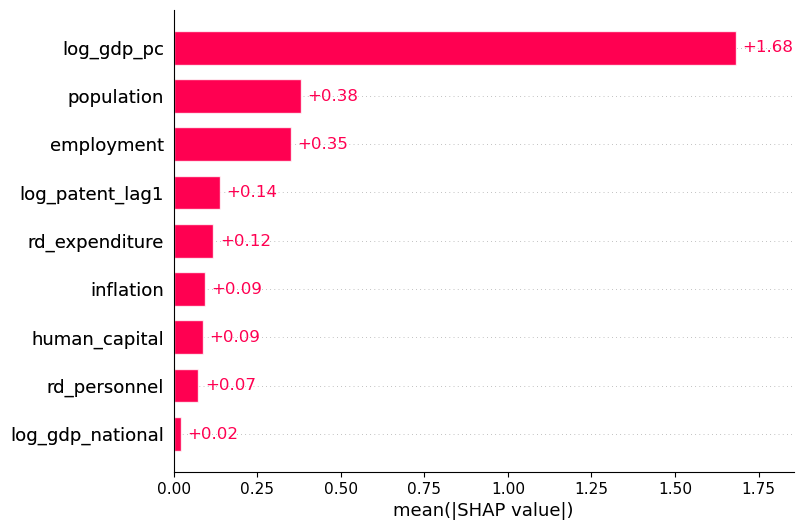

In [168]:
shap.plots.bar(shap_values_lr_pat)

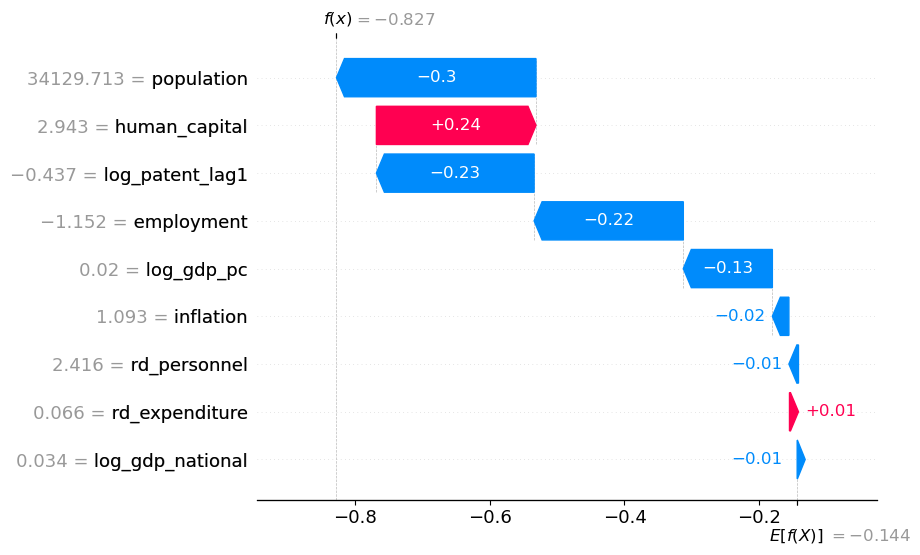

In [169]:
shap.plots.waterfall(shap_values_lr_pat[0])

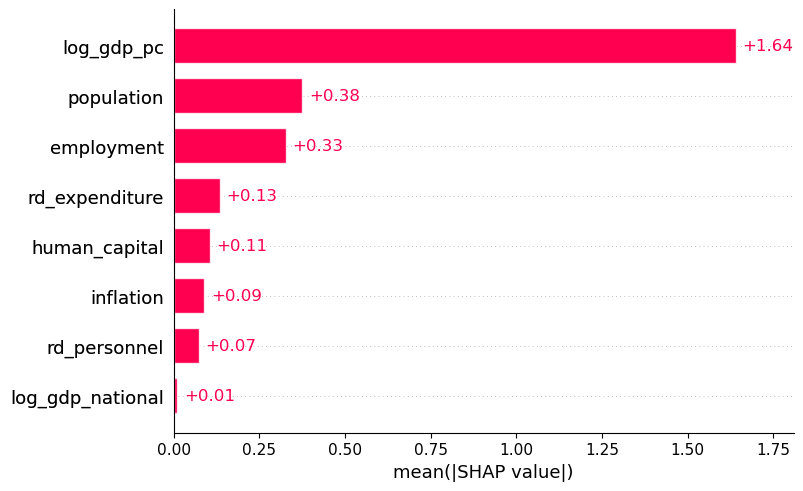

In [170]:
# Base model
explainer_lr_base = shap.Explainer(lr_base_l, X_train_base_l)
shap_values_lr_base = explainer_lr_base(X_test_base_l)

shap.plots.bar(shap_values_lr_base)

In [171]:
# Importance comparison: Base vs Patent
importance_lr_pat  = pd.Series(abs(shap_values_lr_pat.values).mean(axis=0),
                                index=X_test_pat_l.columns).sort_values(ascending=False)
importance_lr_base = pd.Series(abs(shap_values_lr_base.values).mean(axis=0),
                                index=X_test_base_l.columns).sort_values(ascending=False)

base_s   = importance_lr_base.reset_index()
patent_s = importance_lr_pat.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print("===== LR SHAP IMPORTANCE =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))

===== LR SHAP IMPORTANCE =====
   Base_Variable  Base_SHAP  Patent_Variable  Patent_SHAP
      log_gdp_pc   1.640867       log_gdp_pc     1.682198
      population   0.376077       population     0.379769
      employment   0.327631       employment     0.350256
  rd_expenditure   0.134033  log_patent_lag1     0.137846
   human_capital   0.105706   rd_expenditure     0.119290
       inflation   0.089589        inflation     0.094317
    rd_personnel   0.073606    human_capital     0.086604
log_gdp_national   0.010779     rd_personnel     0.073765
             NaN        NaN log_gdp_national     0.022026


### Random Forest — SHAP (log_patent_lag1)

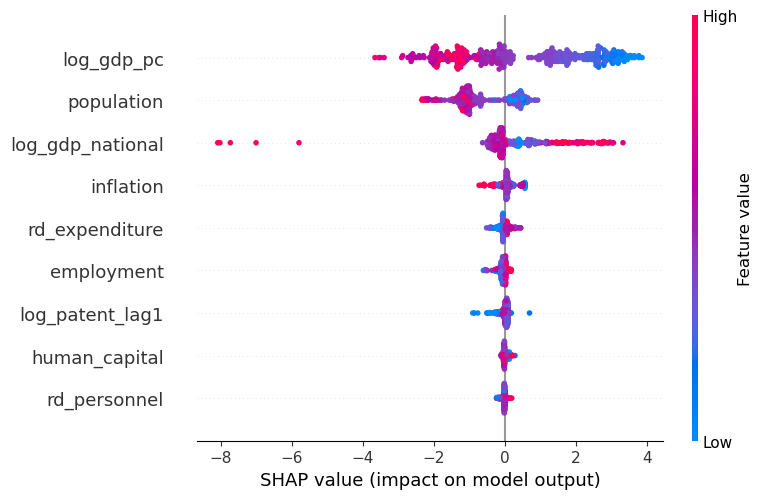

In [172]:
explainer_rf_pat = shap.TreeExplainer(best_rf_pat_l)
shap_values_rf_pat = explainer_rf_pat.shap_values(X_test_pat_l)

shap_exp_rf_pat = shap.Explanation(
    values=shap_values_rf_pat,
    base_values=np.repeat(explainer_rf_pat.expected_value, len(X_test_pat_l)),
    data=X_test_pat_l.values,
    feature_names=X_test_pat_l.columns
)

shap.summary_plot(shap_exp_rf_pat, X_test_pat_l)

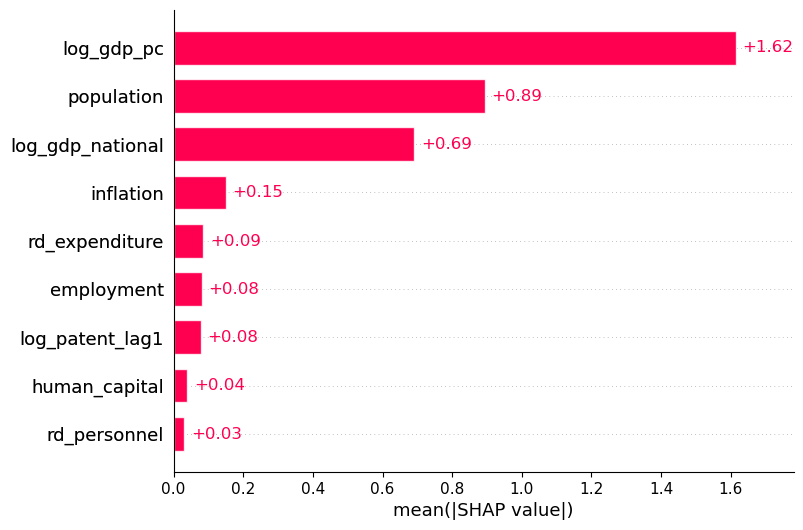

In [173]:
shap.plots.bar(shap_exp_rf_pat)

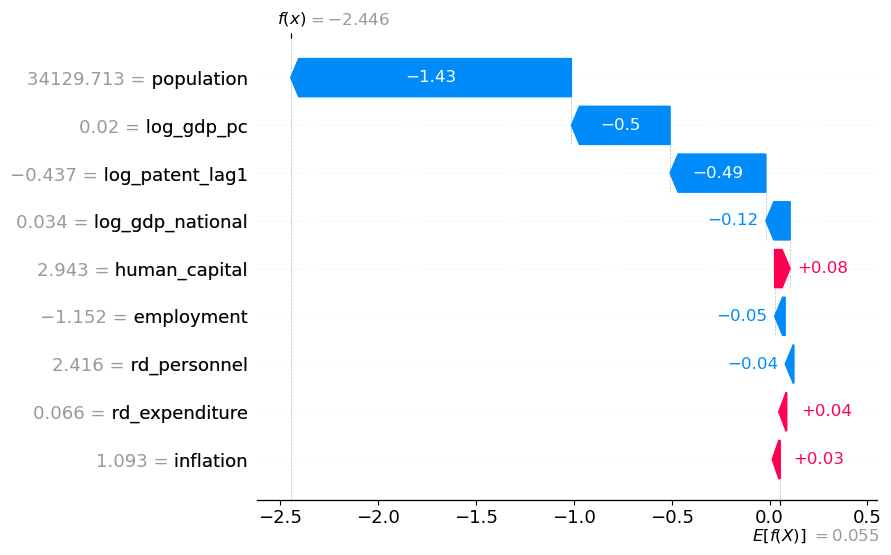

In [174]:
shap.plots.waterfall(shap_exp_rf_pat[0])

In [175]:
explainer_rf_base = shap.TreeExplainer(best_rf_base_l)
shap_values_rf_base = explainer_rf_base.shap_values(X_test_base_l)

shap_exp_rf_base = shap.Explanation(
    values=shap_values_rf_base,
    base_values=np.repeat(explainer_rf_base.expected_value, len(X_test_base_l)),
    data=X_test_base_l.values,
    feature_names=X_test_base_l.columns
)

importance_rf_pat  = pd.Series(np.abs(shap_exp_rf_pat.values).mean(axis=0),
                                index=X_test_pat_l.columns).sort_values(ascending=False)
importance_rf_base = pd.Series(np.abs(shap_exp_rf_base.values).mean(axis=0),
                                index=X_test_base_l.columns).sort_values(ascending=False)

base_s   = importance_rf_base.reset_index()
patent_s = importance_rf_pat.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print("===== RF SHAP IMPORTANCE =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))

===== RF SHAP IMPORTANCE =====
   Base_Variable  Base_SHAP  Patent_Variable  Patent_SHAP
      log_gdp_pc   1.667633       log_gdp_pc     1.615022
      population   0.971204       population     0.894644
log_gdp_national   0.721537 log_gdp_national     0.691726
       inflation   0.154317        inflation     0.150591
      employment   0.103073   rd_expenditure     0.085302
  rd_expenditure   0.089394       employment     0.081204
   human_capital   0.043820  log_patent_lag1     0.077346
    rd_personnel   0.032447    human_capital     0.039785
             NaN        NaN     rd_personnel     0.030274


### Gradient Boosting — SHAP (log_patent_lag1)

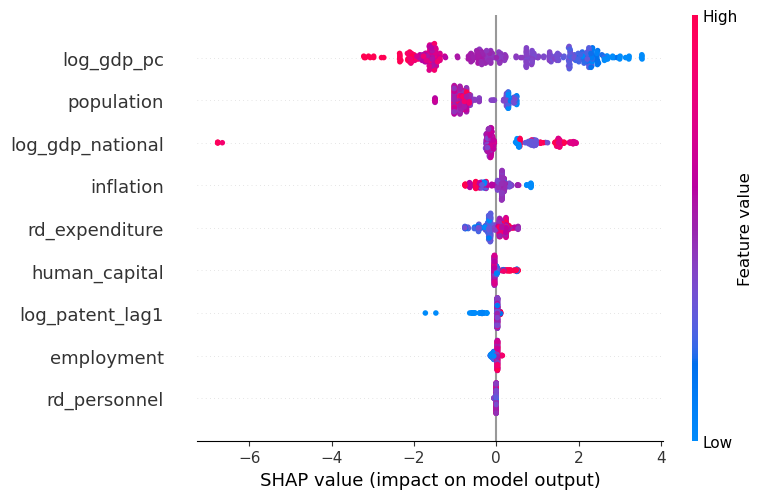

In [176]:
explainer_gb_pat = shap.TreeExplainer(best_gb_pat_l)
shap_values_gb_pat = explainer_gb_pat.shap_values(X_test_pat_l)

shap_exp_gb_pat = shap.Explanation(
    values=shap_values_gb_pat,
    base_values=np.repeat(explainer_gb_pat.expected_value, len(X_test_pat_l)),
    data=X_test_pat_l.values,
    feature_names=X_test_pat_l.columns
)

shap.summary_plot(shap_exp_gb_pat, X_test_pat_l)

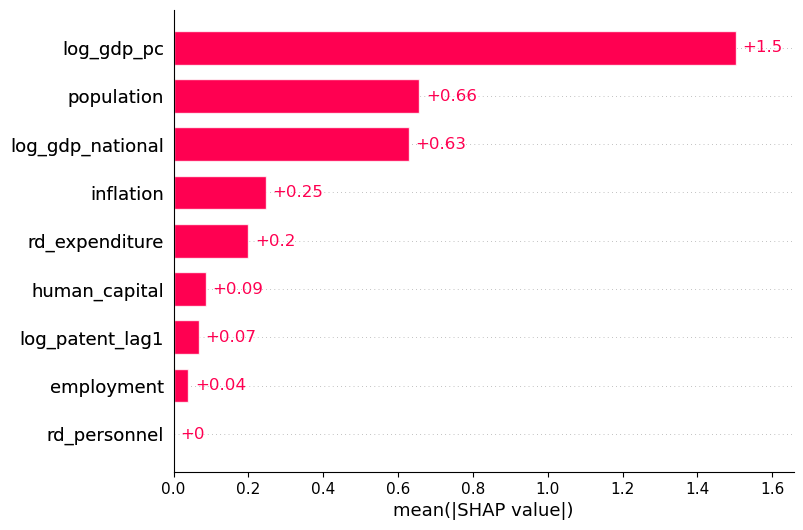

In [177]:
shap.plots.bar(shap_exp_gb_pat)

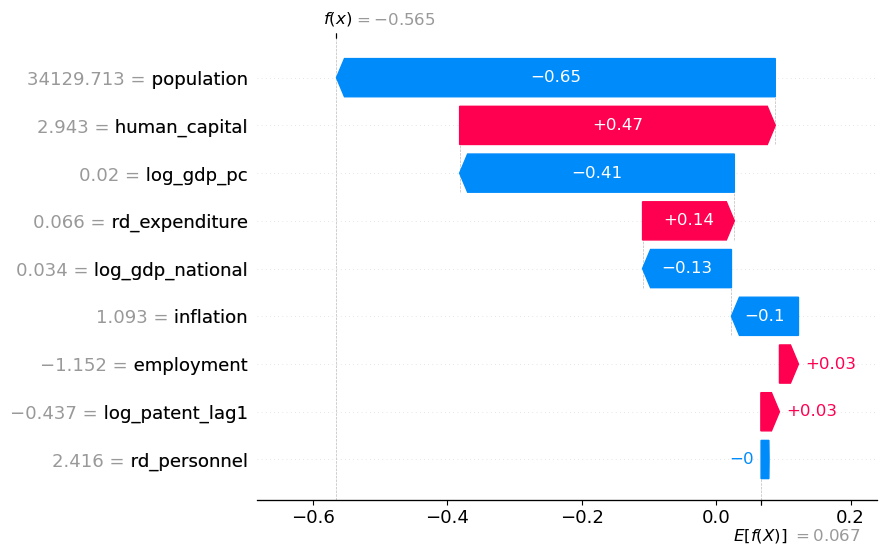

In [178]:
shap.plots.waterfall(shap_exp_gb_pat[0])

In [179]:
explainer_gb_base = shap.TreeExplainer(best_gb_base_l)
shap_values_gb_base = explainer_gb_base.shap_values(X_test_base_l)

shap_exp_gb_base = shap.Explanation(
    values=shap_values_gb_base,
    base_values=np.repeat(explainer_gb_base.expected_value, len(X_test_base_l)),
    data=X_test_base_l.values,
    feature_names=X_test_base_l.columns
)

importance_gb_pat  = pd.Series(np.abs(shap_exp_gb_pat.values).mean(axis=0),
                                index=X_test_pat_l.columns).sort_values(ascending=False)
importance_gb_base = pd.Series(np.abs(shap_exp_gb_base.values).mean(axis=0),
                                index=X_test_base_l.columns).sort_values(ascending=False)

base_s   = importance_gb_base.reset_index()
patent_s = importance_gb_pat.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print("===== GB SHAP IMPORTANCE =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))

===== GB SHAP IMPORTANCE =====
   Base_Variable  Base_SHAP  Patent_Variable  Patent_SHAP
      log_gdp_pc   1.523187       log_gdp_pc     1.503257
      population   0.685323       population     0.656884
log_gdp_national   0.667871 log_gdp_national     0.628606
       inflation   0.251765        inflation     0.246004
  rd_expenditure   0.217832   rd_expenditure     0.199721
   human_capital   0.098009    human_capital     0.085750
      employment   0.041478  log_patent_lag1     0.066569
    rd_personnel   0.007137       employment     0.039820
             NaN        NaN     rd_personnel     0.000912


In [180]:
# ===== SHAP Analysis — Delta=2 =====
import shap

# --- Linear Regression ---
explainer_lr_base_l = shap.Explainer(lr_base_l, X_train_base_l)
shap_values_lr_base_l = explainer_lr_base_l(X_test_base_l)

explainer_lr_pat_l = shap.Explainer(lr_pat_l, X_train_pat_l)
shap_values_lr_pat_l = explainer_lr_pat_l(X_test_pat_l)

importance_lr_base_l = pd.Series(abs(shap_values_lr_base_l.values).mean(axis=0),
                                   index=X_test_base_l.columns).sort_values(ascending=False)
importance_lr_pat_l  = pd.Series(abs(shap_values_lr_pat_l.values).mean(axis=0),
                                   index=X_test_pat_l.columns).sort_values(ascending=False)

base_s   = importance_lr_base_l.reset_index()
patent_s = importance_lr_pat_l.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print("===== LR SHAP IMPORTANCE — Delta=2 =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))


# --- Random Forest ---
explainer_rf_base_l = shap.TreeExplainer(best_rf_base_l)
shap_values_rf_base_l = explainer_rf_base_l.shap_values(X_test_base_l)

explainer_rf_pat_l = shap.TreeExplainer(best_rf_pat_l)
shap_values_rf_pat_l = explainer_rf_pat_l.shap_values(X_test_pat_l)

importance_rf_base_l = pd.Series(np.abs(shap_values_rf_base_l).mean(axis=0),
                                   index=X_test_base_l.columns).sort_values(ascending=False)
importance_rf_pat_l  = pd.Series(np.abs(shap_values_rf_pat_l).mean(axis=0),
                                   index=X_test_pat_l.columns).sort_values(ascending=False)

base_s   = importance_rf_base_l.reset_index()
patent_s = importance_rf_pat_l.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print('\n')
print("===== RF SHAP IMPORTANCE — Delta=2 =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))


# --- Gradient Boosting ---
explainer_gb_base_l = shap.TreeExplainer(best_gb_base_l)
shap_values_gb_base_l = explainer_gb_base_l.shap_values(X_test_base_l)

explainer_gb_pat_l = shap.TreeExplainer(best_gb_pat_l)
shap_values_gb_pat_l = explainer_gb_pat_l.shap_values(X_test_pat_l)

importance_gb_base_l = pd.Series(np.abs(shap_values_gb_base_l).mean(axis=0),
                                   index=X_test_base_l.columns).sort_values(ascending=False)
importance_gb_pat_l  = pd.Series(np.abs(shap_values_gb_pat_l).mean(axis=0),
                                   index=X_test_pat_l.columns).sort_values(ascending=False)

base_s   = importance_gb_base_l.reset_index()
patent_s = importance_gb_pat_l.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print('\n')
print("===== GB SHAP IMPORTANCE — Delta=2 =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))

===== LR SHAP IMPORTANCE — Delta=2 =====
   Base_Variable  Base_SHAP  Patent_Variable  Patent_SHAP
      log_gdp_pc   1.640867       log_gdp_pc     1.682198
      population   0.376077       population     0.379769
      employment   0.327631       employment     0.350256
  rd_expenditure   0.134033  log_patent_lag1     0.137846
   human_capital   0.105706   rd_expenditure     0.119290
       inflation   0.089589        inflation     0.094317
    rd_personnel   0.073606    human_capital     0.086604
log_gdp_national   0.010779     rd_personnel     0.073765
             NaN        NaN log_gdp_national     0.022026


===== RF SHAP IMPORTANCE — Delta=2 =====
   Base_Variable  Base_SHAP  Patent_Variable  Patent_SHAP
      log_gdp_pc   1.667633       log_gdp_pc     1.615022
      population   0.971204       population     0.894644
log_gdp_national   0.721537 log_gdp_national     0.691726
       inflation   0.154317        inflation     0.150591
      employment   0.103073   rd_expenditure  

---
---
# Multi-Horizon Forecast Analysis
## Horizon of 1 year

For each horizon `h`, features are constructed with lag `h` — i.e., values from year `T-h` are used to predict GDP per capita growth in year `T`.

Structure identical to the 1-year analysis:
1. **Replication** — Baseline, Linear FE, RF, GB (without patents)
2. **Patent test** — Linear FE, RF, GB with `patent_count` and `log_patent_lag_h`
3. **Final comparison + SHAP**

## Dataset construction by horizon

**Correction:** For each horizon Delta, we build a no-overlap panel where:
- The dependent variable is the **cumulative log-growth from T to T+Delta**
- Regressors are values at **T** (the anchor year)
- Anchor years are spaced by Delta to avoid any overlap

In [181]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
import shap


def build_horizon_dataset(df_base, df_patents_csv, horizon):
    """
    Build a no-overlap panel for a given forecast horizon.

    - Dependent variable: cumulative log-growth from T to T+horizon (%)
    - Regressors: all feature values at T
    - Anchor years spaced by `horizon` to avoid overlap / data leakage
    - Patents merged at T (not lagged further)
    """
    df = df_base.sort_values(["NUTS", "Year"]).copy()

    # Log of regional GDP per capita at T
    df["log_gdp_pc"] = np.log(df["GDP_per_capita"].replace(0, np.nan))

    # Dependent variable: growth from T to T+horizon
    df["GDP_pc_future"] = df.groupby("NUTS")["GDP_per_capita"].shift(-horizon)
    df["gdp_pc_growth"] = 100 * (
        np.log(df["GDP_pc_future"]) - np.log(df["GDP_per_capita"])
    )

    # Keep only anchor years (no overlap)
    min_year = df["Year"].min()
    df = df[df["Year"] % horizon == min_year % horizon].copy()
    df = df.dropna(subset=["GDP_pc_future"])
    df = df.drop(columns=["GDP_pc_future"])

    # Merge patents at T
    df_pat = df_patents_csv.copy().rename(columns={"region": "NUTS", "year": "Year"})
    df_pat["NUTS"] = df_pat["NUTS"].astype(str).str.strip()
    df_pat["Year"] = df_pat["Year"].astype(int)

    common = set(df["NUTS"]) & set(df_pat["NUTS"])
    df = df[df["NUTS"].isin(common)].copy()
    df = df.merge(df_pat, on=["NUTS", "Year"], how="left", validate="m:1")

    df["patent_count"] = df["patent_count"].fillna(0)
    df["patent_lag1"]  = df["patent_lag1"].fillna(0)
    df["log_patent_lag1"] = np.log1p(df["patent_lag1"])

    # Aliases for multi-horizon compatibility
    df["patent_count_lag_h"] = df["patent_count"]
    df["log_patent_lag_h"]   = df["log_patent_lag1"]

    return df


def within_transform_h(df, cols, unit="NUTS", time="Year"):
    df = df.copy()
    for col in cols:
        gm = df[col].mean()
        df[col] = df[col] - df.groupby(unit)[col].transform("mean") \
                           - df.groupby(time)[col].transform("mean") + gm
    return df

---
---
# 1 year Horizon
## Features with lag 1 — predict the annual growth of GDP per capita 1 year afterwards

### Create Delta=1 panel

#### Model specification — Delta=1

$$\text{GDPpc\_growth}_{(T,T+1),r} = F\bigl(\ln\text{GDPpc}_{T,r},\ \text{Employment}_{T,r},\ \text{HumanCapital}_{T,r},\ \text{RDExp}_{T,r},\ \text{RDPersonnel}_{T,r},\ \text{Population}_{T,r},\ \ln\text{GDP}_{T,c},\ \text{Inflation}_{T,c},\ [\text{Patents}_{T,r}]\bigr)$$

With **Delta = 1**: anchor years are 2003, 2004, 2005, ..., 2018 (growth measured to 2004, 2005, ..., 2019).

In [182]:
df_patents_raw = pd.read_csv("EPO_NUTS2_2021_features_corrected.csv")

In [183]:
df_h1 = build_horizon_dataset(df, df_patents_raw, horizon=1)

# Restringir às mesmas regiões do Delta=2 para comparabilidade
patent_regions_d2 = set(df_pat["NUTS"].unique())  # as 88 regiões do Delta=2
df_h1 = df_h1[df_h1["NUTS"].isin(patent_regions_d2)].copy()

print("Regiões em df_h1:", df_h1["NUTS"].nunique())  # deve imprimir 88
print("Shape:", df_h1.shape)
print("Anchor years:", sorted(df_h1["Year"].unique()))

Regiões em df_h1: 207
Shape: (3312, 22)
Anchor years: [np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018)]


#### Features and dataset

In [184]:
features_base_h1 = [
    "log_gdp_pc",
    "employment",
    "human_capital",
    "rd_expenditure",
    "rd_personnel",
    "population",
    "log_gdp_national",
    "inflation",
]
features_pat_h1     = features_base_h1 + ["patent_count_lag_h"]
features_pat_log_h1 = features_base_h1 + ["log_patent_lag_h"]

# Replicação usa df_main directamente (todas as regiões, sem restrição de patentes)
df_model_h1 = df_main.copy()
df_model_h1["log_gdp_pc"] = np.log(df_model_h1["GDP_per_capita"].replace(0, np.nan))
df_model_h1["GDP_pc_future"] = df_model_h1.groupby("NUTS")["GDP_per_capita"].shift(-1)
df_model_h1["gdp_pc_growth"] = 100 * (
    np.log(df_model_h1["GDP_pc_future"]) - np.log(df_model_h1["GDP_per_capita"])
)
df_model_h1 = df_model_h1.dropna(subset=["GDP_pc_future"]).drop(columns=["GDP_pc_future"])
df_model_h1 = df_model_h1.dropna(subset=["gdp_pc_growth"] + features_base_h1)

print("Regiões na replicação Δ=1:", df_model_h1["NUTS"].nunique())
print("Model dataset shape:", df_model_h1.shape)
print("Years:", df_model_h1["Year"].min(), "–", df_model_h1["Year"].max())

Regiões na replicação Δ=1: 200
Model dataset shape: (1316, 14)
Years: 2003 – 2015


In [185]:
for col in ["gdp_pc_growth"] + features_base_h1:
    missing_regions = df_h1[df_h1[col].isna()]["NUTS"].nunique()
    if missing_regions > 0:
        print(f"Regiões com NaNs em {col}: {missing_regions}")

print("\nRegiões antes de dropna:", df_h1["NUTS"].nunique())
print("Regiões após dropna:", df_h1.dropna(subset=["gdp_pc_growth"] + features_base_h1)["NUTS"].nunique())

Regiões com NaNs em employment: 20
Regiões com NaNs em human_capital: 23
Regiões com NaNs em rd_expenditure: 34
Regiões com NaNs em population: 14

Regiões antes de dropna: 207
Regiões após dropna: 207


In [186]:
# Quantas regiões tem a replicação do Δ=2?
print("Regiões na replicação Δ=2:", df_main[df_main["Year"].isin([2003,2005,2007,2009,2011,2013,2015,2017])]["NUTS"].nunique())

Regiões na replicação Δ=2: 209


In [187]:
print("Total regiões em df_main:", df_main["NUTS"].nunique())

Total regiões em df_main: 209


### Train/test split

In [188]:
train_h1 = df_model_h1[df_model_h1["Year"] <= 2013].copy()
test_h1  = df_model_h1[df_model_h1["Year"] >  2013].copy()

print("Train shape:", train_h1.shape,
      "| Years:", sorted(train_h1["Year"].unique()))
print("Test  shape:", test_h1.shape,
      "| Years:", sorted(test_h1["Year"].unique()))

Train shape: (1116, 14) | Years: [np.int64(2003), np.int64(2005), np.int64(2007), np.int64(2009), np.int64(2011), np.int64(2013)]
Test  shape: (200, 14) | Years: [np.int64(2015)]


## Replication

#### Baseline OLS

In [189]:
df_ar_h1 = df_model_h1.copy().sort_values(["NUTS", "Year"])
df_ar_h1["gdp_pc_growth_prev"] = df_ar_h1.groupby("NUTS")["gdp_pc_growth"].shift(1)

df_ar_train_h1 = df_ar_h1[df_ar_h1["Year"] <= 2013].dropna(subset=["gdp_pc_growth_prev"]).copy()
df_ar_test_h1  = df_ar_h1[df_ar_h1["Year"] >  2013].dropna(subset=["gdp_pc_growth_prev"]).copy()

y_train_ar_h1 = df_ar_train_h1["gdp_pc_growth"]
X_train_ar_h1 = sm.add_constant(df_ar_train_h1[["gdp_pc_growth_prev"]])

model_ar_h1 = sm.OLS(y_train_ar_h1, X_train_ar_h1).fit()
print(model_ar_h1.summary())

X_test_ar_h1 = sm.add_constant(df_ar_test_h1[["gdp_pc_growth_prev"]])
X_test_ar_h1 = X_test_ar_h1.reindex(columns=model_ar_h1.params.index, fill_value=0)
df_ar_test_h1["pred_ar"] = model_ar_h1.predict(X_test_ar_h1)

rmse_ar_h1 = np.sqrt(mean_squared_error(df_ar_test_h1["gdp_pc_growth"], df_ar_test_h1["pred_ar"]))
mae_ar_h1  = mean_absolute_error(df_ar_test_h1["gdp_pc_growth"],  df_ar_test_h1["pred_ar"])
print(f"Baseline RMSE (test): {rmse_ar_h1:.4f}")
print(f"Baseline MAE  (test): {mae_ar_h1:.4f}")

                            OLS Regression Results                            
Dep. Variable:          gdp_pc_growth   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     7.934
Date:                Wed, 26 Aug 2026   Prob (F-statistic):            0.00496
Time:                        15:44:06   Log-Likelihood:                -2985.6
No. Observations:                 920   AIC:                             5975.
Df Residuals:                     918   BIC:                             5985.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  1.4162      0

#### Linear Regression Fixed Effects

In [190]:
all_vars_rep_h1 = ["gdp_pc_growth"] + features_base_h1

df_w_h1 = within_transform(
    df_model_h1[all_vars_rep_h1 + ["NUTS","Year"]].dropna(), all_vars_rep_h1
)

train_w_h1 = df_w_h1[df_w_h1["Year"] <= 2013]
test_w_h1  = df_w_h1[df_w_h1["Year"] >  2013]

X_train_rep_h1 = sm.add_constant(train_w_h1[features_base_h1].astype(float))
y_train_rep_h1 = train_w_h1["gdp_pc_growth"].astype(float)
X_test_rep_h1  = sm.add_constant(test_w_h1[features_base_h1].astype(float))
y_test_rep_h1  = test_w_h1["gdp_pc_growth"].astype(float)

model_lr_h1 = sm.OLS(y_train_rep_h1, X_train_rep_h1).fit(cov_type="HC1")
print(model_lr_h1.summary())

pred_lr_h1   = model_lr_h1.predict(X_test_rep_h1)
rmse_lr_h1   = np.sqrt(mean_squared_error(y_test_rep_h1, pred_lr_h1))
mae_lr_h1    = mean_absolute_error(y_test_rep_h1, pred_lr_h1)
print(f"Linear FE RMSE (test): {rmse_lr_h1:.4f}")
print(f"Linear FE MAE  (test): {mae_lr_h1:.4f}")

                            OLS Regression Results                            
Dep. Variable:          gdp_pc_growth   R-squared:                       0.147
Model:                            OLS   Adj. R-squared:                  0.140
Method:                 Least Squares   F-statistic:                     19.17
Date:                Wed, 26 Aug 2026   Prob (F-statistic):           3.48e-27
Time:                        15:44:06   Log-Likelihood:                -3014.0
No. Observations:                1116   AIC:                             6046.
Df Residuals:                    1107   BIC:                             6091.
Df Model:                           8                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.0237      0.114  

### Random Forest — Replication 1 Year

In [191]:
tscv_h1 = TimeSeriesSplit(n_splits=5)
param_grid_h1 = {
    "n_estimators":      [100, 200],
    "max_depth":         [5, 10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf":  [1, 2]
}

X_train_rf_h1 = train_w_h1[features_base_h1]
y_train_rf_h1 = train_w_h1["gdp_pc_growth"]
X_test_rf_h1  = test_w_h1[features_base_h1]
y_test_rf_h1  = test_w_h1["gdp_pc_growth"]

grid_rf_h1 = GridSearchCV(RandomForestRegressor(random_state=42),
    param_grid_h1, cv=tscv_h1, scoring="neg_mean_squared_error", n_jobs=-1)
grid_rf_h1.fit(X_train_rf_h1, y_train_rf_h1)
best_rf_h1 = grid_rf_h1.best_estimator_
print("Best RF params:", grid_rf_h1.best_params_)

rmse_rf_h1 = np.sqrt(mean_squared_error(y_test_rf_h1, best_rf_h1.predict(X_test_rf_h1)))
mae_rf_h1  = mean_absolute_error(y_test_rf_h1,        best_rf_h1.predict(X_test_rf_h1))
print(f"RF RMSE (test): {rmse_rf_h1:.4f}")
print(f"RF MAE  (test): {mae_rf_h1:.4f}")

Best RF params: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
RF RMSE (test): 3.5290
RF MAE  (test): 2.4321


### Gradient Boosting — Replication 1 Year

In [192]:
param_grid_gb_h1 = {
    "n_estimators":      [100, 200],
    "learning_rate":     [0.05, 0.1],
    "max_depth":         [2, 3],
    "min_samples_split": [5, 10],
    "min_samples_leaf":  [2, 5]
}

grid_gb_h1 = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb_h1, cv=tscv_h1, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_h1.fit(X_train_rf_h1, y_train_rf_h1)
best_gb_h1 = grid_gb_h1.best_estimator_
print("Best GB params:", grid_gb_h1.best_params_)

rmse_gb_h1 = np.sqrt(mean_squared_error(y_test_rf_h1, best_gb_h1.predict(X_test_rf_h1)))
mae_gb_h1  = mean_absolute_error(y_test_rf_h1,        best_gb_h1.predict(X_test_rf_h1))
print(f"GB RMSE (test): {rmse_gb_h1:.4f}")
print(f"GB MAE  (test): {mae_gb_h1:.4f}")

Best GB params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
GB RMSE (test): 3.2332
GB MAE  (test): 2.2995


### Replication Summary

In [193]:
print("===== REPLICATION SUMMARY — Delta=1 =====")
print(f"Baseline          RMSE: {rmse_ar_h1:.4f} | MAE: {mae_ar_h1:.4f}")
print(f"Linear FE   RMSE: {rmse_lr_h1:.4f} | MAE: {mae_lr_h1:.4f}")
print(f"RF          RMSE: {rmse_rf_h1:.4f} | MAE: {mae_rf_h1:.4f}")
print(f"GB          RMSE: {rmse_gb_h1:.4f} | MAE: {mae_gb_h1:.4f}")

===== REPLICATION SUMMARY — Delta=1 =====
Baseline          RMSE: 4.3235 | MAE: 3.2909
Linear FE   RMSE: 2.7837 | MAE: 2.1841
RF          RMSE: 3.5290 | MAE: 2.4321
GB          RMSE: 3.2332 | MAE: 2.2995


In [194]:
all_vars_log_h1 = ["gdp_pc_growth"] + features_base_h1 + ["log_patent_lag_h"]

print("Linhas em df_h1 antes de dropna:", len(df_h1))
print("Linhas após dropna:", len(df_h1[all_vars_log_h1 + ["NUTS","Year"]].dropna()))
print("NaNs em log_patent_lag_h:", df_h1["log_patent_lag_h"].isna().sum())
print("Regiões únicas:", df_h1["NUTS"].nunique())

Linhas em df_h1 antes de dropna: 3312
Linhas após dropna: 3037
NaNs em log_patent_lag_h: 0
Regiões únicas: 207


In [195]:
for col in ["gdp_pc_growth"] + features_base_h1 + ["log_patent_lag_h"]:
    print(f"{col}: {df_h1[col].isna().sum()} NaNs")

gdp_pc_growth: 0 NaNs
log_gdp_pc: 0 NaNs
employment: 108 NaNs
human_capital: 112 NaNs
rd_expenditure: 261 NaNs
rd_personnel: 0 NaNs
population: 113 NaNs
log_gdp_national: 0 NaNs
inflation: 0 NaNs
log_patent_lag_h: 0 NaNs


## Within-transform patents

In [196]:
all_vars_log_h1 = ["gdp_pc_growth"] + features_pat_log_h1

df_log_w_h1 = within_transform(
    df_h1[all_vars_log_h1 + ["NUTS","Year"]].dropna(), all_vars_log_h1
)

train_log_h1 = df_log_w_h1[df_log_w_h1["Year"] <= 2013].reset_index(drop=True)
test_log_h1  = df_log_w_h1[df_log_w_h1["Year"] >  2013].reset_index(drop=True)

X_train_base_h1 = train_log_h1[features_base_h1]
y_train_base_h1 = train_log_h1["gdp_pc_growth"]
X_test_base_h1  = test_log_h1[features_base_h1]
y_test_base_h1  = test_log_h1["gdp_pc_growth"]

X_train_log_h1  = train_log_h1[features_pat_log_h1]
y_train_log_h1  = train_log_h1["gdp_pc_growth"]
X_test_log_h1   = test_log_h1[features_pat_log_h1]
y_test_log_h1   = test_log_h1["gdp_pc_growth"]

print(f"Train: {X_train_base_h1.shape} | Test: {X_test_base_h1.shape}")

Train: (2026, 8) | Test: (1011, 8)


In [197]:
print("Train base shape:", X_train_base_h1.shape)
print("Test base shape:", X_test_base_h1.shape)
print("Regiões no test base:", test_log_h1["NUTS"].nunique())

Train base shape: (2026, 8)
Test base shape: (1011, 8)
Regiões no test base: 207


In [198]:
print("Test base y stats:")
print(y_test_base_h1.describe())
print("\nTest replication y stats:")
print(y_test_rep_h1.describe())
print("\nSão o mesmo objecto?", y_test_base_h1.equals(y_test_rep_h1))

Test base y stats:
count    1011.000000
mean       -0.087306
std         1.894052
min       -10.534313
25%        -1.102910
50%        -0.113347
75%         0.909987
max        12.192117
Name: gdp_pc_growth, dtype: float64

Test replication y stats:
count    200.000000
mean      -0.056353
std        2.660206
min       -8.558730
25%       -1.795053
50%       -0.321202
75%        1.542091
max        8.362678
Name: gdp_pc_growth, dtype: float64

São o mesmo objecto? False


In [199]:
print("Antes de dropna:", df_h1["NUTS"].nunique(), "regiões,", len(df_h1), "linhas")

df_check = df_h1[["gdp_pc_growth"] + features_base_h1 + ["NUTS","Year"]].copy()
for col in ["gdp_pc_growth"] + features_base_h1:
    missing = df_check[col].isna().sum()
    if missing > 0:
        print(f"NaNs em {col}: {missing}")

print("\nApós dropna:", df_check.dropna()["NUTS"].nunique(), "regiões,", len(df_check.dropna()), "linhas")

Antes de dropna: 207 regiões, 3312 linhas
NaNs em employment: 108
NaNs em human_capital: 112
NaNs em rd_expenditure: 261
NaNs em population: 113

Após dropna: 207 regiões, 3037 linhas


## Analysis for log patent h1

#### Linear Regression

In [200]:
lr_base_h1 = LinearRegression().fit(X_train_base_h1, y_train_base_h1)
lr_log_h1  = LinearRegression().fit(X_train_log_h1,  y_train_log_h1)

rmse_lr_base_h1 = np.sqrt(mean_squared_error(y_test_base_h1, lr_base_h1.predict(X_test_base_h1)))
mae_lr_base_h1  = mean_absolute_error(y_test_base_h1,        lr_base_h1.predict(X_test_base_h1))
rmse_lr_log_h1  = np.sqrt(mean_squared_error(y_test_log_h1,  lr_log_h1.predict(X_test_log_h1)))
mae_lr_log_h1   = mean_absolute_error(y_test_log_h1,         lr_log_h1.predict(X_test_log_h1))

print("===== LINEAR — Log Patent (Delta=1) =====")
print(f"Base  RMSE: {rmse_lr_base_h1:.4f} | MAE: {mae_lr_base_h1:.4f}")
print(f"Log Patent   RMSE: {rmse_lr_log_h1:.4f}  | MAE: {mae_lr_log_h1:.4f}")
print(f"Gain: {rmse_lr_base_h1 - rmse_lr_log_h1:.4f}")


===== LINEAR — Log Patent (Delta=1) =====
Base  RMSE: 1.9354 | MAE: 1.3924
Log Patent   RMSE: 1.9387  | MAE: 1.3886
Gain: -0.0033


#### Random Forest

In [201]:
grid_rf_base_h1 = GridSearchCV(RandomForestRegressor(random_state=42),
    param_grid_h1, cv=tscv_h1, scoring="neg_mean_squared_error", n_jobs=-1)
grid_rf_base_h1.fit(X_train_base_h1, y_train_base_h1)

grid_rf_log_h1 = GridSearchCV(RandomForestRegressor(random_state=42),
    param_grid_h1, cv=tscv_h1, scoring="neg_mean_squared_error", n_jobs=-1)
grid_rf_log_h1.fit(X_train_log_h1, y_train_log_h1)

rmse_rf_base_h1 = np.sqrt(mean_squared_error(y_test_base_h1, grid_rf_base_h1.best_estimator_.predict(X_test_base_h1)))
mae_rf_base_h1  = mean_absolute_error(y_test_base_h1,        grid_rf_base_h1.best_estimator_.predict(X_test_base_h1))
rmse_rf_log_h1  = np.sqrt(mean_squared_error(y_test_log_h1,  grid_rf_log_h1.best_estimator_.predict(X_test_log_h1)))
mae_rf_log_h1   = mean_absolute_error(y_test_log_h1,         grid_rf_log_h1.best_estimator_.predict(X_test_log_h1))

print("===== RF — Log Patent (Delta=1) =====")
print(f"Base  RMSE: {rmse_rf_base_h1:.4f} | MAE: {mae_rf_base_h1:.4f}")
print(f"Log Patent   RMSE: {rmse_rf_log_h1:.4f}  | MAE: {mae_rf_log_h1:.4f}")
print(f"Gain: {rmse_rf_base_h1 - rmse_rf_log_h1:.4f}")
print("Best RF base params:", grid_rf_base_h1.best_params_)
print("Best RF log params:", grid_rf_log_h1.best_params_)

===== RF — Log Patent (Delta=1) =====
Base  RMSE: 2.7750 | MAE: 1.9319
Log Patent   RMSE: 2.4527  | MAE: 1.6791
Gain: 0.3223
Best RF base params: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best RF log params: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


#### Gradient Boosting

In [202]:
grid_gb_base_h1 = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb_h1, cv=tscv_h1, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_base_h1.fit(X_train_base_h1, y_train_base_h1)

grid_gb_log_h1 = GridSearchCV(GradientBoostingRegressor(random_state=42),
    param_grid_gb_h1, cv=tscv_h1, scoring="neg_mean_squared_error", n_jobs=-1)
grid_gb_log_h1.fit(X_train_log_h1, y_train_log_h1)

rmse_gb_base_h1 = np.sqrt(mean_squared_error(y_test_base_h1, grid_gb_base_h1.best_estimator_.predict(X_test_base_h1)))
mae_gb_base_h1  = mean_absolute_error(y_test_base_h1,        grid_gb_base_h1.best_estimator_.predict(X_test_base_h1))
rmse_gb_log_h1  = np.sqrt(mean_squared_error(y_test_log_h1,  grid_gb_log_h1.best_estimator_.predict(X_test_log_h1)))
mae_gb_log_h1   = mean_absolute_error(y_test_log_h1,         grid_gb_log_h1.best_estimator_.predict(X_test_log_h1))

print("===== GB — Log Patent (Delta=1) =====")
print(f"Base  RMSE: {rmse_gb_base_h1:.4f} | MAE: {mae_gb_base_h1:.4f}")
print(f"Log Patent  RMSE: {rmse_gb_log_h1:.4f}  | MAE: {mae_gb_log_h1:.4f}")
print(f"Gain: {rmse_gb_base_h1 - rmse_gb_log_h1:.4f}")
print("Best GB base params:", grid_gb_base_h1.best_params_)
print("Best GB log params:", grid_gb_log_h1.best_params_)

===== GB — Log Patent (Delta=1) =====
Base  RMSE: 2.2880 | MAE: 1.5912
Log Patent  RMSE: 2.2862  | MAE: 1.5844
Gain: 0.0018
Best GB base params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best GB log params: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}


## Final comparison Delta=1

In [203]:
print("=========== FINAL MODEL COMPARISON - Delta=1 ===========")
print("\n--- REPLICATION (full sample) ---")
print(f"Baseline    RMSE: {rmse_ar_h1:.4f}     | MAE: {mae_ar_h1:.4f}")
print(f"Linear FE   RMSE: {rmse_lr_h1:.4f}     | MAE: {mae_lr_h1:.4f}")
print(f"RF          RMSE: {rmse_rf_h1:.4f}     | MAE: {mae_rf_h1:.4f}")
print(f"GB          RMSE: {rmse_gb_h1:.4f}     | MAE: {mae_gb_h1:.4f}")
print("\n--- LOG PATENT LAG1 (restricted sample) ---")
print(f"LR Base     RMSE: {rmse_lr_base_h1:.4f} | MAE: {mae_lr_base_h1:.4f}")
print(f"LR Patent   RMSE: {rmse_lr_log_h1:.4f}  | MAE: {mae_lr_log_h1:.4f}  | Gain: {rmse_lr_base_h1 - rmse_lr_log_h1:.4f}")
print(f"RF Base     RMSE: {rmse_rf_base_h1:.4f} | MAE: {mae_rf_base_h1:.4f}")
print(f"RF Patent   RMSE: {rmse_rf_log_h1:.4f}  | MAE: {mae_rf_log_h1:.4f}  | Gain: {rmse_rf_base_h1 - rmse_rf_log_h1:.4f}")
print(f"GB Base     RMSE: {rmse_gb_base_h1:.4f} | MAE: {mae_gb_base_h1:.4f}")
print(f"GB Patent   RMSE: {rmse_gb_log_h1:.4f}  | MAE: {mae_gb_log_h1:.4f}  | Gain: {rmse_gb_base_h1 - rmse_gb_log_h1:.4f}")

=========== FINAL MODEL COMPARISON - Delta=1 ===========

--- REPLICATION (full sample) ---
Baseline    RMSE: 4.3235     | MAE: 3.2909
Linear FE   RMSE: 2.7837     | MAE: 2.1841
RF          RMSE: 3.5290     | MAE: 2.4321
GB          RMSE: 3.2332     | MAE: 2.2995

--- LOG PATENT LAG1 (restricted sample) ---
LR Base     RMSE: 1.9354 | MAE: 1.3924
LR Patent   RMSE: 1.9387  | MAE: 1.3886  | Gain: -0.0033
RF Base     RMSE: 2.7750 | MAE: 1.9319
RF Patent   RMSE: 2.4527  | MAE: 1.6791  | Gain: 0.3223
GB Base     RMSE: 2.2880 | MAE: 1.5912
GB Patent   RMSE: 2.2862  | MAE: 1.5844  | Gain: 0.0018


In [204]:
print("df_h1 regiões:", df_h1["NUTS"].nunique())
print("df_h1 shape:", df_h1.shape)
print("df_model_h1 regiões:", df_model_h1["NUTS"].nunique())
print("df_model_h1 shape:", df_model_h1.shape)

print("\nX_train_base_h1 shape:", X_train_base_h1.shape)
print("X_test_base_h1 shape:", X_test_base_h1.shape)
print("Regiões no test_log_h1:", test_log_h1["NUTS"].nunique())

df_h1 regiões: 207
df_h1 shape: (3312, 22)
df_model_h1 regiões: 200
df_model_h1 shape: (1316, 14)

X_train_base_h1 shape: (2026, 8)
X_test_base_h1 shape: (1011, 8)
Regiões no test_log_h1: 207


## SHAP Analysis

In [205]:
# ===== SHAP Analysis — Delta=1 =====

import shap

# --- Linear Regression ---
explainer_lr_base_h1 = shap.Explainer(lr_base_h1, X_train_base_h1)
shap_values_lr_base_h1 = explainer_lr_base_h1(X_test_base_h1)

explainer_lr_log_h1 = shap.Explainer(lr_log_h1, X_train_log_h1)
shap_values_lr_log_h1 = explainer_lr_log_h1(X_test_log_h1)

importance_lr_base_h1 = pd.Series(abs(shap_values_lr_base_h1.values).mean(axis=0),
                                   index=X_test_base_h1.columns).sort_values(ascending=False)
importance_lr_log_h1  = pd.Series(abs(shap_values_lr_log_h1.values).mean(axis=0),
                                   index=X_test_log_h1.columns).sort_values(ascending=False)

base_s   = importance_lr_base_h1.reset_index()
patent_s = importance_lr_log_h1.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print("===== LR SHAP IMPORTANCE — Delta=1 =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))


# --- Random Forest ---
explainer_rf_base_h1 = shap.TreeExplainer(grid_rf_base_h1.best_estimator_)
shap_values_rf_base_h1 = explainer_rf_base_h1.shap_values(X_test_base_h1)

explainer_rf_log_h1 = shap.TreeExplainer(grid_rf_log_h1.best_estimator_)
shap_values_rf_log_h1 = explainer_rf_log_h1.shap_values(X_test_log_h1)

importance_rf_base_h1 = pd.Series(np.abs(shap_values_rf_base_h1).mean(axis=0),
                                   index=X_test_base_h1.columns).sort_values(ascending=False)
importance_rf_log_h1  = pd.Series(np.abs(shap_values_rf_log_h1).mean(axis=0),
                                   index=X_test_log_h1.columns).sort_values(ascending=False)

base_s   = importance_rf_base_h1.reset_index()
patent_s = importance_rf_log_h1.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print('\n')
print("===== RF SHAP IMPORTANCE — Delta=1 =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))


# --- Gradient Boosting ---
explainer_gb_base_h1 = shap.TreeExplainer(grid_gb_base_h1.best_estimator_)
shap_values_gb_base_h1 = explainer_gb_base_h1.shap_values(X_test_base_h1)

explainer_gb_log_h1 = shap.TreeExplainer(grid_gb_log_h1.best_estimator_)
shap_values_gb_log_h1 = explainer_gb_log_h1.shap_values(X_test_log_h1)

importance_gb_base_h1 = pd.Series(np.abs(shap_values_gb_base_h1).mean(axis=0),
                                   index=X_test_base_h1.columns).sort_values(ascending=False)
importance_gb_log_h1  = pd.Series(np.abs(shap_values_gb_log_h1).mean(axis=0),
                                   index=X_test_log_h1.columns).sort_values(ascending=False)

base_s   = importance_gb_base_h1.reset_index()
patent_s = importance_gb_log_h1.reset_index()
base_s.columns   = ["Base_Variable",   "Base_SHAP"]
patent_s.columns = ["Patent_Variable", "Patent_SHAP"]
print('\n')
print("===== GB SHAP IMPORTANCE — Delta=1 =====")
print(pd.concat([base_s, patent_s], axis=1).to_string(index=False))

===== LR SHAP IMPORTANCE — Delta=1 =====
   Base_Variable  Base_SHAP  Patent_Variable  Patent_SHAP
      log_gdp_pc   0.804662       log_gdp_pc     0.835062
      employment   0.262126       employment     0.279221
      population   0.209594       population     0.210285
       inflation   0.187939        inflation     0.192245
log_gdp_national   0.140291 log_gdp_national     0.132364
  rd_expenditure   0.106197 log_patent_lag_h     0.130340
    rd_personnel   0.048713   rd_expenditure     0.094249
   human_capital   0.023845     rd_personnel     0.048514
             NaN        NaN    human_capital     0.041879


===== RF SHAP IMPORTANCE — Delta=1 =====
   Base_Variable  Base_SHAP  Patent_Variable  Patent_SHAP
      log_gdp_pc   1.089331       log_gdp_pc     0.887927
      population   0.689787       population     0.567263
       inflation   0.322948        inflation     0.280100
      employment   0.312339 log_gdp_national     0.180067
log_gdp_national   0.304413       employment  

# Cross-Horizon Comparison — 1 Year vs 2 Years
Direct comparison across the three horizons to assess how patents contribute
to forecasting accuracy in the short, medium, and long run.

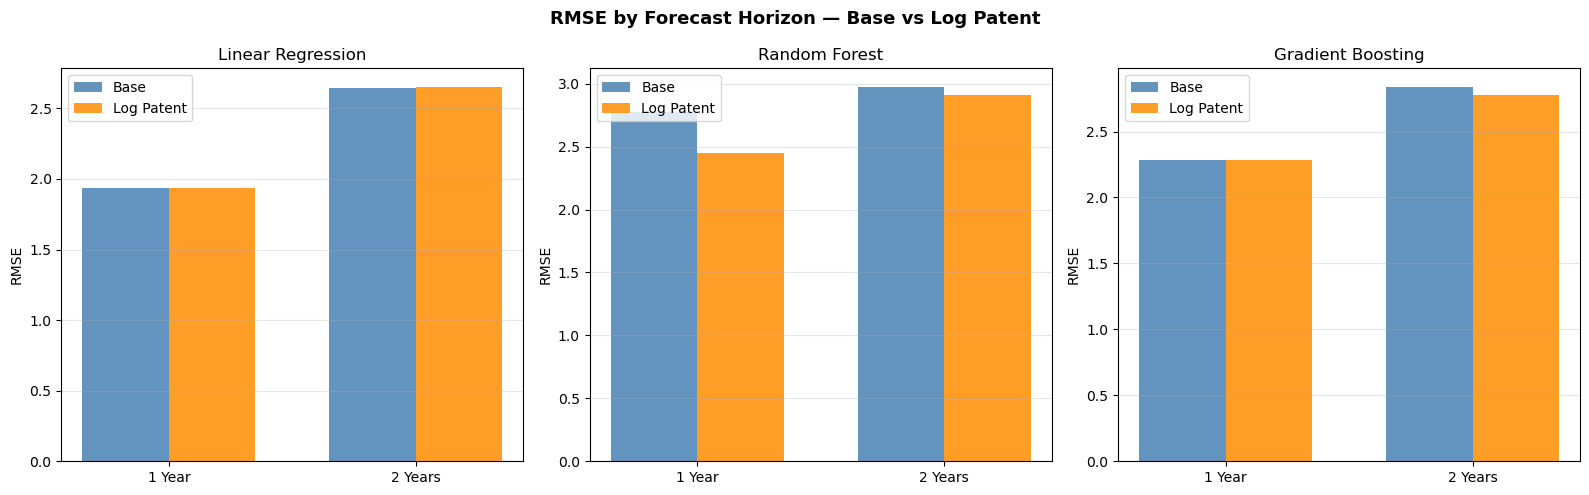

In [206]:
horizons_label = ["1 Year", "2 Years"]

# LR
rmse_lr_base_all = [rmse_lr_base_h1, rmse_lr_base_l]
rmse_lr_log_all  = [rmse_lr_log_h1,  rmse_lr_pat_l]

# RF
rmse_rf_base_all = [rmse_rf_base_h1, rmse_rf_base_l]
rmse_rf_log_all  = [rmse_rf_log_h1,  rmse_rf_pat_l]

# GB
rmse_gb_base_all = [rmse_gb_base_h1, rmse_gb_base_l]
rmse_gb_log_all  = [rmse_gb_log_h1,  rmse_gb_pat_l]

x = np.arange(len(horizons_label))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
specs = [
    ("Linear Regression", rmse_lr_base_all, rmse_lr_log_all),
    ("Random Forest",     rmse_rf_base_all, rmse_rf_log_all),
    ("Gradient Boosting", rmse_gb_base_all, rmse_gb_log_all),
]
for ax, (title, base_v, pat_v) in zip(axes, specs):
    ax.bar(x - width/2, base_v, width, label="Base",       color="steelblue",  alpha=0.85)
    ax.bar(x + width/2, pat_v,  width, label="Log Patent", color="darkorange", alpha=0.85)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(horizons_label)
    ax.set_ylabel("RMSE")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("RMSE by Forecast Horizon — Base vs Log Patent", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## Cross-horizon summary table - Replication (RMSE + MAE)

In [207]:
# Cross-horizon summary table — Replication (RMSE + MAE)

print("--- REPLICATION (full sample) — Delta=1 ---")
print(f"Baseline    RMSE: {rmse_ar_h1:.4f}     | MAE: {mae_ar_h1:.4f}")
print(f"Linear FE   RMSE: {rmse_lr_h1:.4f}     | MAE: {mae_lr_h1:.4f}")
print(f"RF          RMSE: {rmse_rf_h1:.4f}     | MAE: {mae_rf_h1:.4f}")
print(f"GB          RMSE: {rmse_gb_h1:.4f}     | MAE: {mae_gb_h1:.4f}")

print("\n--- REPLICATION (full sample) — Delta=2 ---")
print(f"Baseline    RMSE: {rmse_ar:.4f}     | MAE: {mae_ar:.4f}")
print(f"Linear FE   RMSE: {rmse_lr:.4f}     | MAE: {mae_lr:.4f}")
print(f"RF          RMSE: {rmse_rf:.4f}     | MAE: {mae_rf:.4f}")
print(f"GB          RMSE: {rmse_gb_cv:.4f}  | MAE: {mae_gb_cv:.4f}")

--- REPLICATION (full sample) — Delta=1 ---
Baseline    RMSE: 4.3235     | MAE: 3.2909
Linear FE   RMSE: 2.7837     | MAE: 2.1841
RF          RMSE: 3.5290     | MAE: 2.4321
GB          RMSE: 3.2332     | MAE: 2.2995

--- REPLICATION (full sample) — Delta=2 ---
Baseline    RMSE: 4.1354     | MAE: 3.0461
Linear FE   RMSE: 2.6705     | MAE: 1.9822
RF          RMSE: 3.2714     | MAE: 2.2652
GB          RMSE: 3.2456  | MAE: 2.2715


### Cross-horizon summary table - Log Patent (RMSE + MAE)

In [208]:
# Cross-horizon summary table — Log Patent (RMSE + MAE)
horizons_label = ["1 Year", "2 Years"]

rmse_lr_base_all = [rmse_lr_base_h1, rmse_lr_base_l]
rmse_lr_log_all  = [rmse_lr_log_h1,  rmse_lr_pat_l]
rmse_rf_base_all = [rmse_rf_base_h1, rmse_rf_base_l]
rmse_rf_log_all  = [rmse_rf_log_h1,  rmse_rf_pat_l]
rmse_gb_base_all = [rmse_gb_base_h1, rmse_gb_base_l]
rmse_gb_log_all  = [rmse_gb_log_h1,  rmse_gb_pat_l]

mae_lr_base_all = [mae_lr_base_h1, mae_lr_base_l]
mae_lr_log_all  = [mae_lr_log_h1,  mae_lr_pat_l]
mae_rf_base_all = [mae_rf_base_h1, mae_rf_base_l]
mae_rf_log_all  = [mae_rf_log_h1,  mae_rf_pat_l]
mae_gb_base_all = [mae_gb_base_h1, mae_gb_base_l]
mae_gb_log_all  = [mae_gb_log_h1,  mae_gb_pat_l]

rows = []
for h_label, rb_lr, rp_lr, rb_rf, rp_rf, rb_gb, rp_gb, \
             mb_lr, mp_lr, mb_rf, mp_rf, mb_gb, mp_gb in zip(
    horizons_label,
    rmse_lr_base_all, rmse_lr_log_all,
    rmse_rf_base_all, rmse_rf_log_all,
    rmse_gb_base_all, rmse_gb_log_all,
    mae_lr_base_all,  mae_lr_log_all,
    mae_rf_base_all,  mae_rf_log_all,
    mae_gb_base_all,  mae_gb_log_all,
):
    rows.append({"Horizon": h_label, "Spec": "Base",
                 "LR RMSE": rb_lr, "LR MAE": mb_lr,
                 "RF RMSE": rb_rf, "RF MAE": mb_rf,
                 "GB RMSE": rb_gb, "GB MAE": mb_gb})
    rows.append({"Horizon": h_label, "Spec": "Log Patent",
                 "LR RMSE": rp_lr, "LR MAE": mp_lr,
                 "RF RMSE": rp_rf, "RF MAE": mp_rf,
                 "GB RMSE": rp_gb, "GB MAE": mp_gb})
    rows.append({"Horizon": h_label, "Spec": "Gain",
                 "LR RMSE": rb_lr - rp_lr, "LR MAE": mb_lr - mp_lr,
                 "RF RMSE": rb_rf - rp_rf, "RF MAE": mb_rf - mp_rf,
                 "GB RMSE": rb_gb - rp_gb, "GB MAE": mb_gb - mp_gb})

summary_cross = pd.DataFrame(rows).round(4)
for horizon in horizons_label:
    subset = summary_cross[summary_cross["Horizon"] == horizon]
    print(subset.to_string(index=False))
    print()

Horizon       Spec  LR RMSE  LR MAE  RF RMSE  RF MAE  GB RMSE  GB MAE
 1 Year       Base   1.9354  1.3924   2.7750  1.9319   2.2880  1.5912
 1 Year Log Patent   1.9387  1.3886   2.4527  1.6791   2.2862  1.5844
 1 Year       Gain  -0.0033  0.0038   0.3223  0.2528   0.0018  0.0068

Horizon       Spec  LR RMSE  LR MAE  RF RMSE  RF MAE  GB RMSE  GB MAE
2 Years       Base    2.645  1.9586   2.9734  2.1440   2.8374  2.0338
2 Years Log Patent    2.651  1.9512   2.9104  2.0978   2.7796  2.0030
2 Years       Gain   -0.006  0.0074   0.0629  0.0462   0.0578  0.0308



In [209]:
print("df_pat regiões:", len(set(df_pat["NUTS"].unique())))
print("df_h1 regiões:", df_h1["NUTS"].nunique())
print("df_h1 shape:", df_h1.shape)

df_pat regiões: 207
df_h1 regiões: 207
df_h1 shape: (3312, 22)


## Plots

In [210]:
# ── Forecast sem within-transform (raw features) ──────────────────────────
df_2017_raw = df_pat[df_pat["Year"] == 2017][["NUTS"] + features_pat_log].dropna().copy()

y_forecast_raw = best_gb_pat_l.predict(df_2017_raw[features_pat_log])

df_forecast = pd.DataFrame({
    "NUTS_ID":             df_2017_raw["NUTS"].values,
    "gdp_growth_forecast": y_forecast_raw
})

print(df_forecast["gdp_growth_forecast"].describe())
print("Regiões com forecast negativo:", (df_forecast["gdp_growth_forecast"] < 0).sum())

count    2.070000e+02
mean    -3.537876e+00
std      4.451658e-16
min     -3.537876e+00
25%     -3.537876e+00
50%     -3.537876e+00
75%     -3.537876e+00
max     -3.537876e+00
Name: gdp_growth_forecast, dtype: float64
Regiões com forecast negativo: 207


### GDP per capita growth in EU and 88 patent regions

Total regions: 242
Patent-sample regions: 207
count    242.000000
mean       4.125503
std        3.687710
min       -7.145896
25%        1.897086
50%        3.291135
75%        5.791574
max       17.602563
Name: gdp_growth_2017, dtype: float64


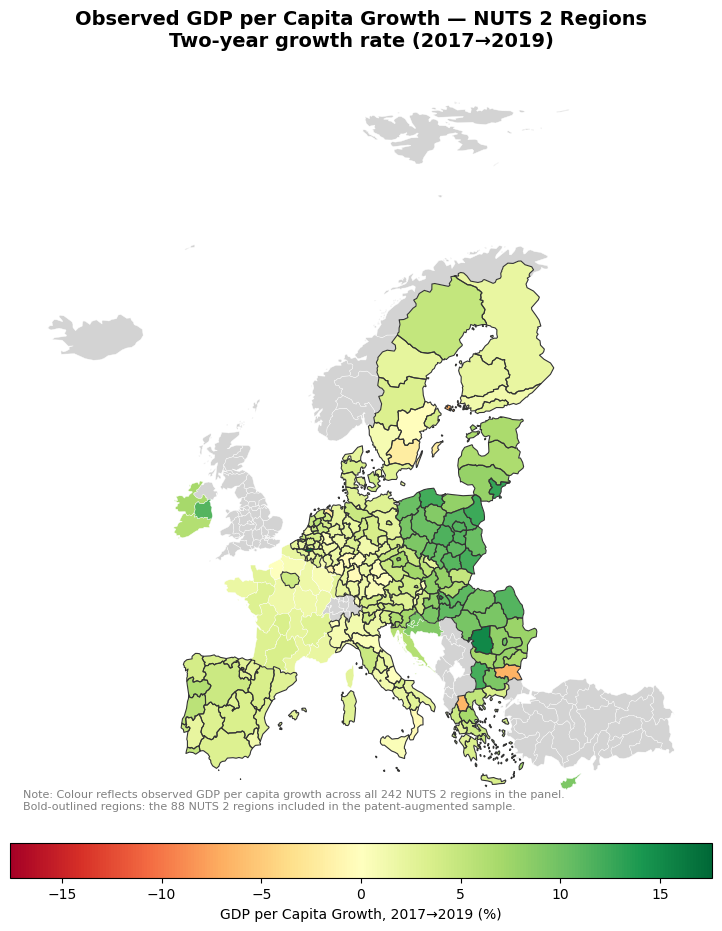

Map saved: gdp_growth_map_2017_full.png


In [211]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ── 1. Actual GDP per capita growth in 2017 — full panel (242 regions) ────
df_2017_actual = (df_panel[df_panel["Year"] == 2017][["NUTS", "gdp_pc_growth"]]
                  .dropna()
                  .rename(columns={"gdp_pc_growth": "gdp_growth_2017"})
                  .copy())

# Flag patent-sample regions
nuts_pat = set(df_pat["NUTS"].unique())
df_2017_actual["in_patent_sample"] = df_2017_actual["NUTS"].isin(nuts_pat)

print(f"Total regions: {len(df_2017_actual)}")
print(f"Patent-sample regions: {df_2017_actual['in_patent_sample'].sum()}")
print(df_2017_actual["gdp_growth_2017"].describe())

# ── 2. Load NUTS 2 shapefile ──────────────────────────────────────────────
nuts2_url = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_20M_2021_4326_LEVL_2.geojson"
nuts2 = gpd.read_file(nuts2_url)
nuts2 = nuts2[["NUTS_ID", "geometry"]]

nuts2_map = nuts2.merge(df_2017_actual, left_on="NUTS_ID", right_on="NUTS", how="left")

# ── 3. Clip to continental Europe ─────────────────────────────────────────
nuts2_eu = nuts2_map.cx[-25:45, 34:72]

# ── 4. Symmetric scale ────────────────────────────────────────────────────
vmax = max(
    abs(df_2017_actual["gdp_growth_2017"].min()),
    df_2017_actual["gdp_growth_2017"].max()
)

# ── 5. Plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# Grey fill for regions without data
nuts2_eu[nuts2_eu["gdp_growth_2017"].isna()].plot(
    ax=ax, color="#d3d3d3", linewidth=0.3, edgecolor="white"
)

# All 242 panel regions — full colour scale
nuts2_eu[nuts2_eu["gdp_growth_2017"].notna()].plot(
    column="gdp_growth_2017",
    ax=ax,
    cmap="RdYlGn",
    vmin=-vmax,
    vmax=vmax,
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label":       "GDP per Capita Growth, 2017→2019 (%)",
        "orientation": "horizontal",
        "shrink":      0.6,
        "pad":         0.02
    }
)

# Outline patent-sample regions with a bold border
nuts2_eu[nuts2_eu["in_patent_sample"] == True].plot(
    ax=ax, color="none", linewidth=0.8, edgecolor="#333333"
)

ax.set_title(
    "Observed GDP per Capita Growth — NUTS 2 Regions\n"
    "Two-year growth rate (2017→2019)",
    fontsize=14, fontweight="bold", pad=15
)
ax.set_axis_off()

ax.annotate(
    "Note: Colour reflects observed GDP per capita growth across all 242 NUTS 2 regions in the panel.\n"
    "Bold-outlined regions: the 88 NUTS 2 regions included in the patent-augmented sample.",
    xy=(0.01, 0.02), xycoords="axes fraction",
    fontsize=8, color="grey"
)

plt.tight_layout()
plt.savefig("gdp_growth_map_2017_full.png", dpi=200, bbox_inches="tight")
plt.show()
print("Map saved: gdp_growth_map_2017_full.png")

### Systematic Prediction Errors by Region — GB Patent Model (Δ=1 and Δ=2)

In [212]:
# Confirmar que estas variáveis existem
print(y_test_pat_l.shape)
print(y_pred_gb_pat_l.shape)
print(test_log_w[["NUTS", "Year"]].shape)

(405,)
(405,)
(405, 2)


count    207.000000
mean       0.422431
std        2.360153
min       -7.022231
25%       -0.925772
50%        0.238915
75%        1.677045
max        9.606153
Name: mean_error, dtype: float64

Regions with systematic over-prediction (error > 0): 124
Regions with systematic under-prediction (error < 0): 83


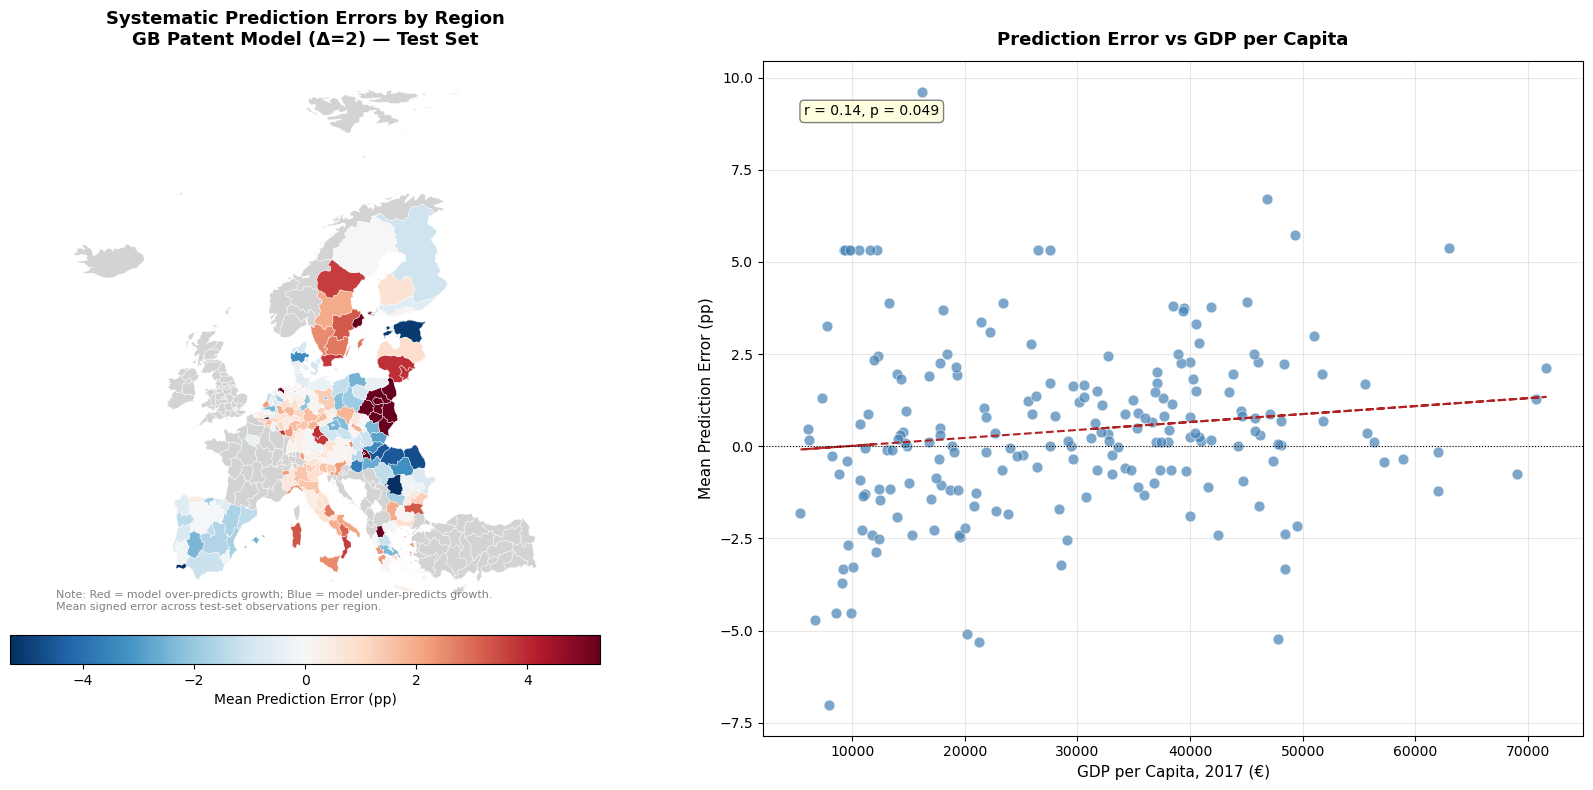

Saved: error_analysis_map_scatter.png


In [213]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from scipy import stats

# ── 1. Build error dataframe ──────────────────────────────────────────────
df_errors = test_log_w[["NUTS", "Year"]].copy().reset_index(drop=True)
df_errors["y_true"]  = y_test_pat_l.values
df_errors["y_pred"]  = y_pred_gb_pat_l
df_errors["error"]   = df_errors["y_pred"] - df_errors["y_true"]   # signed error
df_errors["abs_error"] = df_errors["error"].abs()

# ── 2. Aggregate by region (mean signed error = systematic bias) ──────────
df_region_errors = (df_errors.groupby("NUTS")
                    .agg(mean_error=("error", "mean"),
                         mae=("abs_error", "mean"),
                         n_obs=("error", "count"))
                    .reset_index())

print(df_region_errors["mean_error"].describe())
print(f"\nRegions with systematic over-prediction (error > 0): {(df_region_errors['mean_error'] > 0).sum()}")
print(f"Regions with systematic under-prediction (error < 0): {(df_region_errors['mean_error'] < 0).sum()}")

# ── 3. Merge with GDP (from df_panel, last available year per region) ─────
df_gdp_region = (df_panel[df_panel["Year"] == 2017]
                 .groupby("NUTS")[["GDP_per_capita", "gdp_pc_growth"]]
                 .mean()
                 .reset_index())

df_region_errors = df_region_errors.merge(df_gdp_region, on="NUTS", how="left")

# ── 4. Load NUTS 2 shapefile ──────────────────────────────────────────────
nuts2_url = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_20M_2021_4326_LEVL_2.geojson"
nuts2 = gpd.read_file(nuts2_url)
nuts2 = nuts2[["NUTS_ID", "geometry"]]

nuts2_errors = nuts2.merge(df_region_errors, left_on="NUTS_ID", right_on="NUTS", how="left")
nuts2_eu = nuts2_errors.cx[-25:45, 34:72]

# ── 5. Figure: map + scatter side by side ────────────────────────────────
fig = plt.figure(figsize=(18, 8))
gs  = gridspec.GridSpec(1, 2, width_ratios=[1.2, 1])

# --- Map of systematic errors ---
ax_map = fig.add_subplot(gs[0])

nuts2_eu[nuts2_eu["mean_error"].isna()].plot(
    ax=ax_map, color="#d3d3d3", linewidth=0.3, edgecolor="white"
)

vmax_err = nuts2_eu["mean_error"].abs().quantile(0.95)

nuts2_eu[nuts2_eu["mean_error"].notna()].plot(
    column="mean_error",
    ax=ax_map,
    cmap="RdBu_r",
    vmin=-vmax_err,
    vmax=vmax_err,
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label":       "Mean Prediction Error (pp)",
        "orientation": "horizontal",
        "shrink":      0.6,
        "pad":         0.02
    }
)

ax_map.set_title(
    "Systematic Prediction Errors by Region\n"
    "GB Patent Model (Δ=2) — Test Set",
    fontsize=13, fontweight="bold", pad=12
)
ax_map.set_axis_off()
ax_map.annotate(
    "Note: Red = model over-predicts growth; Blue = model under-predicts growth.\n"
    "Mean signed error across test-set observations per region.",
    xy=(0.01, 0.02), xycoords="axes fraction", fontsize=8, color="grey"
)

# --- Scatter: mean error vs GDP per capita ---
ax_scatter = fig.add_subplot(gs[1])

x = df_region_errors["GDP_per_capita"].dropna()
y = df_region_errors.loc[x.index, "mean_error"]

slope, intercept, r, p, _ = stats.linregress(x, y)

ax_scatter.scatter(x, y, color="steelblue", alpha=0.7, edgecolors="white", linewidth=0.5, s=60)
ax_scatter.plot(x, slope * x + intercept, color="firebrick", linewidth=1.5, linestyle="--")

ax_scatter.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax_scatter.set_xlabel("GDP per Capita, 2017 (€)", fontsize=11)
ax_scatter.set_ylabel("Mean Prediction Error (pp)", fontsize=11)
ax_scatter.set_title(
    "Prediction Error vs GDP per Capita",
    fontsize=13, fontweight="bold", pad=12
)
ax_scatter.annotate(
    f"r = {r:.2f}, p = {p:.3f}",
    xy=(0.05, 0.92), xycoords="axes fraction", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", edgecolor="grey")
)
ax_scatter.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("error_analysis_map_scatter.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: error_analysis_map_scatter.png")

In [214]:
[v for v in dir() if "pred" in v and "h1" in v]

['pred_lr_h1']

In [215]:
[v for v in dir() if "gb" in v and "h1" in v]

['best_gb_h1',
 'explainer_gb_base_h1',
 'explainer_gb_log_h1',
 'grid_gb_base_h1',
 'grid_gb_h1',
 'grid_gb_log_h1',
 'importance_gb_base_h1',
 'importance_gb_log_h1',
 'mae_gb_base_h1',
 'mae_gb_h1',
 'mae_gb_log_h1',
 'param_grid_gb_h1',
 'rmse_gb_base_h1',
 'rmse_gb_h1',
 'rmse_gb_log_h1',
 'shap_values_gb_base_h1',
 'shap_values_gb_log_h1']

In [216]:
y_pred_gb_log_h1 = grid_gb_log_h1.best_estimator_.predict(X_test_log_h1)
print("Predições Δ=1:", y_pred_gb_log_h1.shape)
print("Test set Δ=1:", test_log_h1["NUTS"].nunique(), "regiões")

Predições Δ=1: (1011,)
Test set Δ=1: 207 regiões


Regiões com erros agregados: 207
count    207.000000
mean      -0.087264
std        1.724847
min       -6.848735
25%       -0.873106
50%        0.111163
75%        0.875748
max        5.997251
Name: mean_error, dtype: float64

Over-prediction (error > 0): 114
Under-prediction (error < 0): 93


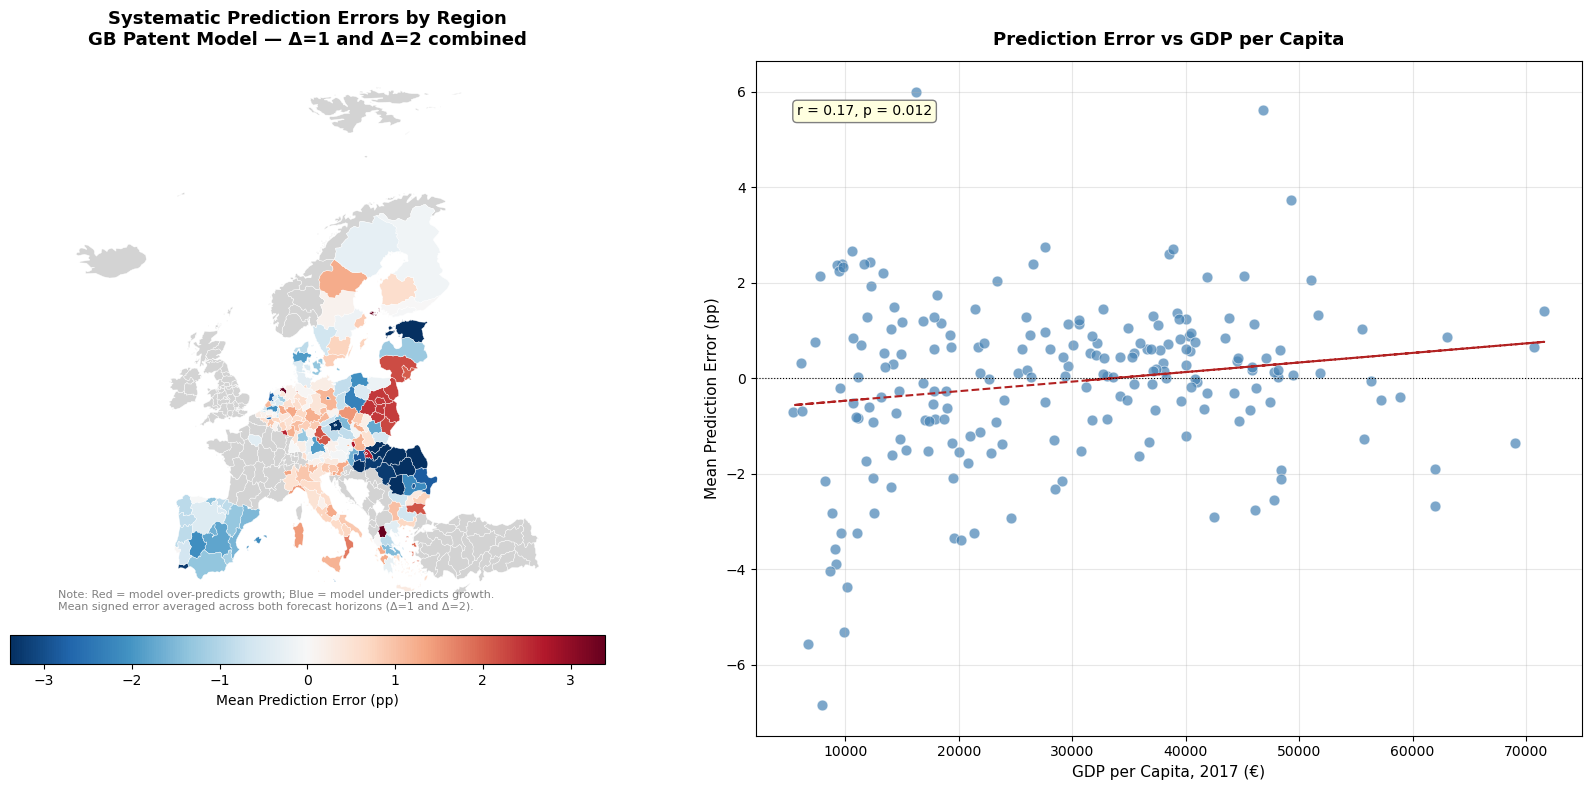

Saved: error_analysis_combined.png


In [217]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from scipy import stats

# ── 1. Errors Δ=1 ─────────────────────────────────────────────────────────
df_errors_h1 = test_log_h1[["NUTS", "Year"]].copy().reset_index(drop=True)
df_errors_h1["y_true"]    = y_test_log_h1.values
df_errors_h1["y_pred"]    = y_pred_gb_log_h1
df_errors_h1["error"]     = df_errors_h1["y_pred"] - df_errors_h1["y_true"]
df_errors_h1["abs_error"] = df_errors_h1["error"].abs()
df_errors_h1["horizon"]   = "Δ=1"

# ── 2. Errors Δ=2 ─────────────────────────────────────────────────────────
df_errors_h2 = test_log_w[["NUTS", "Year"]].copy().reset_index(drop=True)
df_errors_h2["y_true"]    = y_test_pat_l.values
df_errors_h2["y_pred"]    = y_pred_gb_pat_l
df_errors_h2["error"]     = df_errors_h2["y_pred"] - df_errors_h2["y_true"]
df_errors_h2["abs_error"] = df_errors_h2["error"].abs()
df_errors_h2["horizon"]   = "Δ=2"

# ── 3. Combine and aggregate by region ────────────────────────────────────
df_errors_all = pd.concat([df_errors_h1, df_errors_h2], ignore_index=True)

df_region_errors = (df_errors_all.groupby("NUTS")
                    .agg(mean_error=("error", "mean"),
                         mae=("abs_error", "mean"),
                         n_obs=("error", "count"))
                    .reset_index())

print(f"Regiões com erros agregados: {len(df_region_errors)}")
print(df_region_errors["mean_error"].describe())
print(f"\nOver-prediction (error > 0): {(df_region_errors['mean_error'] > 0).sum()}")
print(f"Under-prediction (error < 0): {(df_region_errors['mean_error'] < 0).sum()}")

# ── 4. Merge with GDP per capita ──────────────────────────────────────────
df_gdp_region = (df_panel[df_panel["Year"] == 2017]
                 .groupby("NUTS")[["GDP_per_capita"]]
                 .mean()
                 .reset_index())

df_region_errors = df_region_errors.merge(df_gdp_region, on="NUTS", how="left")

# ── 5. Load NUTS 2 shapefile ──────────────────────────────────────────────
nuts2_url = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_20M_2021_4326_LEVL_2.geojson"
nuts2 = gpd.read_file(nuts2_url)
nuts2 = nuts2[["NUTS_ID", "geometry"]]

nuts2_errors = nuts2.merge(df_region_errors, left_on="NUTS_ID", right_on="NUTS", how="left")
nuts2_eu = nuts2_errors.cx[-25:45, 34:72]

# ── 6. Figure: map + scatter ──────────────────────────────────────────────
fig = plt.figure(figsize=(18, 8))
gs  = gridspec.GridSpec(1, 2, width_ratios=[1.2, 1])

# --- Map ---
ax_map = fig.add_subplot(gs[0])

nuts2_eu[nuts2_eu["mean_error"].isna()].plot(
    ax=ax_map, color="#d3d3d3", linewidth=0.3, edgecolor="white"
)

vmax_err = nuts2_eu["mean_error"].abs().quantile(0.95)

nuts2_eu[nuts2_eu["mean_error"].notna()].plot(
    column="mean_error",
    ax=ax_map,
    cmap="RdBu_r",
    vmin=-vmax_err,
    vmax=vmax_err,
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label":       "Mean Prediction Error (pp)",
        "orientation": "horizontal",
        "shrink":      0.6,
        "pad":         0.02
    }
)

ax_map.set_title(
    "Systematic Prediction Errors by Region\n"
    "GB Patent Model — Δ=1 and Δ=2 combined",
    fontsize=13, fontweight="bold", pad=12
)
ax_map.set_axis_off()
ax_map.annotate(
    "Note: Red = model over-predicts growth; Blue = model under-predicts growth.\n"
    "Mean signed error averaged across both forecast horizons (Δ=1 and Δ=2).",
    xy=(0.01, 0.02), xycoords="axes fraction", fontsize=8, color="grey"
)

# --- Scatter ---
ax_scatter = fig.add_subplot(gs[1])

x = df_region_errors["GDP_per_capita"].dropna()
y = df_region_errors.loc[x.index, "mean_error"]

slope, intercept, r, p, _ = stats.linregress(x, y)

ax_scatter.scatter(x, y, color="steelblue", alpha=0.7,
                   edgecolors="white", linewidth=0.5, s=60)
ax_scatter.plot(x, slope * x + intercept,
                color="firebrick", linewidth=1.5, linestyle="--")
ax_scatter.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax_scatter.set_xlabel("GDP per Capita, 2017 (€)", fontsize=11)
ax_scatter.set_ylabel("Mean Prediction Error (pp)", fontsize=11)
ax_scatter.set_title(
    "Prediction Error vs GDP per Capita",
    fontsize=13, fontweight="bold", pad=12
)
ax_scatter.annotate(
    f"r = {r:.2f}, p = {p:.3f}",
    xy=(0.05, 0.92), xycoords="axes fraction", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", edgecolor="grey")
)
ax_scatter.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("error_analysis_combined.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: error_analysis_combined.png")

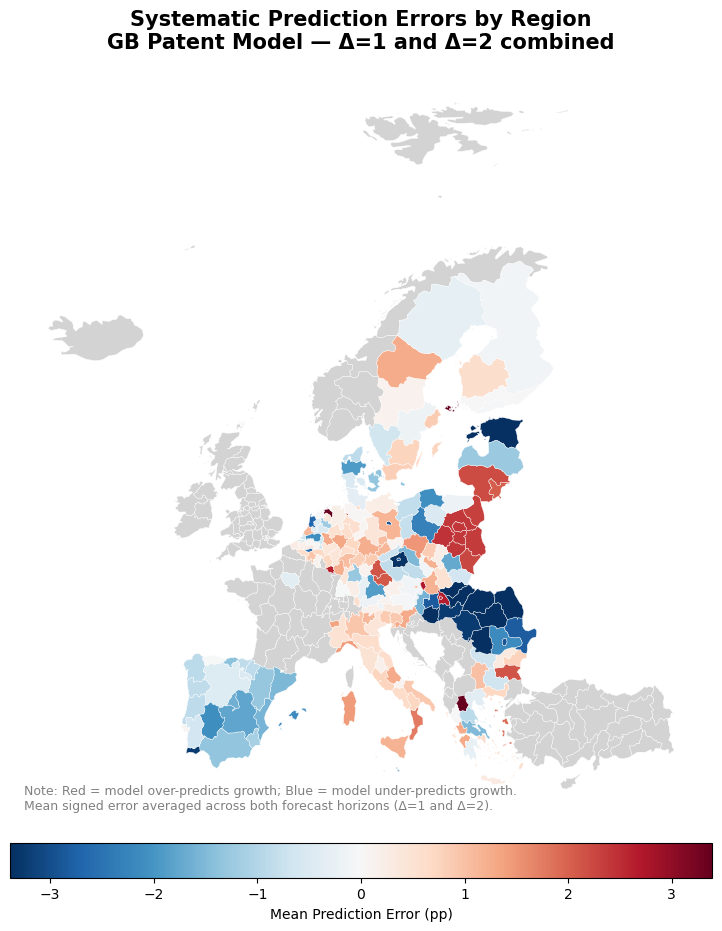

Saved: error_map_only.png


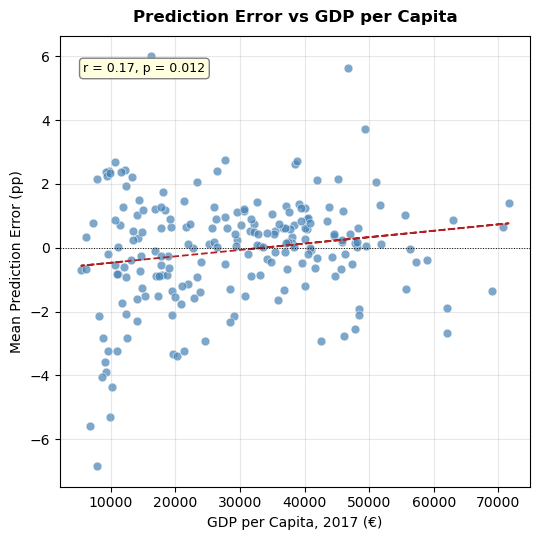

Saved: error_scatter_gdp.png


In [218]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats
# ── (Assumes df_region_errors, nuts2_eu, etc. already built from previous cell) ──
# ── FIGURE 1: Map of systematic prediction errors ─────────────────────────
fig1, ax_map = plt.subplots(figsize=(12, 10))
nuts2_eu[nuts2_eu["mean_error"].isna()].plot(
    ax=ax_map, color="#d3d3d3", linewidth=0.3, edgecolor="white"
)
vmax_err = nuts2_eu["mean_error"].abs().quantile(0.95)
nuts2_eu[nuts2_eu["mean_error"].notna()].plot(
    column="mean_error",
    ax=ax_map,
    cmap="RdBu_r",
    vmin=-vmax_err,
    vmax=vmax_err,
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label":       "Mean Prediction Error (pp)",
        "orientation": "horizontal",
        "shrink":      0.6,
        "pad":         0.02
    }
)
ax_map.set_title(
    "Systematic Prediction Errors by Region\n"
    "GB Patent Model — Δ=1 and Δ=2 combined",
    fontsize=15, fontweight="bold", pad=14
)
ax_map.set_axis_off()
ax_map.annotate(
    "Note: Red = model over-predicts growth; Blue = model under-predicts growth.\n"
    "Mean signed error averaged across both forecast horizons (Δ=1 and Δ=2).",
    xy=(0.01, 0.02), xycoords="axes fraction", fontsize=9, color="grey"
)
plt.tight_layout()
plt.savefig("error_map_only.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: error_map_only.png")
# ── FIGURE 2: Scatter — error vs GDP per capita ────────────────────────────
fig2, ax_scatter = plt.subplots(figsize=(5.5, 5.5))
x = df_region_errors["GDP_per_capita"].dropna()
y = df_region_errors.loc[x.index, "mean_error"]
slope, intercept, r, p, _ = stats.linregress(x, y)
ax_scatter.scatter(x, y, color="steelblue", alpha=0.7,
                   edgecolors="white", linewidth=0.5, s=40)
ax_scatter.plot(x, slope * x + intercept,
                color="firebrick", linewidth=1.3, linestyle="--")
ax_scatter.axhline(0, color="black", linewidth=0.7, linestyle=":")
ax_scatter.set_xlabel("GDP per Capita, 2017 (€)", fontsize=10)
ax_scatter.set_ylabel("Mean Prediction Error (pp)", fontsize=10)
ax_scatter.set_title(
    "Prediction Error vs GDP per Capita",
    fontsize=12, fontweight="bold", pad=10
)
ax_scatter.annotate(
    f"r = {r:.2f}, p = {p:.3f}",
    xy=(0.05, 0.92), xycoords="axes fraction", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", edgecolor="grey")
)
ax_scatter.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("error_scatter_gdp.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: error_scatter_gdp.png")

### Inequality

In [219]:
print(df_pat.columns.tolist())

['NUTS', 'Name', 'Year', 'GDP_per_capita', 'country', 'employment', 'human_capital', 'rd_expenditure', 'rd_personnel', 'population', 'log_gdp_national', 'inflation', 'log_gdp_pc', 'gdp_pc_growth', 'patent_count', 'log_patents', 'patent_growth', 'patent_lag1', 'patent_per_capita', 'log_patent_lag1']


In [220]:
print(df_pat[df_pat["Year"] == 2017][["NUTS", "patent_count", "patent_per_capita"]].describe())

       patent_count  patent_per_capita
count    207.000000         207.000000
mean     250.554813           0.000108
std      643.748053           0.000172
min        0.000000           0.000000
25%        9.750000           0.000007
50%       46.750000           0.000040
75%      234.033333           0.000137
max     6003.124603           0.001070


Regiões para análise: 207

Grupos por intensidade de patentes:
patent_group  n_regions  mean_error      mae  std_error
         Low         69   -0.536768 2.353530   2.341753
      Medium         69    0.119141 1.507545   1.464246
        High         69    0.155835 1.309785   1.037667


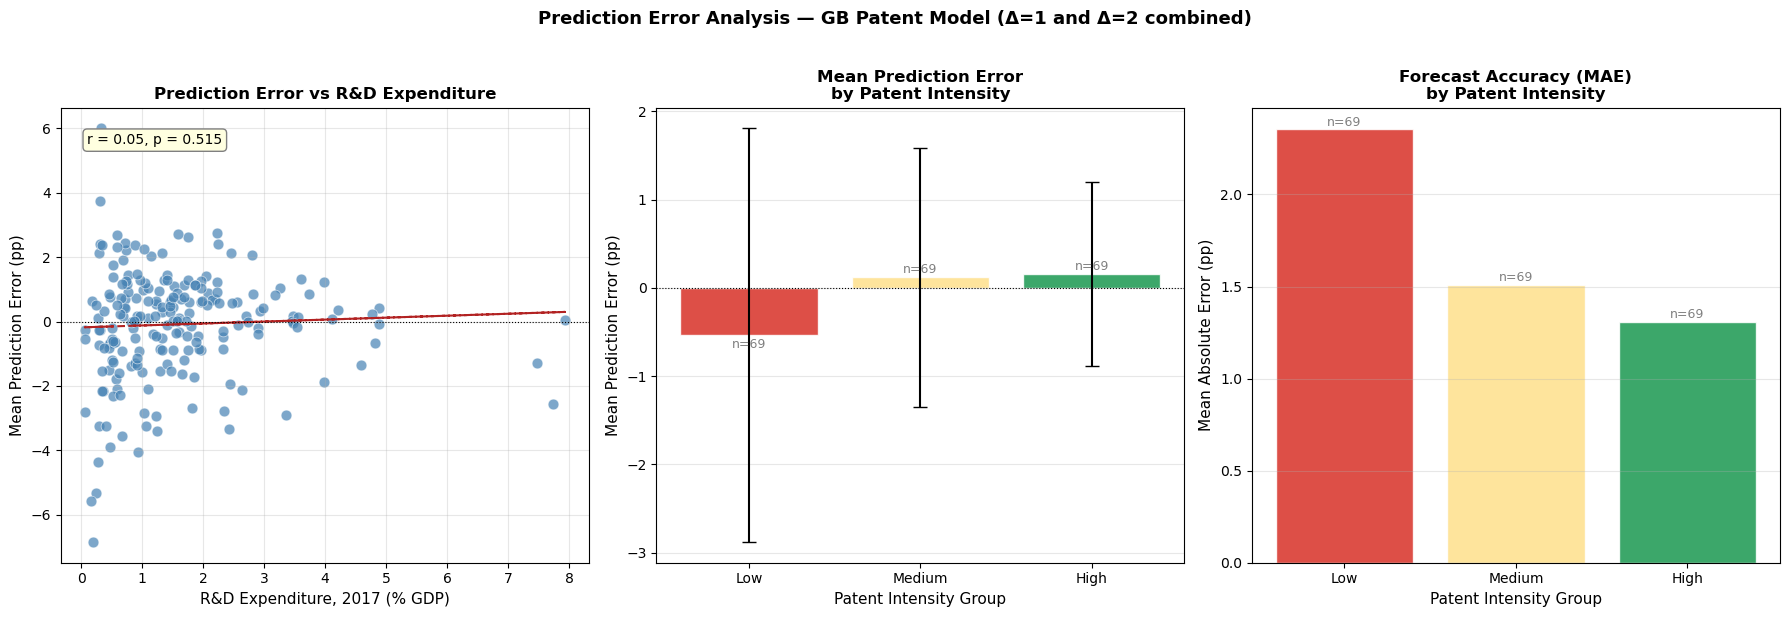

Saved: error_analysis_extended.png


In [221]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats

# ── 1. Merge region errors with patent and RD data (2017) ─────────────────
df_pat_2017 = df_pat[df_pat["Year"] == 2017][
    ["NUTS", "patent_per_capita", "patent_count", "rd_expenditure", "human_capital"]
].copy()

df_analysis = df_region_errors.merge(df_pat_2017, on="NUTS", how="left")
print(f"Regiões para análise: {len(df_analysis)}")

# ── 2. Correlação: erro vs RD expenditure (proxy inequality) ──────────────
df_rd = df_analysis.dropna(subset=["rd_expenditure", "mean_error"])
slope_rd, intercept_rd, r_rd, p_rd, _ = stats.linregress(
    df_rd["rd_expenditure"], df_rd["mean_error"]
)

# ── 3. Grupos por intensidade de patentes (tercis) ────────────────────────
df_pat_groups = df_analysis.dropna(subset=["patent_per_capita"])
df_pat_groups = df_pat_groups.copy()
df_pat_groups["patent_group"] = pd.qcut(
    df_pat_groups["patent_per_capita"],
    q=3,
    labels=["Low", "Medium", "High"]
)

group_stats = df_pat_groups.groupby("patent_group").agg(
    n_regions=("NUTS", "count"),
    mean_error=("mean_error", "mean"),
    mae=("mae", "mean"),
    std_error=("mean_error", "std")
).reset_index()

print("\nGrupos por intensidade de patentes:")
print(group_stats.to_string(index=False))

# ── 4. Figure ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- Scatter: erro vs RD expenditure ---
ax1 = axes[0]
ax1.scatter(df_rd["rd_expenditure"], df_rd["mean_error"],
            color="steelblue", alpha=0.7, edgecolors="white", linewidth=0.5, s=60)
ax1.plot(df_rd["rd_expenditure"],
         slope_rd * df_rd["rd_expenditure"] + intercept_rd,
         color="firebrick", linewidth=1.5, linestyle="--")
ax1.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax1.set_xlabel("R&D Expenditure, 2017 (% GDP)", fontsize=11)
ax1.set_ylabel("Mean Prediction Error (pp)", fontsize=11)
ax1.set_title("Prediction Error vs R&D Expenditure", fontsize=12, fontweight="bold")
ax1.annotate(
    f"r = {r_rd:.2f}, p = {p_rd:.3f}",
    xy=(0.05, 0.92), xycoords="axes fraction", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", edgecolor="grey")
)
ax1.grid(alpha=0.3)

# --- Bar: mean error by patent group ---
ax2 = axes[1]
colors = ["#d73027", "#fee08b", "#1a9850"]
bars = ax2.bar(group_stats["patent_group"], group_stats["mean_error"],
               color=colors, alpha=0.85, edgecolor="white",
               yerr=group_stats["std_error"], capsize=5)
ax2.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax2.set_xlabel("Patent Intensity Group", fontsize=11)
ax2.set_ylabel("Mean Prediction Error (pp)", fontsize=11)
ax2.set_title("Mean Prediction Error\nby Patent Intensity", fontsize=12, fontweight="bold")
for bar, n in zip(bars, group_stats["n_regions"]):
    ax2.text(bar.get_x() + bar.get_width()/2, 
             bar.get_height() + 0.05 if bar.get_height() >= 0 else bar.get_height() - 0.15,
             f"n={n}", ha="center", fontsize=9, color="grey")
ax2.grid(axis="y", alpha=0.3)

# --- Bar: MAE by patent group ---
ax3 = axes[2]
ax3.bar(group_stats["patent_group"], group_stats["mae"],
        color=colors, alpha=0.85, edgecolor="white")
ax3.set_xlabel("Patent Intensity Group", fontsize=11)
ax3.set_ylabel("Mean Absolute Error (pp)", fontsize=11)
ax3.set_title("Forecast Accuracy (MAE)\nby Patent Intensity", fontsize=12, fontweight="bold")
for i, (mae_val, n) in enumerate(zip(group_stats["mae"], group_stats["n_regions"])):
    ax3.text(i, mae_val + 0.02, f"n={n}", ha="center", fontsize=9, color="grey")
ax3.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Prediction Error Analysis — GB Patent Model (Δ=1 and Δ=2 combined)",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig("error_analysis_extended.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: error_analysis_extended.png")

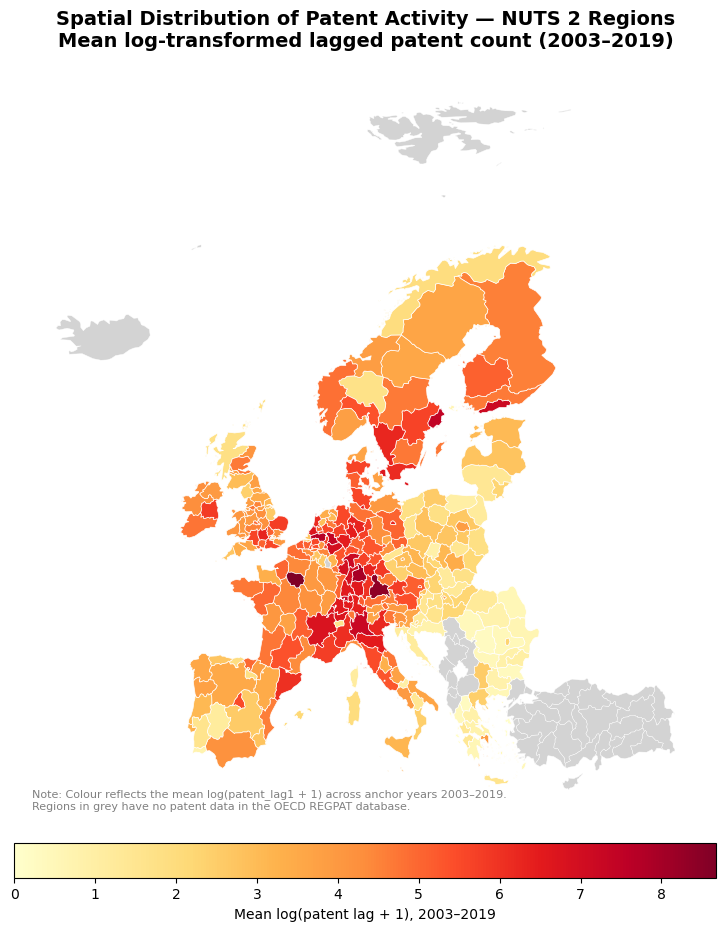

Map saved: patent_intensity_map.png


In [222]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

# ── 1. Calcular a média do log_patent_lag1 por região (2003–2019) ─────────
df_patent_map = (
    df_patents[df_patents["Year"].between(2003, 2019)]
    .assign(log_patent_lag1=lambda x: np.log1p(x["patent_lag1"]))
    .groupby("NUTS")["log_patent_lag1"]
    .mean()
    .reset_index()
    .rename(columns={"log_patent_lag1": "mean_log_patent"})
)

# ── 2. Carregar shapefile NUTS 2 ──────────────────────────────────────────
nuts2_url = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_20M_2021_4326_LEVL_2.geojson"
nuts2 = gpd.read_file(nuts2_url)[["NUTS_ID", "geometry"]]

nuts2_map = nuts2.merge(df_patent_map, left_on="NUTS_ID", right_on="NUTS", how="left")

# ── 3. Clip para a Europa continental ────────────────────────────────────
nuts2_eu = nuts2_map.cx[-25:45, 34:72]

# ── 4. Plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# Regiões sem dados a cinzento
nuts2_eu[nuts2_eu["mean_log_patent"].isna()].plot(
    ax=ax, color="#d3d3d3", linewidth=0.3, edgecolor="white"
)

# Regiões com dados
nuts2_eu[nuts2_eu["mean_log_patent"].notna()].plot(
    column="mean_log_patent",
    ax=ax,
    cmap="YlOrRd",
    linewidth=0.5,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label":       "Mean log(patent lag + 1), 2003–2019",
        "orientation": "horizontal",
        "shrink":      0.6,
        "pad":         0.02
    }
)

ax.set_title(
    "Spatial Distribution of Patent Activity — NUTS 2 Regions\n"
    "Mean log-transformed lagged patent count (2003–2019)",
    fontsize=14, fontweight="bold", pad=15
)
ax.set_axis_off()

ax.annotate(
    "Note: Colour reflects the mean log(patent_lag1 + 1) across anchor years 2003–2019.\n"
    "Regions in grey have no patent data in the OECD REGPAT database.",
    xy=(0.01, 0.02), xycoords="axes fraction",
    fontsize=8, color="grey"
)

plt.tight_layout()
plt.savefig("patent_intensity_map.png", dpi=200, bbox_inches="tight")
plt.show()
print("Map saved: patent_intensity_map.png")


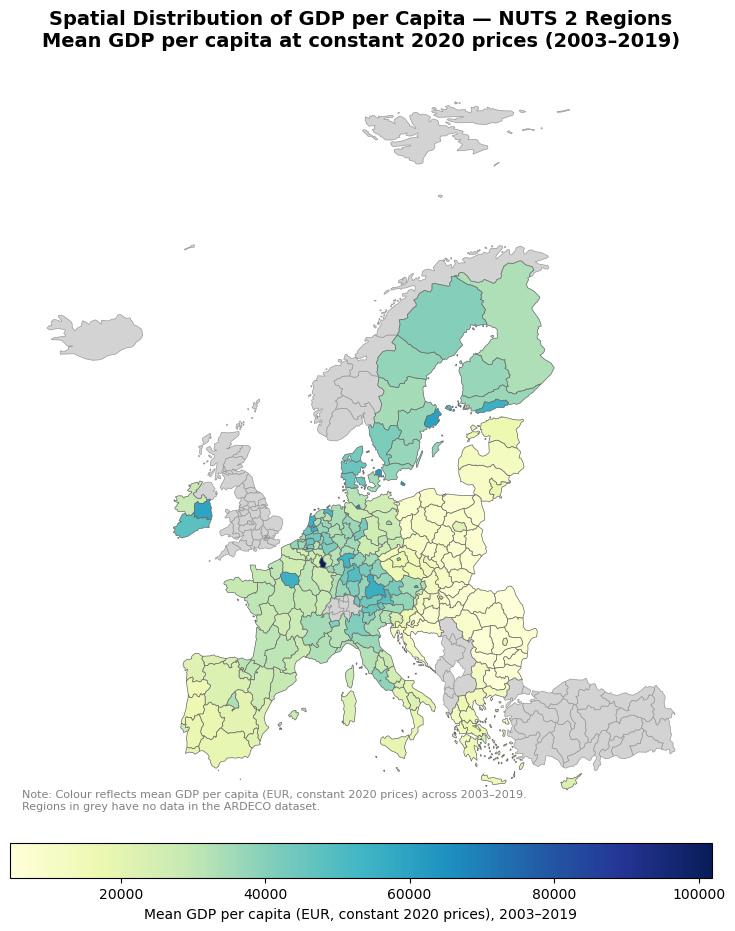

Map saved: gdp_pc_map.png


In [223]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

# ── 1. Compute mean GDP per capita per region (2003–2019) ─────────────────
df_gdp_map = (
    df_panel[df_panel["Year"].between(2003, 2019)]
    .groupby("NUTS")["GDP_per_capita"]
    .mean()
    .reset_index()
    .rename(columns={"GDP_per_capita": "mean_gdp_pc"})
)

# ── 2. Load NUTS 2 shapefile ──────────────────────────────────────────────
nuts2_url = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_20M_2021_4326_LEVL_2.geojson"
nuts2 = gpd.read_file(nuts2_url)[["NUTS_ID", "geometry"]]

nuts2_map = nuts2.merge(df_gdp_map, left_on="NUTS_ID", right_on="NUTS", how="left")

# ── 3. Clip to continental Europe ─────────────────────────────────────────
nuts2_eu = nuts2_map.cx[-25:45, 34:72]

# ── 4. Plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# Regions with no data — grey
nuts2_eu[nuts2_eu["mean_gdp_pc"].isna()].plot(
    ax=ax, color="#d3d3d3", linewidth=0.5, edgecolor="#999999"
)

# Regions with data
nuts2_eu[nuts2_eu["mean_gdp_pc"].notna()].plot(
    column="mean_gdp_pc",
    ax=ax,
    cmap="YlGnBu",
    linewidth=0.5,
    edgecolor="#666666",
    legend=True,
    legend_kwds={
        "label":       "Mean GDP per capita (EUR, constant 2020 prices), 2003–2019",
        "orientation": "horizontal",
        "shrink":      0.6,
        "pad":         0.02
    }
)

ax.set_title(
    "Spatial Distribution of GDP per Capita — NUTS 2 Regions\n"
    "Mean GDP per capita at constant 2020 prices (2003–2019)",
    fontsize=14, fontweight="bold", pad=15
)
ax.set_axis_off()

ax.annotate(
    "Note: Colour reflects mean GDP per capita (EUR, constant 2020 prices) across 2003–2019.\n"
    "Regions in grey have no data in the ARDECO dataset.",
    xy=(0.01, 0.02), xycoords="axes fraction",
    fontsize=8, color="grey"
)

plt.tight_layout()
plt.savefig("gdp_pc_map.png", dpi=200, bbox_inches="tight")
plt.show()
print("Map saved: gdp_pc_map.png")

###  mostrares um mapa das regiões europeias com o forecaste dos GDP growth para o futuro, 2 anos à frente do teu ultimo ano no dataset.

Regions with complete data in 2019 (within-transformed): 205
count    205.000000
mean       0.074266
std        2.523843
min       -9.465997
25%       -0.873554
50%        0.230164
75%        1.592049
max        4.228807
Name: gdp_growth_forecast, dtype: float64
Regions with negative forecast: 95


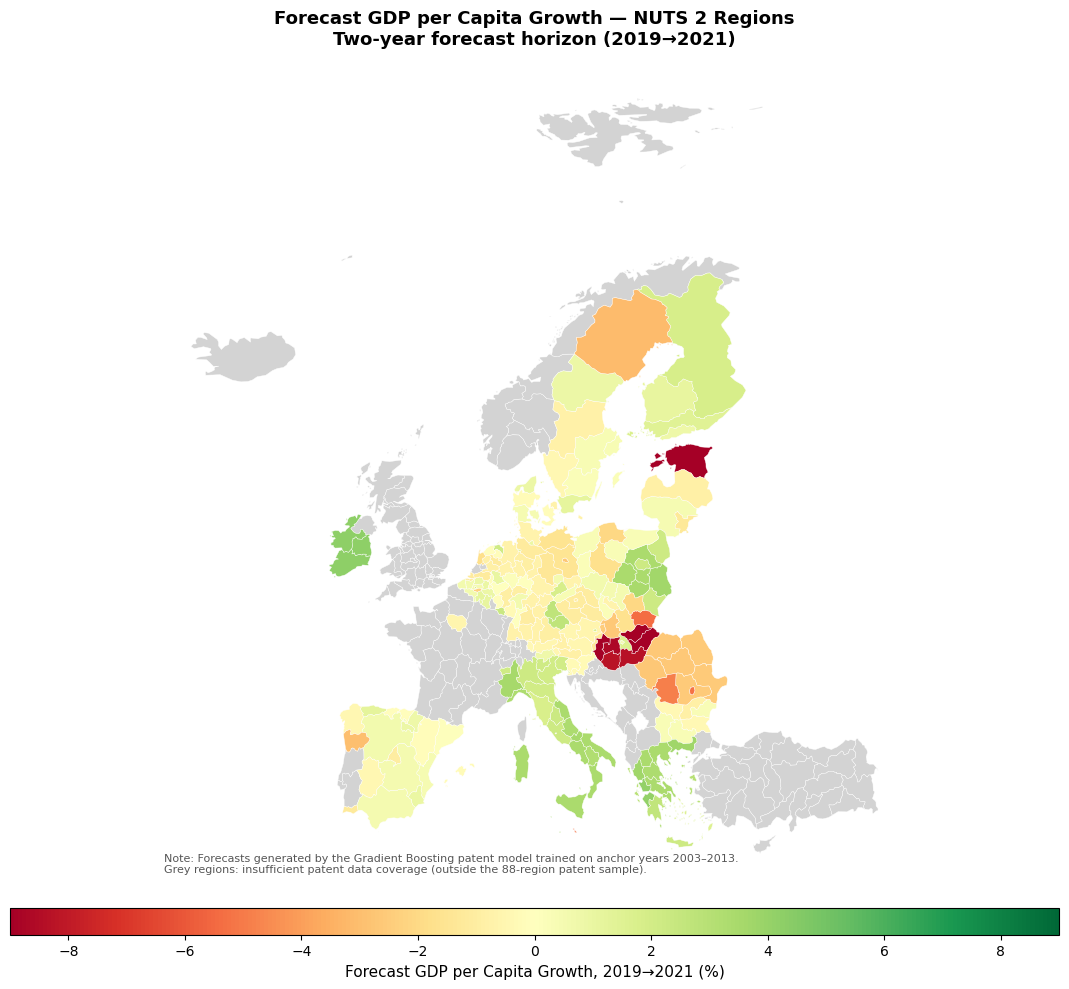

In [224]:
# ── FORECAST MAP: GB Patent Model, anchor year 2019 → forecast 2021 ──────

import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ── 1. Prepare input data for anchor year = 2019 ──────────────────────────
df_2019_base = df[df["Year"] == 2019][["NUTS", "Year"] + features_base].copy()

df_patents_2019 = df_patents[df_patents["Year"] == 2019][["NUTS", "patent_lag1"]].copy()
df_patents_2019["log_patent_lag1"] = np.log1p(df_patents_2019["patent_lag1"])

df_2019_raw = df_2019_base.merge(df_patents_2019[["NUTS", "log_patent_lag1"]],
                                  on="NUTS", how="inner").dropna().copy()

# Apply within-transformation using the full patent panel means
df_2019_raw["gdp_pc_growth"] = np.nan
df_for_transform = pd.concat([
    df_pat[["NUTS", "Year"] + features_pat_log + ["gdp_pc_growth"]],
    df_2019_raw[["NUTS", "Year"] + features_pat_log + ["gdp_pc_growth"]]
], ignore_index=True)

df_transformed = within_transform(df_for_transform, features_pat_log)

df_2019_w = df_transformed[df_transformed["Year"] == 2019][["NUTS"] + features_pat_log].dropna().copy()

print(f"Regions with complete data in 2019 (within-transformed): {len(df_2019_w)}")

# ── 2. Generate forecast ──────────────────────────────────────────────────
y_forecast_2021 = best_gb_pat_l.predict(df_2019_w[features_pat_log])

df_forecast_2021 = pd.DataFrame({
    "NUTS_ID":             df_2019_w["NUTS"].values,
    "gdp_growth_forecast": y_forecast_2021
})

print(df_forecast_2021["gdp_growth_forecast"].describe())
print("Regions with negative forecast:", (df_forecast_2021["gdp_growth_forecast"] < 0).sum())

# ── 3. Load NUTS 2 shapefile ──────────────────────────────────────────────
nuts2_url = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_20M_2021_4326_LEVL_2.geojson"
nuts2 = gpd.read_file(nuts2_url)
nuts2 = nuts2[["NUTS_ID", "geometry"]]

nuts2_map = nuts2.merge(df_forecast_2021, on="NUTS_ID", how="left")
nuts2_eu  = nuts2_map.cx[-25:45, 34:72]

# ── 4. Symmetric scale centred on 0 ───────────────────────────────────────
vmax = round(max(
    abs(df_forecast_2021["gdp_growth_forecast"].min()),
    df_forecast_2021["gdp_growth_forecast"].max()
), 0)

# ── 5. Plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

nuts2_eu[nuts2_eu["gdp_growth_forecast"].isna()].plot(
    ax=ax, color="#d3d3d3", linewidth=0.3, edgecolor="white"
)
nuts2_eu[nuts2_eu["gdp_growth_forecast"].notna()].plot(
    column="gdp_growth_forecast",
    ax=ax,
    cmap="RdYlGn",
    vmin=-vmax, vmax=vmax,
    linewidth=0.3, edgecolor="white"
)

# ── 6. Colorbar ───────────────────────────────────────────────────────────
sm = plt.cm.ScalarMappable(cmap="RdYlGn",
                            norm=mcolors.Normalize(vmin=-vmax, vmax=vmax))
sm._A = []
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal",
                    fraction=0.03, pad=0.02, aspect=40)
cbar.set_label("Forecast GDP per Capita Growth, 2019→2021 (%)", fontsize=11)

# ── 7. Title and note ─────────────────────────────────────────────────────
ax.set_title(
    "Forecast GDP per Capita Growth — NUTS 2 Regions\n"
    "Two-year forecast horizon (2019→2021)",
    fontsize=13, fontweight="bold", pad=12
)
ax.text(
    0.01, 0.02,
    "Note: Forecasts generated by the Gradient Boosting patent model trained on anchor years 2003–2013.\n"
    "Grey regions: insufficient patent data coverage (outside the 88-region patent sample).",
    transform=ax.transAxes,
    fontsize=8, color="#555555", va="bottom"
)
ax.set_axis_off()
plt.tight_layout()
plt.savefig("forecast_map_2021.png", dpi=150, bbox_inches="tight")
plt.show()

Regions with complete data in 2019 (demeaned): 189
count    189.000000
mean      -2.921734
std        4.251608
min      -12.479275
25%       -3.754247
50%       -2.205487
75%       -0.462222
max        4.160289
Name: gdp_growth_forecast, dtype: float64
Regions with negative forecast: 149


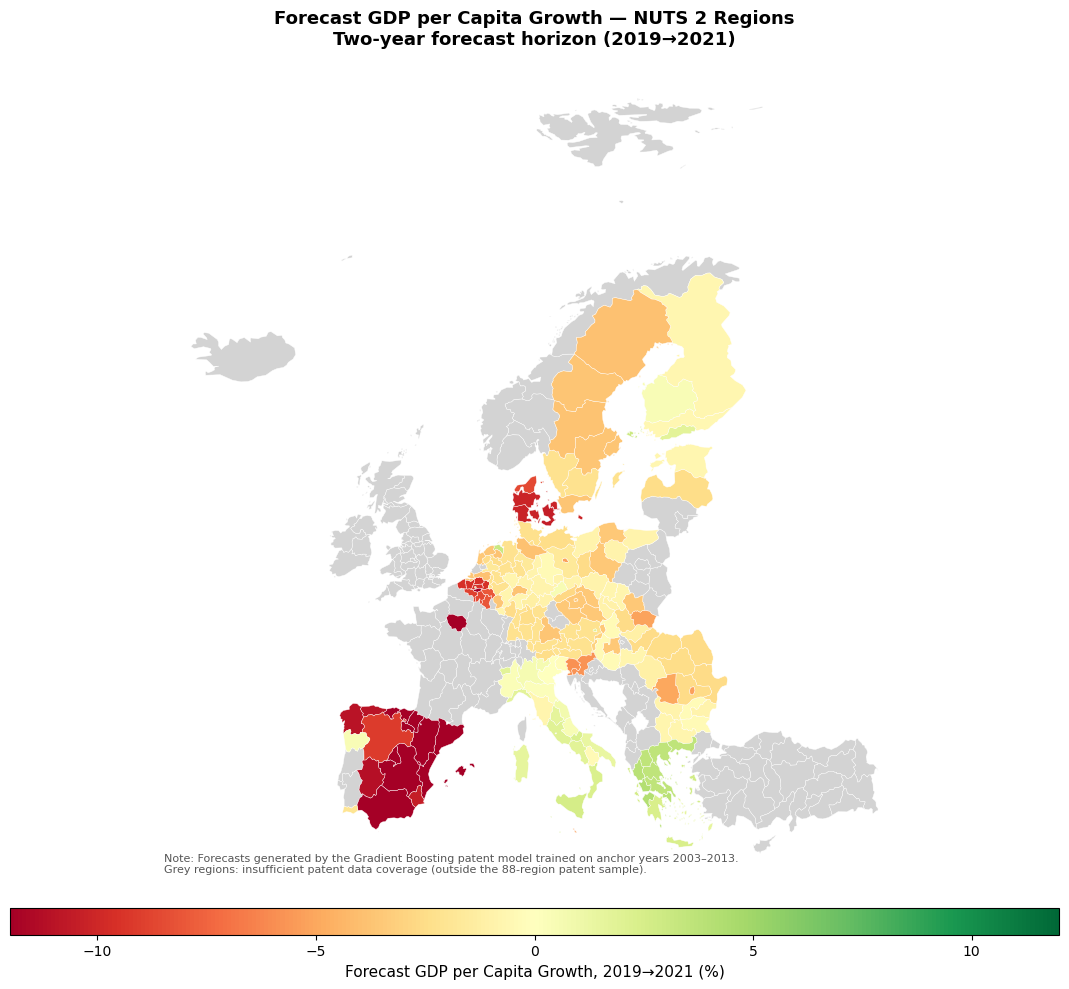

In [225]:
# ── FORECAST MAP: GB Patent Model, anchor year 2019 → forecast 2021 ──────

import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ── 1. Prepare input data for anchor year = 2019 ──────────────────────────
df_2019_base = df[df["Year"] == 2019][["NUTS", "Year"] + features_base].copy()

df_patents_2019 = df_patents[df_patents["Year"] == 2019][["NUTS", "patent_lag1"]].copy()
df_patents_2019["log_patent_lag1"] = np.log1p(df_patents_2019["patent_lag1"])

df_2019_raw = df_2019_base.merge(df_patents_2019[["NUTS", "log_patent_lag1"]],
                                  on="NUTS", how="inner").dropna().copy()

# Demean using training set (anchor years <= 2013) unit and time means
train_means = df_pat[df_pat["Year"] <= 2013].copy()

unit_means  = train_means.groupby("NUTS")[features_pat_log].mean()
time_means  = train_means.groupby("Year")[features_pat_log].mean()
grand_means = train_means[features_pat_log].mean()

df_2019_w = df_2019_raw[["NUTS"] + features_pat_log].copy()

for col in features_pat_log:
    df_2019_w[col] = (
        df_2019_raw[col].values
        - df_2019_raw["NUTS"].map(unit_means[col]).values
        - time_means.loc[2013, col]   # use last training year time mean
        + grand_means[col]
    )

df_2019_w = df_2019_w.dropna()
print(f"Regions with complete data in 2019 (demeaned): {len(df_2019_w)}")

# ── 2. Generate forecast ──────────────────────────────────────────────────
y_forecast_2021 = best_gb_pat_l.predict(df_2019_w[features_pat_log])

df_forecast_2021 = pd.DataFrame({
    "NUTS_ID":             df_2019_w["NUTS"].values,
    "gdp_growth_forecast": y_forecast_2021
})

print(df_forecast_2021["gdp_growth_forecast"].describe())
print("Regions with negative forecast:", (df_forecast_2021["gdp_growth_forecast"] < 0).sum())

# ── 3. Load NUTS 2 shapefile ──────────────────────────────────────────────
nuts2_url = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_20M_2021_4326_LEVL_2.geojson"
nuts2 = gpd.read_file(nuts2_url)
nuts2 = nuts2[["NUTS_ID", "geometry"]]

nuts2_map = nuts2.merge(df_forecast_2021, on="NUTS_ID", how="left")
nuts2_eu  = nuts2_map.cx[-25:45, 34:72]

# ── 4. Symmetric scale centred on 0 ───────────────────────────────────────
vmax = round(max(
    abs(df_forecast_2021["gdp_growth_forecast"].min()),
    df_forecast_2021["gdp_growth_forecast"].max()
), 0)

# ── 5. Plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

nuts2_eu[nuts2_eu["gdp_growth_forecast"].isna()].plot(
    ax=ax, color="#d3d3d3", linewidth=0.3, edgecolor="white"
)
nuts2_eu[nuts2_eu["gdp_growth_forecast"].notna()].plot(
    column="gdp_growth_forecast",
    ax=ax,
    cmap="RdYlGn",
    vmin=-vmax, vmax=vmax,
    linewidth=0.3, edgecolor="white"
)

# ── 6. Colorbar ───────────────────────────────────────────────────────────
sm = plt.cm.ScalarMappable(cmap="RdYlGn",
                            norm=mcolors.Normalize(vmin=-vmax, vmax=vmax))
sm._A = []
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal",
                    fraction=0.03, pad=0.02, aspect=40)
cbar.set_label("Forecast GDP per Capita Growth, 2019→2021 (%)", fontsize=11)

# ── 7. Title and note ─────────────────────────────────────────────────────
ax.set_title(
    "Forecast GDP per Capita Growth — NUTS 2 Regions\n"
    "Two-year forecast horizon (2019→2021)",
    fontsize=13, fontweight="bold", pad=12
)
ax.text(
    0.01, 0.02,
    "Note: Forecasts generated by the Gradient Boosting patent model trained on anchor years 2003–2013.\n"
    "Grey regions: insufficient patent data coverage (outside the 88-region patent sample).",
    transform=ax.transAxes,
    fontsize=8, color="#555555", va="bottom"
)
ax.set_axis_off()
plt.tight_layout()
plt.savefig("forecast_map_2021.png", dpi=150, bbox_inches="tight")
plt.show()

### Significance

In [226]:
# ============================================================
# DIEBOLD-MARIANO TEST — Δ=2 Baseline Models
# ============================================================
from scipy import stats
import pandas as pd
import numpy as np

# --- 1. Construir dataframes com erros de previsão individuais ---

# Naïve Persistence Baseline
df_dm_naive = df_ar_test[["NUTS", "Year", "gdp_pc_growth", "pred_ar"]].copy()
df_dm_naive["e_naive"] = df_dm_naive["gdp_pc_growth"] - df_dm_naive["pred_ar"]

# Linear Regression
df_dm_lr = df_lr_test[["NUTS", "Year", "gdp_pc_growth", "pred_lr"]].copy()
df_dm_lr["e_lr"] = df_dm_lr["gdp_pc_growth"] - df_dm_lr["pred_lr"]

# Random Forest — reconstruir com NUTS e Year
df_dm_rf = test_w[["NUTS", "Year", "gdp_pc_growth"]].copy()
df_dm_rf["pred_rf"] = pred_rf
df_dm_rf["e_rf"] = df_dm_rf["gdp_pc_growth"] - df_dm_rf["pred_rf"]

# Gradient Boosting
df_dm_gb = test_w[["NUTS", "Year", "gdp_pc_growth"]].copy()
df_dm_gb["pred_gb"] = pred_gb
df_dm_gb["e_gb"] = df_dm_gb["gdp_pc_growth"] - df_dm_gb["pred_gb"]

# --- 2. Alinhar pelo conjunto comum de observações (NUTS x Year) ---

df_dm = (df_dm_naive[["NUTS", "Year", "e_naive"]]
         .merge(df_dm_lr[["NUTS", "Year", "e_lr"]],     on=["NUTS", "Year"])
         .merge(df_dm_rf[["NUTS", "Year", "e_rf"]],     on=["NUTS", "Year"])
         .merge(df_dm_gb[["NUTS", "Year", "e_gb"]],     on=["NUTS", "Year"]))

print(f"Observações comuns para DM test (Δ=2): {len(df_dm)}")

# --- 3. Função DM test ---

def dm_test(e1, e2, h=2):
    """
    Diebold-Mariano test (two-sided).
    e1, e2: forecast error arrays (actual - predicted)
    h: forecast horizon
    Null hypothesis: equal predictive accuracy
    Positive DM stat: e1 has larger loss than e2 (e2 is better)
    """
    d = e1**2 - e2**2  # squared error loss differential
    T = len(d)
    d_bar = np.mean(d)
    gamma0 = np.var(d, ddof=1)
    if h > 1:
        gammas = [np.cov(d[k:], d[:-k])[0, 1] for k in range(1, h)]
        var_d = (gamma0 + 2 * sum(gammas)) / T
    else:
        var_d = gamma0 / T
    dm_stat = d_bar / np.sqrt(var_d)
    p_val = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return round(dm_stat, 4), round(p_val, 4)

# --- 4. Correr os testes ---

e_naive = df_dm["e_naive"].values
e_lr    = df_dm["e_lr"].values
e_rf    = df_dm["e_rf"].values
e_gb    = df_dm["e_gb"].values

results = {
    "Naïve vs LR":  dm_test(e_naive, e_lr),
    "Naïve vs RF":  dm_test(e_naive, e_rf),
    "Naïve vs GB":  dm_test(e_naive, e_gb),
    "LR vs RF":     dm_test(e_lr,    e_rf),
    "LR vs GB":     dm_test(e_lr,    e_gb),
    "RF vs GB":     dm_test(e_rf,    e_gb),
}

df_results = pd.DataFrame(results, index=["DM Statistic", "p-value"]).T
df_results["Significant (5%)"] = df_results["p-value"] < 0.05
print("\nDiebold-Mariano Test Results — Δ=2 Baseline")
print(df_results.to_string())

Observações comuns para DM test (Δ=2): 396

Diebold-Mariano Test Results — Δ=2 Baseline
             DM Statistic  p-value  Significant (5%)
Naïve vs LR        6.4446   0.0000              True
Naïve vs RF        4.6280   0.0000              True
Naïve vs GB        5.1952   0.0000              True
LR vs RF          -4.0415   0.0001              True
LR vs GB          -3.7627   0.0002              True
RF vs GB           2.3023   0.0213              True


In [227]:
# ============================================================
# DIEBOLD-MARIANO TEST — Δ=1 Baseline Models
# ============================================================

# --- 1. Construir dataframes com erros de previsão individuais ---

# Naïve Persistence Baseline
df_dm_naive_h1 = df_ar_test_h1[["NUTS", "Year", "gdp_pc_growth", "pred_ar"]].copy()
df_dm_naive_h1["e_naive"] = df_dm_naive_h1["gdp_pc_growth"] - df_dm_naive_h1["pred_ar"]

# Linear Regression
df_dm_lr_h1 = test_w_h1[["NUTS", "Year", "gdp_pc_growth"]].copy()
df_dm_lr_h1["pred_lr"] = pred_lr_h1.values
df_dm_lr_h1["e_lr"] = df_dm_lr_h1["gdp_pc_growth"] - df_dm_lr_h1["pred_lr"]

# Random Forest
df_dm_rf_h1 = test_w_h1[["NUTS", "Year", "gdp_pc_growth"]].copy()
df_dm_rf_h1["pred_rf"] = best_rf_h1.predict(X_test_rf_h1)
df_dm_rf_h1["e_rf"] = df_dm_rf_h1["gdp_pc_growth"] - df_dm_rf_h1["pred_rf"]

# Gradient Boosting
df_dm_gb_h1 = test_w_h1[["NUTS", "Year", "gdp_pc_growth"]].copy()
df_dm_gb_h1["pred_gb"] = best_gb_h1.predict(X_test_rf_h1)
df_dm_gb_h1["e_gb"] = df_dm_gb_h1["gdp_pc_growth"] - df_dm_gb_h1["pred_gb"]

# --- 2. Alinhar pelo conjunto comum de observações (NUTS x Year) ---

df_dm_h1 = (df_dm_naive_h1[["NUTS", "Year", "e_naive"]]
            .merge(df_dm_lr_h1[["NUTS", "Year", "e_lr"]],  on=["NUTS", "Year"])
            .merge(df_dm_rf_h1[["NUTS", "Year", "e_rf"]],  on=["NUTS", "Year"])
            .merge(df_dm_gb_h1[["NUTS", "Year", "e_gb"]],  on=["NUTS", "Year"]))

print(f"Observações comuns para DM test (Δ=1): {len(df_dm_h1)}")

# --- 3. Correr os testes (reutiliza a função dm_test definida acima) ---

e_naive_h1 = df_dm_h1["e_naive"].values
e_lr_h1    = df_dm_h1["e_lr"].values
e_rf_h1    = df_dm_h1["e_rf"].values
e_gb_h1    = df_dm_h1["e_gb"].values

results_h1 = {
    "Naïve vs LR": dm_test(e_naive_h1, e_lr_h1, h=1),
    "Naïve vs RF": dm_test(e_naive_h1, e_rf_h1, h=1),
    "Naïve vs GB": dm_test(e_naive_h1, e_gb_h1, h=1),
    "LR vs RF":    dm_test(e_lr_h1,    e_rf_h1, h=1),
    "LR vs GB":    dm_test(e_lr_h1,    e_gb_h1, h=1),
    "RF vs GB":    dm_test(e_rf_h1,    e_gb_h1, h=1),
}

df_results_h1 = pd.DataFrame(results_h1, index=["DM Statistic", "p-value"]).T
df_results_h1["Significant (5%)"] = df_results_h1["p-value"] < 0.05
print("\nDiebold-Mariano Test Results — Δ=1 Baseline")
print(df_results_h1.to_string())

Observações comuns para DM test (Δ=1): 196

Diebold-Mariano Test Results — Δ=1 Baseline
             DM Statistic  p-value  Significant (5%)
Naïve vs LR        6.0096   0.0000              True
Naïve vs RF        4.8638   0.0000              True
Naïve vs GB        6.9353   0.0000              True
LR vs RF          -2.8737   0.0041              True
LR vs GB          -2.4686   0.0136              True
RF vs GB           2.2685   0.0233              True
